# Activity Level Prediction: In-depth EDA, cleaning, preprocessing pipeline and baselines (Phases 1A-1C)

## Problem statement
ElderGuard Analytics wants a **non-invasive early-warning system** that predicts potential health emergencies or concerning situations for elderly residents living independently, using environmental sensor data and indoor air quality monitoring (CO2, CO and metal-oxide gas sensors, temperature, humidity, HVAC mode, lighting). It should help identify when a resident may be experiencing distress, a medical episode or unsafe living conditions, supporting family members and healthcare providers.

**The task as given (unchanged):** build and evaluate at least three models that classify the resident's `Activity Level` (Low / Moderate / High) from the sensor data, and identify the features that contribute most. Activity level is the proxy signal for the resident's state.

**Illustrative link to health situations (domain context, not validated by this data):** *Low* activity for long periods can accompany a fall, fainting, stroke, acute illness or withdrawal; *High* activity at unusual times can accompany agitation, confusion/delirium, wandering or pain/breathing distress; *Moderate* is the expected routine, and the concern is a departure from the resident's own baseline. Air-quality readings (CO, CO2, temperature) additionally indicate unsafe living conditions, but no label exists for them here.

**Assumptions and limitations of the framing:** the model *recognises* the current activity level (it does not forecast an emergency); there are no emergency labels, so activity is an untested proxy; the data do not say which level is the "alert" class; `Session ID` is a collection session, not necessarily a resident; the data may be synthetic or contaminated, so every repair is an assumption stated below.

**Goal of this notebook.** Understand the data well enough to decide target handling, cleaning rules, leakage exclusions, features and the realistic ceiling of predictability, before any modelling.

**Method.** Every section states its purpose, runs real code, and ends with an *Observation / implication* cell written after seeing the output. Target = `Activity Level` (3 classes), problem = imbalanced multi-class classification, rows grouped in 38 sessions.

**Contents.** 1 overview | 2 data quality (missingness, duplicates, structure, impossible values, sentinels, consistency, hidden clock, leakage audit) | 3 descriptive statistics | 4 univariate | 5 bivariate (correlation, non-monotonic, per-class) | 6 categorical effects | 7 interactions | 8 outliers | 9 session structure | 10 feature engineering | 11 predictability ceiling | 12 synthesis (including what it means for the problem statement) | Glossary. **Part B (sections 13-23)** turns the EDA decisions into a leak-free preprocessing pipeline, a model registry and default-parameter baselines. **Part C (sections 24-40)** tunes every model, selects by a pre-declared rule and evaluates the test set once.

## 0. Setup
**Purpose.** Imports, **self-contained constants/loader/cleaner (the notebook needs only `data/gas_monitoring.db`)**, helper functions for effect sizes, and the working frames: `raw` (database as stored), `d` (labels normalised, exact duplicates dropped) and `C` (stateless cleaning applied: Kelvin to Celsius, impossible values to NaN, ordinal codes).

In [1]:
import sys, warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier as HGB, IsolationForest
from sklearn.model_selection import cross_val_score, cross_validate, StratifiedKFold, GroupKFold, learning_curve
from sklearn.metrics import mutual_info_score, roc_auc_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
import sqlite3, time
from sklearn.base import BaseEstimator, TransformerMixin, clone
sns.set_theme(style="whitegrid", context="notebook"); pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 80)
# ---- constants and loading (self-contained: only needs data/gas_monitoring.db, no project modules) ----
DB_PATH, TABLE, SEED = "data/gas_monitoring.db", "gas_monitoring", 42
TARGET, GROUP = "Activity Level", "Session ID"
MOS_COLUMNS = [f"MetalOxideSensor_Unit{i}" for i in range(1, 5)]
ORDINAL_MAPS = {"CO_GasSensor": ["extremely low", "low", "medium", "high", "extremely high"],
                "Ambient Light Level": ["very_dim", "dim", "moderate", "bright", "very_bright"]}

def normalise_target(series):
    """'Low Activity', 'LowActivity', 'Low_Activity' -> 'Low' (same for Moderate / High)."""
    return series.astype(str).str.replace(r"[\s_]*[Aa]ctivity$", "", regex=True).str.strip()

def load_raw():
    with sqlite3.connect(DB_PATH) as con:
        return pd.read_sql(f"SELECT * FROM {TABLE}", con)

def prepare_rows(df):
    """Row-level steps that use no statistics: normalise labels, drop exact duplicates."""
    df = df.copy(); df[TARGET] = normalise_target(df[TARGET]); return df.drop_duplicates().reset_index(drop=True)

class DataCleaner(BaseEstimator, TransformerMixin):
    """Stateless column-level fixes: K->C, impossible values -> NaN, lower-case HVAC, ordinal codes, missing flags, drop IDs."""
    def __init__(self, drop_columns=("Session ID",), kelvin_threshold=100, humidity_range=(0, 100), co2_infrared_min=0,
                 ordinal_maps=None, add_missing_indicators=True, indicator_columns=()):
        self.drop_columns = drop_columns; self.kelvin_threshold = kelvin_threshold; self.humidity_range = humidity_range
        self.co2_infrared_min = co2_infrared_min; self.ordinal_maps = ordinal_maps
        self.add_missing_indicators = add_missing_indicators; self.indicator_columns = indicator_columns
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy(); k = X["Temperature"] > self.kelvin_threshold
        X.loc[k, "Temperature"] = X.loc[k, "Temperature"] - 273.15
        lo, hi = self.humidity_range; X.loc[(X["Humidity"] < lo) | (X["Humidity"] > hi), "Humidity"] = np.nan
        X.loc[X["CO2_InfraredSensor"] < self.co2_infrared_min, "CO2_InfraredSensor"] = np.nan
        X["HVAC Operation Mode"] = X["HVAC Operation Mode"].astype(str).str.strip().str.lower()
        for col, order in (self.ordinal_maps or {}).items():
            X[col] = X[col].map({v: i for i, v in enumerate(order)}).astype(float)   # unseen level -> NaN
        if self.add_missing_indicators:
            for col in self.indicator_columns: X[f"{col}__missing"] = X[col].isna().astype(int)
        return X.drop(columns=[c for c in self.drop_columns if c in X.columns])

raw = load_raw()
ORDER = ["Low", "Moderate", "High"]; PAL = {"Low": "#6baed6", "Moderate": "#fd8d3c", "High": "#d62728"}
NUM = ["Temperature", "Humidity", "CO2_InfraredSensor", "CO2_ElectroChemicalSensor"] + MOS_COLUMNS
ORD = ["CO_GasSensor", "Ambient Light Level"]; CAT = ["Time of Day", "HVAC Operation Mode"]; MOS = MOS_COLUMNS

def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))
def eta_sq(x, g):
    x = pd.Series(x); g = pd.Series(np.asarray(g), index=x.index); m = x.notna(); x, g = x[m], g[m]
    gm = x.groupby(g).transform("mean"); return float(((gm - x.mean()) ** 2).sum() / ((x - x.mean()) ** 2).sum())
def rank_biserial(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float); a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    u = stats.mannwhitneyu(a, b, alternative="two-sided")[0]; return float(2 * u / (len(a) * len(b)) - 1)
def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float); a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)); return float((a.mean() - b.mean()) / sp)

d = prepare_rows(raw)
y = d[TARGET]; code = y.map({"Low": 0, "Moderate": 1, "High": 2}).astype(float); sess = d[GROUP]
cleaner = DataCleaner(drop_columns=(), ordinal_maps=ORDINAL_MAPS, add_missing_indicators=False)
C = cleaner.transform(d.drop(columns=[TARGET]))
print("raw", raw.shape, "| d (labels normalised, exact duplicates dropped)", d.shape, "| C", C.shape)

raw (10000, 14) | d (labels normalised, exact duplicates dropped) (9840, 14) | C (9840, 13)


**Observation.** The working frames are consistent: 10,000 raw rows, 9,840 after normalising the label spellings and dropping exact duplicates, and `C` carries the same stateless repairs the pipeline applies. An independent pandas recomputation (outside the helpers) reproduced the key numbers: 9,840 rows, class counts 5,694 / 3,070 / 1,076, 804 Kelvin temperatures, eta-squared of MOS Unit4 = 0.1575, Cramer's V of CO_GasSensor = 0.2324 and the CO2-sensor Spearman = -0.481.

## 1. Data overview
**Purpose.** Shape, dtypes, first rows, problem type, and the class balance / session structure of the target.

In [2]:
print("shape:", raw.shape); display(raw.head(5)); display(raw.dtypes.astype(str).to_frame("dtype").T)
print("\nRaw target spellings:"); print(raw[TARGET].value_counts().to_string())
print("\nNormalised target:"); vc = y.value_counts().reindex(ORDER); print(pd.DataFrame({"n": vc, "share": (vc / vc.sum()).round(3)}).to_string())
print("\nProblem type: 3-class classification (ordered Low < Moderate < High), imbalanced; majority-class accuracy =", round(vc.max() / vc.sum(), 3), "| uniform-guess macro PR AUC ~ 1/3")
rps = d.groupby(GROUP).size(); print(f"\nsessions: {d[GROUP].nunique()} | rows per session: min {rps.min()}, median {int(rps.median())}, max {rps.max()}")

shape: (10000, 14)


,Time of Day,Temperature,Humidity,CO2_InfraredSensor,CO2_ElectroChemicalSensor,MetalOxideSensor_Unit1,MetalOxideSensor_Unit2,MetalOxideSensor_Unit3,MetalOxideSensor_Unit4,CO_GasSensor,Session ID,HVAC Operation Mode,Ambient Light Level,Activity Level
0,morning,19.63,53.83,125.49,571.09,478.55,735.85,497.59,565.05,medium,7241,off,very_dim,Low Activity
1,morning,19.66,53.69,126.34,575.79,491.96,740.28,NaN,557.08,low,7241,ventilation_only,bright,Low Activity
2,night,20.95,54.12,119.34,556.53,437.50,718.34,NaN,612.62,medium,9385,off,NaN,Low Activity
3,morning,20.10,50.48,113.50,NaN,515.14,744.02,676.15,600.22,low,7241,eco_mode,very_bright,High Activity
4,morning,19.89,48.42,92.77,613.65,535.66,770.27,720.27,625.73,low,7241,Heating_active,moderate,Low Activity


,Time of Day,Temperature,Humidity,CO2_InfraredSensor,CO2_ElectroChemicalSensor,MetalOxideSensor_Unit1,MetalOxideSensor_Unit2,MetalOxideSensor_Unit3,MetalOxideSensor_Unit4,CO_GasSensor,Session ID,HVAC Operation Mode,Ambient Light Level,Activity Level
dtype,str,float64,float64,float64,float64,float64,float64,float64,float64,str,int64,str,str,str



Raw target spellings:
Activity Level
Low Activity         5231
Moderate Activity    2808
High Activity        1088
ModerateActivity      307
LowActivity           293
Low_Activity          273

Normalised target:
                   n  share
Activity Level             
Low             5694  0.579
Moderate        3070  0.312
High            1076  0.109

Problem type: 3-class classification (ordered Low < Moderate < High), imbalanced; majority-class accuracy = 0.579 | uniform-guess macro PR AUC ~ 1/3

sessions: 38 | rows per session: min 58, median 255, max 375


**Observation / implication.** 10,000 rows x 14 columns, one SQLite table, 38 sessions with 58-375 rows each. The target `Activity Level` is stored under **6 spellings** of 3 classes: Low 5,694 (57.9%), Moderate 3,070 (31.2%), High 1,076 (10.9%) after cleaning. The problem is therefore **3-class, imbalanced classification**; always answering 'Low' is 57.9% accurate, and a uniform-prior model scores a macro PR AUC of about 1/3. The names suggest an order Low < Moderate < High, but section 5 will show that the sensors do **not** follow that order (they peak at Moderate), so an ordinal-regression framing is not justified.

## 2a. Data quality: missing values and informative missingness
**Purpose.** Count missing values and test whether *being missing* is related to the target (informative missingness).

In [3]:
n_miss = raw.isna().sum(); print(pd.DataFrame({"n_missing": n_miss, "pct": (100 * n_miss / len(raw)).round(1)}).query("n_missing > 0").to_string())
rows = []
for c in [c for c in d.columns if d[c].isna().any()]:
    m = d[c].isna(); ct = pd.crosstab(m, y)[ORDER]; chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append({"column": c, "pct_missing": round(100 * m.mean(), 1), "cramers_V": round(cramers_v(ct), 4), "chi2_p": round(p, 3),
                 "P(Low|missing)": (y[m] == "Low").mean(), "P(Low|present)": (y[~m] == "Low").mean(),
                 "P(High|missing)": (y[m] == "High").mean(), "P(High|present)": (y[~m] == "High").mean()})
M = pd.DataFrame(rows).set_index("column"); display(M.round(3))

                           n_missing   pct
CO2_ElectroChemicalSensor        706   7.1
MetalOxideSensor_Unit3          2566  25.7
CO_GasSensor                    1369  13.7
Ambient Light Level             2532  25.3


,pct_missing,cramers_V,chi2_p,P(Low|missing),P(Low|present),P(High|missing),P(High|present)
column,,,,,,,
CO2_ElectroChemicalSensor,7.2,0.003,0.965,0.582,0.578,0.106,0.110
MetalOxideSensor_Unit3,25.9,0.009,0.688,0.573,0.581,0.108,0.110
CO_GasSensor,13.9,0.015,0.331,0.597,0.576,0.104,0.110
Ambient Light Level,25.6,0.008,0.712,0.582,0.578,0.105,0.111


**Observation / implication.** Four columns have missing values: MetalOxideSensor_Unit3 25.7%, Ambient Light Level 25.3%, CO_GasSensor 13.7% and CO2_ElectroChemicalSensor 7.1%. **Missingness is not informative about the target**: Cramer's V is at most 0.015 (p between 0.33 and 0.97), and P(Low|missing) vs P(Low|present) differ by at most 2 percentage points (CO_GasSensor 0.597 vs 0.576). No other column has missing values in the raw table; the repair rules of section 2e create more.

## 2b. Is the missingness MCAR? (relation to other columns and to sessions)
**Purpose.** If missingness depends on other columns or on the session, it is not completely random. Effect size = rank-biserial correlation of another feature between missing and present rows (0 = no relation).

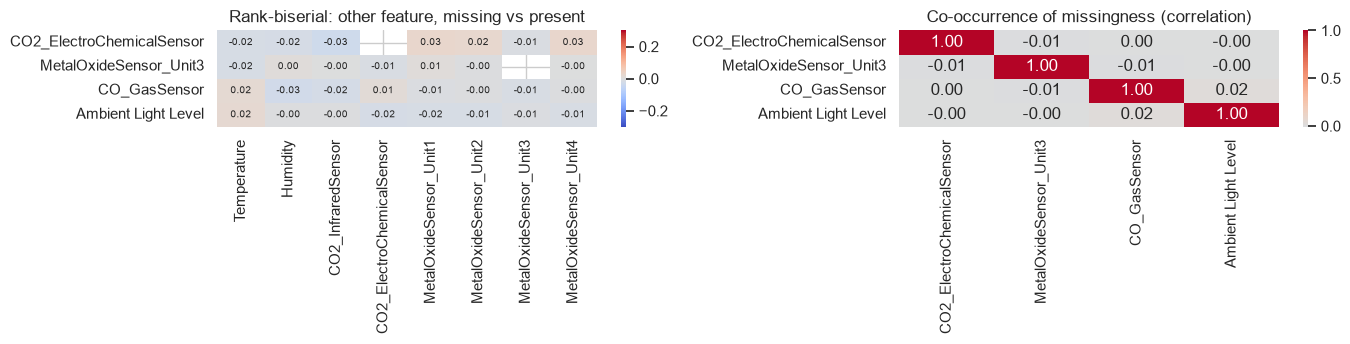

max |rank-biserial| = 0.031 | min Mann-Whitney p = 0.11521677185446703
Cramer's V of missingness vs categoricals and Session ID:


,Time of Day,HVAC Operation Mode,Session ID
column,,,
CO2_ElectroChemicalSensor,0.017,0.049,0.056
MetalOxideSensor_Unit3,0.016,0.058,0.051
CO_GasSensor,0.013,0.053,0.071
Ambient Light Level,0.031,0.048,0.071


In [4]:
miss_cols = [c for c in d.columns if d[c].isna().any()]
rb = pd.DataFrame(index=miss_cols, columns=NUM, dtype=float); pv = rb.copy()
for c in miss_cols:
    m = d[c].isna()
    for o in NUM:
        if o == c: continue
        a, b = C.loc[m, o].dropna(), C.loc[~m, o].dropna()
        rb.loc[c, o] = rank_biserial(a, b); pv.loc[c, o] = stats.mannwhitneyu(a, b)[1]
cv_rows = []
for c in miss_cols:
    m = d[c].isna()
    cv_rows.append({"column": c, **{k: round(cramers_v(pd.crosstab(m, d[k].fillna("missing"))), 3) for k in CAT + [GROUP]}})
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
sns.heatmap(rb.astype(float), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.3, vmax=0.3, ax=ax[0], annot_kws={"size": 7}); ax[0].set_title("Rank-biserial: other feature, missing vs present")
ind = pd.DataFrame({c: d[c].isna().astype(int) for c in miss_cols}); sns.heatmap(ind.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("Co-occurrence of missingness (correlation)")
plt.tight_layout(); plt.show()
print("max |rank-biserial| =", round(float(rb.abs().max().max()), 3), "| min Mann-Whitney p =", float(pv.min().min()))
print("Cramer's V of missingness vs categoricals and Session ID:"); display(pd.DataFrame(cv_rows).set_index("column"))

**Observation / implication.** Missingness looks **MCAR**: the largest rank-biserial effect of any other feature between missing and present rows is 0.031 (minimum Mann-Whitney p = 0.12, i.e. nothing is distinguishable after 28 comparisons), and the Cramer's V values against Time of Day (<= 0.031), HVAC mode (<= 0.058) and Session ID (<= 0.071) are negligible. The four missingness indicators are essentially uncorrelated with each other (heatmap right). Implication: median/mode imputation will not bias the relations; missing flags are optional and expected to be useless.

## 2c. Duplicates (rows, near-duplicates, conflicting labels)
**Purpose.** Find exact duplicates, duplicates that differ only in the label spelling, duplicates with conflicting labels, and near-duplicates after rounding.

In [5]:
feat = [c for c in raw.columns if c != TARGET]
print("exact duplicate rows (raw):", raw.duplicated().sum())
rn = raw.copy(); rn[TARGET] = normalise_target(rn[TARGET])
print("exact duplicates after normalising labels:", rn.duplicated().sum(), "-> extra", rn.duplicated().sum() - raw.duplicated().sum(), "differ only in label spelling")
dup_feat = rn.duplicated(subset=feat, keep=False); lab = rn[dup_feat].groupby(feat, dropna=False)[TARGET].nunique()
print("rows sharing identical features:", int(dup_feat.sum()), "| feature-groups with >1 distinct label (conflicts):", int((lab > 1).sum()))
dupmask = rn.duplicated(keep="first"); first = rn.reset_index().groupby(list(rn.columns), dropna=False)["index"].transform("min")
gap = (rn.reset_index()["index"] - first)[dupmask.values]; print("index gap between a duplicate and its first occurrence: median", int(gap.median()), "| share adjacent (gap=1):", round((gap == 1).mean(), 3))
rr = d[NUM].round(0).assign(s=sess); print("near-duplicates (numeric sensors rounded to integers, same session):", int(rr.duplicated().sum()))
print("duplicate rows per session: top 5", rn[dupmask].groupby(GROUP).size().sort_values(ascending=False).head(5).to_dict(), "| sessions with any:", rn[dupmask][GROUP].nunique())
print("Session ID is a grouping key, not a row key: unique =", rn[GROUP].nunique(), "of", len(rn), "rows")

exact duplicate rows (raw): 120
exact duplicates after normalising labels: 160 -> extra 40 differ only in label spelling
rows sharing identical features: 318 | feature-groups with >1 distinct label (conflicts): 0
index gap between a duplicate and its first occurrence: median 2769 | share adjacent (gap=1): 0.0
near-duplicates (numeric sensors rounded to integers, same session): 251
duplicate rows per session: top 5 {1903: 10, 9184: 10, 8936: 9, 9385: 9, 7395: 7} | sessions with any: 35
Session ID is a grouping key, not a row key: unique = 38 of 10000 rows


**Observation / implication.** 120 exact duplicate rows in the raw table, and **40 more that differ only in the spelling of the label** (160 after normalising). No identical feature vector carries two different labels (0 conflicts). Duplicates are scattered (median index gap 2,769, none adjacent) across 35 of 38 sessions, so they look like injected copies rather than a logging artefact. Because a copy in the test fold of its original would inflate scores, they are dropped before any split. 251 near-duplicates (integer-rounded sensors within a session) are expected by chance for 2-decimal sensor data and are not treated as defects. `Session ID` is a grouping key (38 values), not a row identifier.

## 2d. Structural issues (types, casing/whitespace, text-as-number, precision)
**Purpose.** Check mixed types, casing and whitespace variants, integer-valued floats, and numeric precision.

In [6]:
rows = []
for c in raw.select_dtypes(exclude="number").columns:
    s = raw[c].dropna().astype(str)
    rows.append({"column": c, "distinct_raw": s.nunique(), "distinct_after_lower_strip": s.str.strip().str.lower().nunique(),
                 "with_whitespace_padding": int((s != s.str.strip()).sum()), "n_missing": int(raw[c].isna().sum())})
display(pd.DataFrame(rows).set_index("column"))
prec = []
for c in raw.select_dtypes("number").columns:
    x = raw[c].dropna(); prec.append({"column": c, "pct_integer_valued": round(100 * (x == np.round(x)).mean(), 1), "pct_2_decimals": round(100 * ((x * 100 - np.round(x * 100)).abs() < 1e-6).mean(), 1)})
display(pd.DataFrame(prec).set_index("column"))
print("HVAC spellings (raw):", raw["HVAC Operation Mode"].nunique(), "->", raw["HVAC Operation Mode"].str.strip().str.lower().nunique(), "| example variants of one mode:", sorted(raw.loc[raw["HVAC Operation Mode"].str.lower() == "off", "HVAC Operation Mode"].unique()))
print("text columns that are ordinal scales stored as text: CO_GasSensor", sorted(raw["CO_GasSensor"].dropna().unique()), "| Ambient Light Level", sorted(raw["Ambient Light Level"].dropna().unique()))
print("placeholder strings present:", {c: int(raw[c].astype(str).str.lower().isin(["", "nan", "none", "null", "?", "unknown", "n/a", "-"]).sum()) for c in raw.select_dtypes(exclude="number").columns})

,distinct_raw,distinct_after_lower_strip,with_whitespace_padding,n_missing
column,,,,
Time of Day,4,4,0,0
CO_GasSensor,5,5,0,1369
HVAC Operation Mode,23,6,0,0
Ambient Light Level,5,5,0,2532
Activity Level,6,6,0,0


,pct_integer_valued,pct_2_decimals
column,,
Temperature,1.2,100.0
Humidity,1.1,100.0
CO2_InfraredSensor,0.8,100.0
CO2_ElectroChemicalSensor,0.9,100.0
MetalOxideSensor_Unit1,0.9,100.0
MetalOxideSensor_Unit2,0.9,100.0
MetalOxideSensor_Unit3,1.0,100.0
MetalOxideSensor_Unit4,1.0,100.0
Session ID,100.0,100.0


HVAC spellings (raw): 23 -> 6 | example variants of one mode: ['OFF', 'Off', 'off']
text columns that are ordinal scales stored as text: CO_GasSensor ['extremely high', 'extremely low', 'high', 'low', 'medium'] | Ambient Light Level ['bright', 'dim', 'moderate', 'very_bright', 'very_dim']
placeholder strings present: {'Time of Day': 0, 'CO_GasSensor': 0, 'HVAC Operation Mode': 0, 'Ambient Light Level': 0, 'Activity Level': 0}


**Observation / implication.** Only categorical/ordinal columns are text. **HVAC mode has 23 spellings for 6 modes** (case variants such as `OFF`/`Off`/`off`, `Heating_active`), fixed by lower-casing; the target has 6 spellings for 3 classes. There is no whitespace padding, no placeholder strings and no numbers stored as text (CO_GasSensor and Ambient Light are genuine ordinal scales stored as text: 5 levels each). All sensors have exactly 2 decimals and ~1% integer-valued readings, consistent with continuous data rounded to 0.01.

## 2e. Impossible values and unit errors
**Purpose.** Check physical plausibility (temperature unit, humidity in 0-100%, non-negative concentrations) and whether the corrupted rows are random or related to the target/sessions.

{'kelvin_temp': 804, 'humidity_out_of_range': 503, 'co2_ir_negative': 22} | any: 1283
Kelvin rows after K->C: {'min': 15.3, '50%': 20.1, 'max': 25.8} | other rows: {'min': 14.9, '50%': 20.2, 'max': 26.0}
humidity corrupted values: <0 range -49.66 -1.17 | >100 range 101.14 199.59 | clean rows range 39.61 59.77


,n,cramers_V_vs_target,p,cramers_V_vs_session,P(Low|flag),P(Low|not)
flag,,,,,,
kelvin_temp,804,0.0031,0.954,0.061,0.583,0.578
humidity_out_of_range,503,0.0137,0.398,0.046,0.551,0.580
co2_ir_negative,22,0.0119,0.496,0.058,0.455,0.579


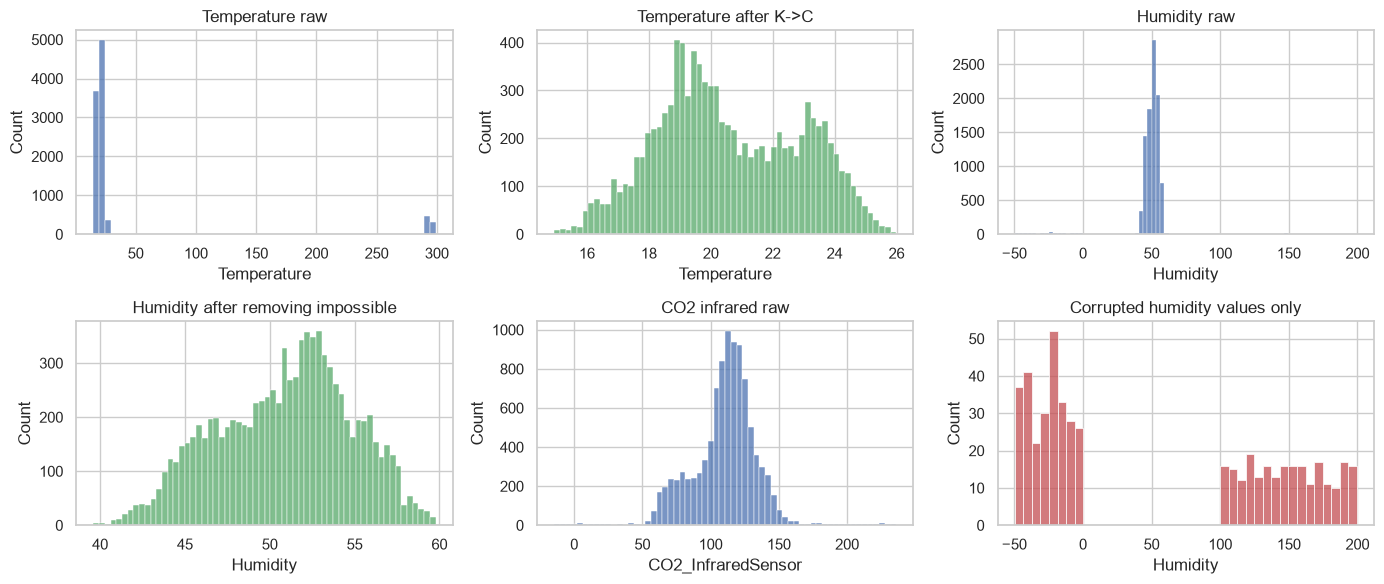

In [7]:
T, H, CI = d["Temperature"], d["Humidity"], d["CO2_InfraredSensor"]
flags = pd.DataFrame({"kelvin_temp": T > 100, "humidity_out_of_range": (H < 0) | (H > 100), "co2_ir_negative": CI < 0})
print(flags.sum().to_dict(), "| any:", int(flags.any(axis=1).sum()))
print("Kelvin rows after K->C:", (T[T > 100] - 273.15).describe()[["min", "50%", "max"]].round(1).to_dict(), "| other rows:", T[T <= 100].describe()[["min", "50%", "max"]].round(1).to_dict())
print("humidity corrupted values: <0 range", H[H < 0].min(), H[H < 0].max(), "| >100 range", H[H > 100].min(), H[H > 100].max(), "| clean rows range", H[(H >= 0) & (H <= 100)].min(), H[(H >= 0) & (H <= 100)].max())
rows = []
for c in flags:
    ct = pd.crosstab(flags[c], y)[ORDER]; rows.append({"flag": c, "n": int(flags[c].sum()), "cramers_V_vs_target": round(cramers_v(ct), 4), "p": round(stats.chi2_contingency(ct)[1], 3), "cramers_V_vs_session": round(cramers_v(pd.crosstab(flags[c], sess)), 3),
                 "P(Low|flag)": round((y[flags[c]] == "Low").mean(), 3), "P(Low|not)": round((y[~flags[c]] == "Low").mean(), 3)})
display(pd.DataFrame(rows).set_index("flag"))
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
sns.histplot(T, bins=60, ax=ax[0, 0]); ax[0, 0].set_title("Temperature raw")
sns.histplot(C["Temperature"], bins=60, ax=ax[0, 1], color="g"); ax[0, 1].set_title("Temperature after K->C")
sns.histplot(H, bins=80, ax=ax[0, 2]); ax[0, 2].set_title("Humidity raw")
sns.histplot(C["Humidity"].dropna(), bins=60, ax=ax[1, 0], color="g"); ax[1, 0].set_title("Humidity after removing impossible")
sns.histplot(CI, bins=60, ax=ax[1, 1]); ax[1, 1].set_title("CO2 infrared raw"); sns.histplot(H[(H < 0) | (H > 100)], bins=40, ax=ax[1, 2], color="r"); ax[1, 2].set_title("Corrupted humidity values only")
plt.tight_layout(); plt.show()

**Observation / implication.** Three defects: **804 Temperature readings in Kelvin** (288-299; after subtracting 273.15 they span 15.3-25.8 °C, matching the other rows' 14.9-26.0, which confirms the unit diagnosis); **503 Humidity values outside 0-100%** (269 between -49.7 and -1.2, 234 between 101 and 199.6, while all valid rows lie in 39.6-59.8, so the corrupted values are not near-valid and cannot be repaired); and 22 negative CO2-infrared readings. The flags are unrelated to the target (Cramer's V <= 0.014, p >= 0.40) and to sessions (V <= 0.061), so they are random contamination, not a signal. Rule: Kelvin -> Celsius; the other two -> NaN. After repair Temperature and Humidity are bounded and nearly symmetric.

## 2f. Sentinel / placeholder values and caps
**Purpose.** Look for suspicious repeated values, hard caps (many rows at min/max), zeros and negatives that act as placeholders.

In [8]:
rows = []
for c in NUM:
    x = C[c].dropna(); vc = x.value_counts()
    rows.append({"feature": c, "n_unique": x.nunique(), "top_value": vc.index[0], "top_value_share_%": round(100 * vc.iloc[0] / len(x), 2), "n_at_min": int((x == x.min()).sum()), "n_at_max": int((x == x.max()).sum()),
                 "n_zero": int((x == 0).sum()), "n_negative": int((x < 0).sum()), "n_in_(-1,999,9999)": int(x.isin([-1, 999, 9999, -999]).sum())})
display(pd.DataFrame(rows).set_index("feature"))
rawnum = d[NUM]; print("raw (uncleaned) values equal to the column max count:", {c: int((rawnum[c] == rawnum[c].max()).sum()) for c in NUM})
print("ordinal code share at extremes: CO_GasSensor 'extremely low' / 'extremely high' =", round((C["CO_GasSensor"] == 0).mean(), 3), "/", round((C["CO_GasSensor"] == 4).mean(), 4))

,n_unique,top_value,top_value_share_%,n_at_min,n_at_max,n_zero,n_negative,"n_in_(-1,999,9999)"
feature,,,,,,,,
Temperature,1487,19.46,0.33,1,2,0,0,0
Humidity,1683,51.01,0.21,1,1,0,0,0
CO2_InfraredSensor,5252,117.54,0.09,1,1,0,0,0
CO2_ElectroChemicalSensor,5139,561.39,0.10,2,1,0,0,0
MetalOxideSensor_Unit1,6745,444.44,0.09,1,1,0,0,0
MetalOxideSensor_Unit2,6285,722.77,0.12,1,1,0,0,0
MetalOxideSensor_Unit3,5488,679.98,0.08,1,1,0,0,0
MetalOxideSensor_Unit4,6511,601.77,0.10,2,1,0,0,0


raw (uncleaned) values equal to the column max count: {'Temperature': 1, 'Humidity': 1, 'CO2_InfraredSensor': 1, 'CO2_ElectroChemicalSensor': 1, 'MetalOxideSensor_Unit1': 1, 'MetalOxideSensor_Unit2': 1, 'MetalOxideSensor_Unit3': 1, 'MetalOxideSensor_Unit4': 1}
ordinal code share at extremes: CO_GasSensor 'extremely low' / 'extremely high' = 0.111 / 0.0072


**Observation / implication.** No sentinel or placeholder values: no zeros or negatives after cleaning, none of (-1, 999, 9999, -999), the most frequent value of any sensor is under 0.4% of rows, and each column's min and max occur once or twice, so there is no clipping or hard cap. The only repeated-value structure is the 2-decimal rounding. CO_GasSensor's extreme levels are rare but legitimate (11.1% 'extremely low', 0.7% 'extremely high').

## 2g. Consistency between related columns
**Purpose.** Related sensors should agree: the two CO2 sensors, the four metal-oxide units, temperature vs humidity.

Spearman between CO2 sensors: -0.481 | MOS pairs: {'Unit1-Unit2': np.float64(0.6), 'Unit1-Unit3': np.float64(0.55), 'Unit1-Unit4': np.float64(0.68), 'Unit2-Unit3': np.float64(0.71), 'Unit2-Unit4': np.float64(0.82), 'Unit3-Unit4': np.float64(0.8)}


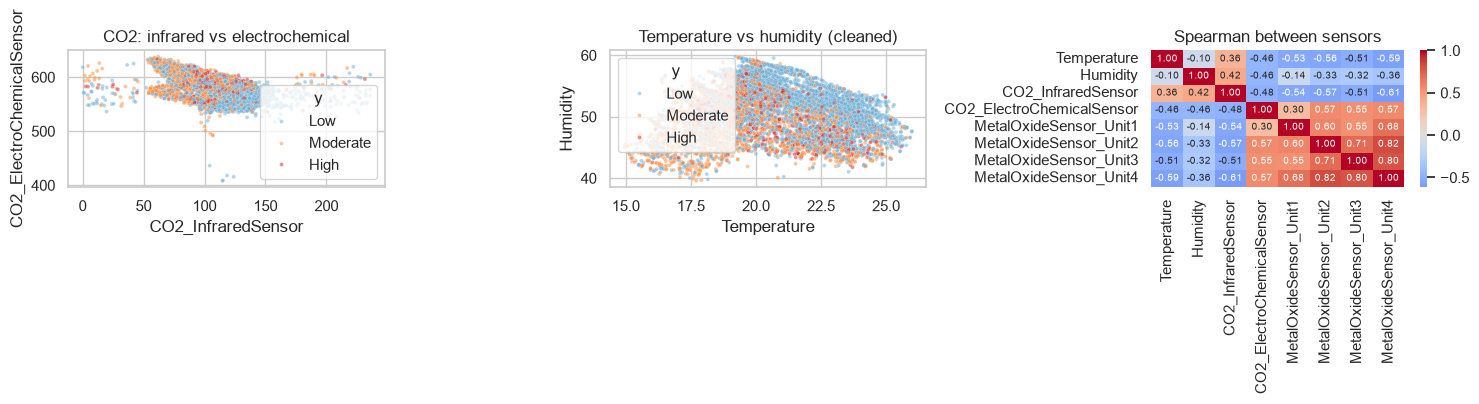

Time of Day levels per session: min 2 max 4 (sessions span several periods)
Session ID vs row order: monotonic? False | number of session changes between consecutive rows: 6185
Time-of-day vs sensors (eta^2): Temperat=0.530, Humidity=0.184, CO2_Infr=0.145, CO2_Elec=0.048, Unit1=0.213, Unit2=0.083, Unit3=0.054, Unit4=0.209


In [9]:
cn = C[NUM].corr(method="spearman"); print("Spearman between CO2 sensors:", round(cn.loc["CO2_InfraredSensor", "CO2_ElectroChemicalSensor"], 3), "| MOS pairs:", {f"{a[-5:]}-{b[-5:]}": round(cn.loc[a, b], 2) for a, b in itertools.combinations(MOS, 2)})
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=C.assign(y=y), x="CO2_InfraredSensor", y="CO2_ElectroChemicalSensor", hue="y", hue_order=ORDER, palette=PAL, s=8, alpha=.5, ax=ax[0]); ax[0].set_title("CO2: infrared vs electrochemical")
sns.scatterplot(data=C.assign(y=y), x="Temperature", y="Humidity", hue="y", hue_order=ORDER, palette=PAL, s=8, alpha=.5, ax=ax[1]); ax[1].set_title("Temperature vs humidity (cleaned)")
sns.heatmap(cn, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, ax=ax[2]); ax[2].set_title("Spearman between sensors")
plt.tight_layout(); plt.show()
st = pd.crosstab(sess, d["Time of Day"]); print("Time of Day levels per session: min", int((st > 0).sum(axis=1).min()), "max", int((st > 0).sum(axis=1).max()), "(sessions span several periods)")
print("Session ID vs row order: monotonic?", bool(sess.is_monotonic_increasing), "| number of session changes between consecutive rows:", int((sess != sess.shift()).sum() - 1))
print("Time-of-day vs sensors (eta^2): " + ", ".join(f"{c.split('_')[-1] if 'Unit' in c else c[:8]}={eta_sq(C[c], d['Time of Day']):.3f}" for c in NUM))

**Observation / implication.** Related sensors are *not* simply redundant. The four metal-oxide units correlate positively (Spearman 0.55-0.82; Unit2-Unit4 0.82, Unit3-Unit4 0.80) as expected for a common underlying gas load, but **the two CO2 sensors correlate negatively (Spearman -0.48)**, which is physically surprising and is investigated in 2h. Temperature depends strongly on time of day (eta-squared 0.53), with smaller time effects on humidity (0.18), MOS Unit1 (0.21) and MOS Unit4 (0.21), so Time of Day is entangled with the sensors (examined in 6b). Each session spans 2-4 time-of-day periods and sessions are interleaved row-by-row in the table (6,185 session changes between consecutive rows).

## 2h. Investigation: why are the two CO2 sensors negatively related?
**Purpose.** Two sensors measuring the same gas should be positively related. Check the sign pooled, within sessions, within time-of-day and within classes, and per session, to see whether the negative pooled correlation is a between-session artefact.

{'pooled': np.float64(-0.481), 'within session (demeaned)': np.float64(-0.797), 'within time-of-day': np.float64(-0.492), 'within class': np.float64(-0.407), 'session means (38)': np.float64(-0.494)}
per-session Spearman: min -0.91 median -0.74 max -0.27 | share negative 1.00
class means (IR, EC):


,ir,ec
y,,
Low,116.1,571.9
Moderate,101.0,588.7
High,110.0,583.4


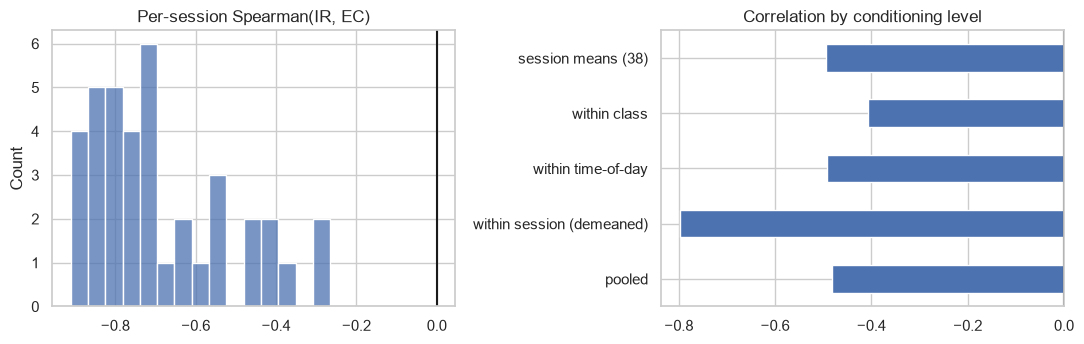

In [10]:
ir, ec = C["CO2_InfraredSensor"], C["CO2_ElectroChemicalSensor"]; ok = ir.notna() & ec.notna()
gg = pd.DataFrame({"ir": ir, "ec": ec, "sess": sess, "t": d["Time of Day"], "y": y})[ok]
dm = lambda col, by: gg[col] - gg.groupby(by)[col].transform("mean")
res = {"pooled": stats.spearmanr(gg.ir, gg.ec)[0], "within session (demeaned)": stats.spearmanr(dm("ir", "sess"), dm("ec", "sess"))[0],
       "within time-of-day": stats.spearmanr(dm("ir", "t"), dm("ec", "t"))[0], "within class": stats.spearmanr(dm("ir", "y"), dm("ec", "y"))[0],
       "session means (38)": stats.spearmanr(gg.groupby("sess")["ir"].mean(), gg.groupby("sess")["ec"].mean())[0]}
print({k: round(v, 3) for k, v in res.items()})
per = gg.groupby("sess").apply(lambda s: stats.spearmanr(s.ir, s.ec)[0]); print("per-session Spearman: min %.2f median %.2f max %.2f | share negative %.2f" % (per.min(), per.median(), per.max(), (per < 0).mean()))
print("class means (IR, EC):"); display(gg.groupby("y")[["ir", "ec"]].mean().loc[ORDER].round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); sns.histplot(per, bins=15, ax=ax[0]); ax[0].set_title("Per-session Spearman(IR, EC)"); ax[0].axvline(0, color="k")
pd.Series(res).plot.barh(ax=ax[1]); ax[1].axvline(0, color="k"); ax[1].set_title("Correlation by conditioning level"); plt.tight_layout(); plt.show()

**Observation / implication.** The negative CO2 relation is real and extremely consistent: it is -0.48 pooled and **-0.80 within sessions after removing session means**, and the per-session Spearman is negative in **all 38 sessions** (range -0.91 to -0.27, median -0.74). So it is not a between-session artefact or a Simpson's paradox; within a session, when the infrared reading goes up the electrochemical reading goes down. This suggests the two sensors respond to different physical drivers (or one is inverted/mis-scaled) rather than measuring the same gas. Implication: treat them as two different signals; a sum or average is meaningless, whereas a standardised *difference* (EC minus IR) adds the two effects. The class means (IR lower and EC higher for Moderate) are also opposite in direction.

## 2i. Investigation: near-zero CO2 infrared readings
**Purpose.** The infrared CO2 sensor has a very low minimum (0.1) while typical values are ~110. Check whether there is a separate low cluster, and whether those rows behave like the rest.

CO2_InfraredSensor
(-1, 10]        24
(10, 20]        21
(20, 40]        20
(40, 60]       108
(60, 80]      1018
(80, 100]     1339
(100, 150]    7028
(150, 250]     260
rows < 50: 79 | < 20: 45
class mix low-CO2 vs rest:
Activity Level        Low  Moderate   High
CO2_InfraredSensor                        
False               0.579     0.312  0.109
True                0.544     0.342  0.114 | chi2 p = 0.8171 | V = 0.006
other-feature shift in low-CO2 rows (rank-biserial): {'Temperature': -0.03, 'Humidity': 0.0, 'CO2_ElectroChemicalSensor': -0.04, 'MetalOxideSensor_Unit1': 0.03, 'MetalOxideSensor_Unit2': -0.02, 'MetalOxideSensor_Unit3': -0.07, 'MetalOxideSensor_Unit4': 0.0}
sessions containing low rows: 31 of 38 | time-of-day mix: {'evening': 0.28, 'morning': 0.27, 'afternoon': 0.23, 'night': 0.23}


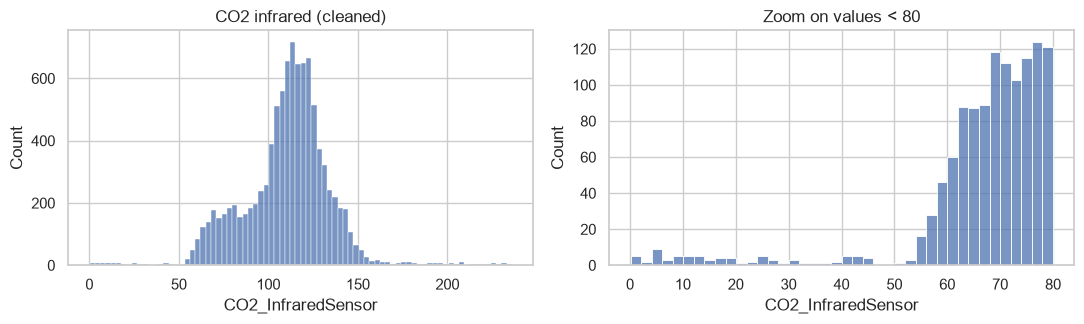

In [11]:
x = C["CO2_InfraredSensor"].dropna(); print(pd.cut(x, [-1, 10, 20, 40, 60, 80, 100, 150, 250]).value_counts().sort_index().to_string())
low = C["CO2_InfraredSensor"] < 50; print("rows < 50:", int(low.sum()), "| < 20:", int((C["CO2_InfraredSensor"] < 20).sum()))
ct = pd.crosstab(low, y)[ORDER]; print("class mix low-CO2 vs rest:"); print(ct.div(ct.sum(1), axis=0).round(3).to_string(), "| chi2 p =", round(stats.chi2_contingency(ct)[1], 4), "| V =", round(cramers_v(ct), 3))
print("other-feature shift in low-CO2 rows (rank-biserial):", {c: round(rank_biserial(C.loc[low, c], C.loc[~low, c]), 2) for c in NUM if c != "CO2_InfraredSensor"})
print("sessions containing low rows:", sess[low].nunique(), "of", sess.nunique(), "| time-of-day mix:", d.loc[low, "Time of Day"].value_counts(normalize=True).round(2).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4)); sns.histplot(x, bins=80, ax=ax[0]); ax[0].set_title("CO2 infrared (cleaned)"); sns.histplot(x[x < 80], bins=40, ax=ax[1]); ax[1].set_title("Zoom on values < 80"); plt.tight_layout(); plt.show()

**Observation / implication.** The infrared CO2 sensor has a sparse low tail: 65 rows below 40 and 79 below 50 (0.8%) versus a bulk at 60-150, with no separate cluster (counts fall smoothly from the 40-60 bin of 108). These rows are not related to the target (P(Low) 0.544 vs 0.579, Cramer's V = 0.006, p = 0.82), do not differ on any other sensor (all rank-biserial <= 0.07), appear in 31 of 38 sessions and at all times of day. They look like occasional sensor dropouts. They are plausible rather than impossible (0.1 is above 0), so they are kept and left to winsorising rather than being set to NaN.

## 2j. Investigation: is there a hidden clock in the row order / within-session structure?
**Purpose.** Rows of one session appear interleaved with other sessions but may still be time-ordered. If consecutive rows of a session are strongly autocorrelated, the data contain temporal structure that a random split would exploit.

In [12]:
g = C.assign(sess=sess, y=y, code=code, t=d["Time of Day"])
rows = []
for c in NUM:
    prev = g.groupby("sess")[c].shift(1); m = prev.notna() & g[c].notna()
    dm = g[c] - g.groupby("sess")[c].transform("mean"); dprev = dm.groupby(g["sess"]).shift(1)
    rows.append({"feature": c, "lag1_corr_within_session_raw": g.loc[m, c].corr(prev[m]), "lag1_corr_session_demeaned": dm[m].corr(dprev[m])})
rng = np.random.RandomState(0); g2 = g.copy(); g2["perm"] = rng.permutation(len(g2)); g2 = g2.sort_values("perm")
shuf = {c: g2[c].corr(g2.groupby("sess")[c].shift(1)) for c in NUM[:3]}
display(pd.DataFrame(rows).set_index("feature").round(3)); print("null (rows shuffled before taking session lag): ", {k: round(float(v), 3) for k, v in shuf.items()})
prev_y = g.groupby("sess")["y"].shift(1); m = prev_y.notna(); same = (g.loc[m, "y"] == prev_y[m]).mean()
mix_s = pd.crosstab(g["sess"], g["y"], normalize="index").pow(2).sum(1); expected = mix_s.loc[g.loc[m, "sess"]].mean()
print(f"P(same class as previous row of the session) = {same:.3f}  vs expected if independent given session mix = {expected:.3f}")
tr = pd.crosstab(g.groupby("sess")["t"].shift(1).rename("previous"), g["t"].rename("current"), normalize="index").round(2); print("Time-of-day transitions within session (row-normalised):"); display(tr)
g["row"] = np.arange(len(g)); print("Spearman(row index, activity code) =", round(stats.spearmanr(g["row"], g["code"])[0], 4), "| Spearman(row index, Temperature) =", round(stats.spearmanr(g["row"], g["Temperature"])[0], 4))

,lag1_corr_within_session_raw,lag1_corr_session_demeaned
feature,,
Temperature,0.659,0.561
Humidity,0.749,0.539
CO2_InfraredSensor,0.505,0.348
CO2_ElectroChemicalSensor,0.909,0.492
MetalOxideSensor_Unit1,0.641,0.529
MetalOxideSensor_Unit2,0.285,0.147
MetalOxideSensor_Unit3,0.236,0.116
MetalOxideSensor_Unit4,0.699,0.533


null (rows shuffled before taking session lag):  {'Temperature': 0.217, 'Humidity': 0.446, 'CO2_InfraredSensor': 0.228}
P(same class as previous row of the session) = 0.541  vs expected if independent given session mix = 0.500
Time-of-day transitions within session (row-normalised):


current,afternoon,evening,morning,night
previous,,,,
afternoon,0.69,0.11,0.10,0.10
evening,0.11,0.67,0.10,0.12
morning,0.12,0.10,0.68,0.10
night,0.10,0.12,0.12,0.67


Spearman(row index, activity code) = -0.1447 | Spearman(row index, Temperature) = 0.1515


**Observation / implication.** **There is temporal structure in the row order.** Within a session, consecutive rows are strongly autocorrelated: lag-1 correlation 0.66 (Temperature), 0.75 (Humidity), 0.91 (CO2 electrochemical) and still 0.35-0.56 after removing the session mean, versus 0.22/0.45/0.23 when rows are shuffled first. The time-of-day label persists (about 68% of next rows keep the same period, ~10% each for the others) and the class agrees with the previous row of the same session 54.1% of the time versus 50.0% expected from the session's class mix, i.e. weak persistence of activity. The row index itself correlates with activity (Spearman -0.145) and with Temperature (+0.152). Implication: neighbouring rows are near-copies, so **a random row-level split would let near-duplicate neighbours sit in train and test**.

## 2k. Leakage audit
**Purpose.** Test (1) whether any single feature almost determines the target (arithmetic tie), (2) whether Session ID or the row index act as hidden keys/clocks, using grouped vs random CV and a shuffled-label null.

In [13]:
Xs = C[NUM + ORD]; gk = GroupKFold(5); sk = StratifiedKFold(5, shuffle=True, random_state=0)
def cvs(X, grp=None, shuf=False, seed=0, scoring="f1_macro"):
    yy = y.sample(frac=1, random_state=seed).values if shuf else y.values
    return cross_val_score(HGB(random_state=0), X, yy, cv=gk if grp is not None else sk, groups=grp, scoring=scoring, n_jobs=5).mean()
# (1) single-feature separability (grouped CV one-vs-rest AUC, depth-limited boosting)
rows = []
for c in NUM + ORD + ["row_index"]:
    X1 = pd.DataFrame({"row_index": np.arange(len(C))}) if c == "row_index" else C[[c]]
    rows.append({"feature": c, "grouped_CV_macro_AUC": cvs(X1, sess, scoring="roc_auc_ovr")})
sf = pd.DataFrame(rows).set_index("feature").sort_values("grouped_CV_macro_AUC", ascending=False); display(sf.round(3))
# (2) ID/clock leakage
res = pd.DataFrame({"random 5-fold": {
    "sensors": cvs(Xs), "Session ID only": cvs(pd.DataFrame({"s": sess})), "row index only": cvs(pd.DataFrame({"r": np.arange(len(C))})),
    "sensors + Session ID": cvs(Xs.assign(s=sess)), "NULL: sensors, shuffled labels": np.mean([cvs(Xs, shuf=True, seed=s) for s in range(3)])},
    "grouped 5-fold (by session)": {
    "sensors": cvs(Xs, sess), "Session ID only": cvs(pd.DataFrame({"s": sess}), sess), "row index only": cvs(pd.DataFrame({"r": np.arange(len(C))}), sess),
    "sensors + Session ID": cvs(Xs.assign(s=sess), sess), "NULL: sensors, shuffled labels": np.mean([cvs(Xs, sess, shuf=True, seed=s) for s in range(3)])}})
display(res.round(3))
ct = pd.crosstab(sess, y); print("Session ID vs target Cramer's V =", round(cramers_v(ct), 3), "| dominant-class share per session: min/median/max =", ct.div(ct.sum(1), axis=0).max(axis=1).agg(["min", "median", "max"]).round(2).tolist())
print("Post-event information: none of the columns encodes an outcome (sensor readings, HVAC mode, light, time-of-day), so no post-event leakage is plausible.")

,grouped_CV_macro_AUC
feature,
MetalOxideSensor_Unit2,0.724
MetalOxideSensor_Unit4,0.711
MetalOxideSensor_Unit3,0.668
CO_GasSensor,0.649
CO2_ElectroChemicalSensor,0.641
MetalOxideSensor_Unit1,0.631
CO2_InfraredSensor,0.624
Temperature,0.611
Humidity,0.543


,random 5-fold,grouped 5-fold (by session)
sensors,0.511,0.446
Session ID only,0.393,0.275
row index only,0.344,0.301
sensors + Session ID,0.515,0.440
"NULL: sensors, shuffled labels",0.293,0.292


Session ID vs target Cramer's V = 0.266 | dominant-class share per session: min/median/max = [0.45, 0.53, 0.89]
Post-event information: none of the columns encodes an outcome (sensor readings, HVAC mode, light, time-of-day), so no post-event leakage is plausible.


**Observation / implication.** **Verdict: no feature leaks the target, but Session ID and the row order leak under random CV, so splitting must be by session.** (1) No single feature separates the classes: the best grouped-CV one-vs-rest AUC is 0.724 (MOS Unit2); Ambient Light = 0.49 and the row index = 0.503 are at chance. Nothing is arithmetically tied to the target and no column encodes an outcome. (2) Session ID alone scores macro-F1 0.393 under random CV (above the shuffled-label null of 0.293) but 0.275 under grouped CV (null 0.292): it only memorises session class mixes (Cramer's V 0.27; dominant-class share 45-89%). The row index alone scores 0.344 under random CV vs 0.301 grouped, a weaker version of the same effect (hidden clock). Sensors alone fall from 0.511 (random) to 0.446 (grouped), and adding Session ID gives no grouped gain (0.440). The shuffled-label null at ~0.29 confirms the evaluation machinery itself does not leak. Decisions: drop Session ID and row order as features; split and cross-validate by session.

## 3. Descriptive statistics
**Purpose.** Mean, spread, skewness, excess kurtosis, % zeros and % outside 1.5xIQR for each numeric/ordinal feature after stateless cleaning (and for the raw columns that needed repair).

In [14]:
def describe(df):
    r = df.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
    r["skew"] = df.skew(); r["kurtosis"] = df.kurt(); r["pct_zero"] = (df == 0).mean() * 100
    q1, q3 = df.quantile(.25), df.quantile(.75); iqr = q3 - q1
    r["pct_outside_1.5IQR"] = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum() / df.count() * 100; return r
DS = describe(C[NUM + ORD]); display(DS.round(2))
print("raw (before repair) skew/kurtosis for repaired columns:"); display(describe(d[["Temperature", "Humidity", "CO2_InfraredSensor"]])[["min", "max", "skew", "kurtosis", "pct_outside_1.5IQR"]].round(2))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,pct_zero,pct_outside_1.5IQR
Temperature,9840.0,20.57,2.29,14.94,18.89,20.20,22.53,25.99,0.13,-0.86,0.00,0.00
Humidity,9337.0,50.88,3.96,39.61,47.91,51.31,53.72,59.77,-0.22,-0.64,0.00,0.00
CO2_InfraredSensor,9818.0,110.56,24.53,0.10,99.19,113.08,124.02,236.01,-0.05,3.12,0.00,3.89
CO2_ElectroChemicalSensor,9135.0,578.38,22.69,408.60,559.26,578.95,595.35,637.90,-0.04,0.54,0.00,0.10
MetalOxideSensor_Unit1,9840.0,470.51,51.43,286.83,439.72,468.89,494.03,632.89,0.42,0.67,0.00,6.26
MetalOxideSensor_Unit2,9840.0,728.38,43.51,554.28,708.00,726.80,746.60,902.21,0.10,3.87,0.00,6.82
MetalOxideSensor_Unit3,7290.0,681.54,60.33,457.81,658.42,680.22,704.55,905.15,-0.03,3.50,0.00,9.84
MetalOxideSensor_Unit4,9840.0,612.12,42.88,412.79,585.69,609.19,635.60,736.11,0.22,0.41,0.00,3.02
CO_GasSensor,8475.0,1.30,0.78,0.00,1.00,1.00,2.00,4.00,0.42,0.42,11.12,0.84
Ambient Light Level,7324.0,2.85,1.20,0.00,2.00,3.00,4.00,4.00,-0.85,-0.24,4.28,0.00


raw (before repair) skew/kurtosis for repaired columns:


,min,max,skew,kurtosis,pct_outside_1.5IQR
Temperature,14.94,298.93,3.05,7.32,8.17
Humidity,-49.66,199.59,1.63,21.50,5.11
CO2_InfraredSensor,-14.67,236.01,-0.25,3.67,3.91


**Observation / implication.** After repair the sensors are well behaved: skewness is within +/-0.45 for every continuous sensor (the ordinal Ambient Light code is -0.85) and Temperature/Humidity are flat-topped (kurtosis -0.86/-0.64, reflecting the bimodality seen in 4a). Tails matter for CO2 infrared (kurtosis 3.1, 3.9% outside 1.5xIQR, the sparse low tail) and MOS Units 2 and 3 (kurtosis 3.9/3.5, 6.8% and 9.8% outside 1.5xIQR). There are no zeros (apart from the 'extremely low' ordinal code, 11.1%). The raw columns show how much the defects distort moments: raw Temperature has skewness 3.05 and kurtosis 7.3, raw Humidity kurtosis 21.5; both vanish after repair. Moderate winsorising is therefore enough; no log transform is needed.

## 4a. Univariate: numeric features
**Purpose.** Distribution shape of every cleaned numeric feature (histogram + kernel density; dashed line = median).

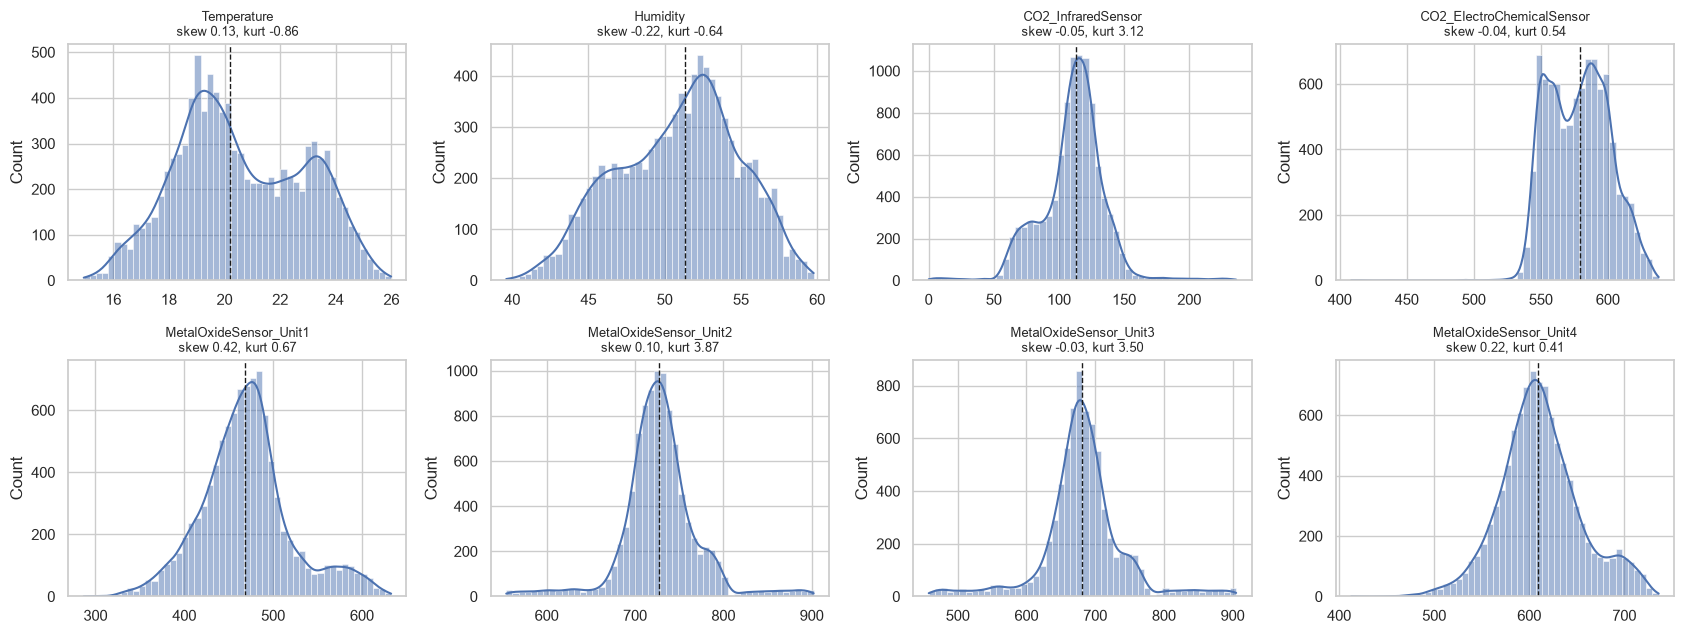

In [15]:
fig, ax = plt.subplots(2, 4, figsize=(17, 6.5))
for a, c in zip(ax.ravel(), NUM):
    sns.histplot(C[c].dropna(), bins=50, kde=True, ax=a, color="#4c72b0"); a.axvline(C[c].median(), color="k", ls="--", lw=1); a.set_title(f"{c}\nskew {C[c].skew():.2f}, kurt {C[c].kurt():.2f}", fontsize=9); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Observation / implication.** Several features are **multi-modal or shouldered**, not simple bell curves: Temperature is bimodal (peaks near 19.3 and 23.3 °C; consistent with the strong Time-of-Day effect, eta-squared 0.53), CO2 electrochemical has two humps (~555 and ~590), CO2 infrared has a clear secondary shoulder at 60-90 beside its main peak near 115, MOS Unit1 and Unit4 have right-hand shoulders (~580 and ~690), and Humidity has a left shoulder near 45-47. MOS Unit2/Unit3 are sharply peaked with sparse two-sided tails. The mixtures fit the session/time structure found later (much of the variance is between sessions), so they are a property of the data, not of cleaning. No heavy skew, so no transform is needed; but means and standard deviations hide the sub-populations.

## 4b. Univariate: categorical and ordinal features and the target
**Purpose.** Category frequencies, including the missing category, for Time of Day, HVAC mode, Ambient Light, CO gas level and the target.

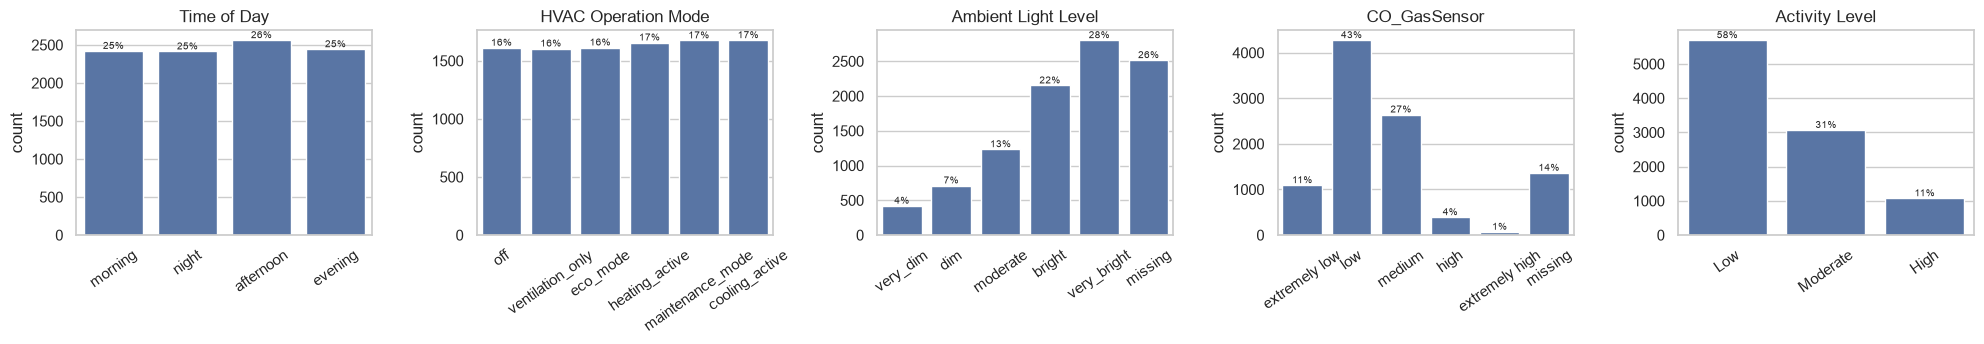

In [16]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
for a, (n, s, o) in zip(ax, [("Time of Day", C["Time of Day"], None), ("HVAC Operation Mode", C["HVAC Operation Mode"], None),
        ("Ambient Light Level", d["Ambient Light Level"].fillna("missing"), ["very_dim", "dim", "moderate", "bright", "very_bright", "missing"]),
        ("CO_GasSensor", d["CO_GasSensor"].fillna("missing"), ["extremely low", "low", "medium", "high", "extremely high", "missing"]), (TARGET, y, ORDER)]):
    sns.countplot(x=s, order=o, ax=a, color="#4c72b0"); a.set_title(n); a.set_xlabel(""); a.tick_params(axis="x", rotation=35)
    for p in a.patches: a.annotate(f"{p.get_height()/len(s):.0%}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.show()

**Observation / implication.** Time of Day (25% each) and HVAC mode (16-17% each) are balanced. Ambient Light is skewed toward the bright levels with 25.3% missing; CO_GasSensor is concentrated at 'low' (43%) and 'medium' (27%) with rare 'high' (4%) and 'extremely high' (1%) levels and 13.7% missing. The target is imbalanced (58/31/11%). Rare CO levels give small cells for any analysis that crosses them with other columns.

## 5a. Bivariate: every numeric/ordinal feature vs the target
**Purpose.** Pearson and Spearman correlation with the ordered target code (Low=0, Moderate=1, High=2), Pearson on a log-transformed feature, and the class-agnostic ANOVA F, Kruskal-Wallis H and eta-squared (share of variance explained by class).

,pearson,spearman,pearson_log_x,anova_F,anova_p,kruskal_H,kruskal_p,eta2,|spearman|-|pearson|
feature,,,,,,,,,
MetalOxideSensor_Unit4,0.3071,0.4019,0.3073,919.4906,0.0000,1890.0788,0.0000,0.1575,0.0948
CO2_ElectroChemicalSensor,0.2777,0.3247,0.2435,607.2867,0.0000,1139.5460,0.0000,0.1174,0.0470
CO_GasSensor,-0.2504,-0.2917,-0.2226,473.2608,0.0000,898.1348,0.0000,0.1005,0.0413
Temperature,-0.2477,-0.2854,-0.2313,529.5458,0.0000,996.8512,0.0000,0.0972,0.0377
MetalOxideSensor_Unit1,0.2061,0.2628,0.2183,480.4826,0.0000,913.9289,0.0000,0.0890,0.0567
CO2_InfraredSensor,-0.1882,-0.2562,-0.1434,396.2336,0.0000,866.9023,0.0000,0.0747,0.0680
MetalOxideSensor_Unit2,0.1932,0.3656,0.1223,328.1183,0.0000,1559.6596,0.0000,0.0625,0.1725
MetalOxideSensor_Unit3,0.1934,0.3585,0.1373,233.0778,0.0000,1111.9213,0.0000,0.0601,0.1650
Humidity,-0.1129,-0.1307,-0.1091,174.9942,0.0000,295.6631,0.0000,0.0361,0.0177


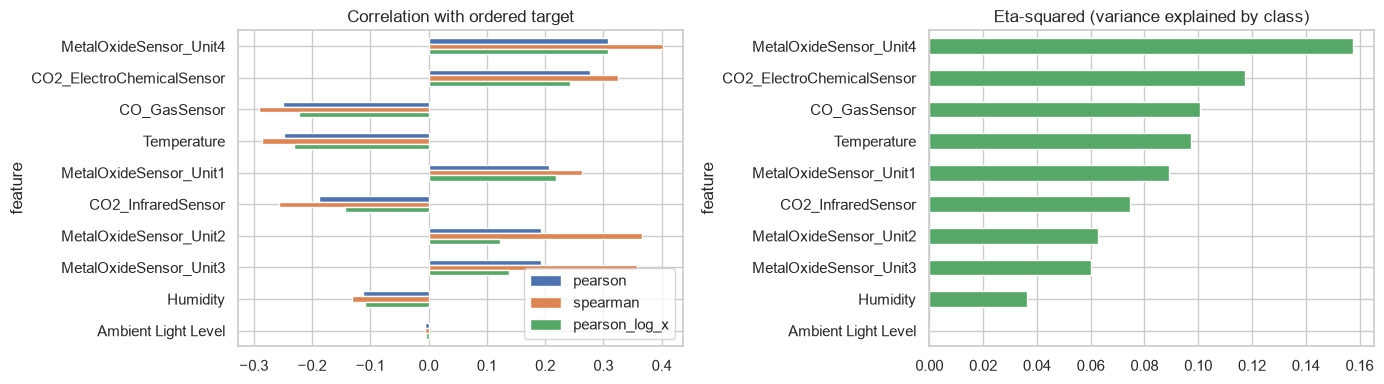

In [17]:
rows = []
for c in NUM + ORD:
    m = C[c].notna(); x = C.loc[m, c]; yy = y[m]; cc = code[m]; xl = np.log1p(x - x.min())
    grp = [x[yy == k] for k in ORDER]; F, pF = stats.f_oneway(*grp); Hh, pH = stats.kruskal(*grp)
    rows.append({"feature": c, "pearson": stats.pearsonr(x, cc)[0], "spearman": stats.spearmanr(x, cc)[0], "pearson_log_x": stats.pearsonr(xl, cc)[0],
                 "anova_F": F, "anova_p": pF, "kruskal_H": Hh, "kruskal_p": pH, "eta2": eta_sq(x, yy)})
B = pd.DataFrame(rows).set_index("feature"); B["|spearman|-|pearson|"] = B["spearman"].abs() - B["pearson"].abs(); B = B.sort_values("eta2", ascending=False)
display(B.round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
B[["pearson", "spearman", "pearson_log_x"]].plot.barh(ax=ax[0]); ax[0].set_title("Correlation with ordered target"); ax[0].invert_yaxis()
B["eta2"].plot.barh(ax=ax[1], color="#55a868"); ax[1].set_title("Eta-squared (variance explained by class)"); ax[1].invert_yaxis(); plt.tight_layout(); plt.show()

**Observation / implication.** **MOS Unit4 is the strongest single feature (eta-squared 0.158, Spearman 0.40)**, followed by CO2 electrochemical (0.117), CO_GasSensor (0.100, negative), Temperature (0.097, negative), MOS Unit1 (0.089) and CO2 infrared (0.075, negative). Humidity is weak (0.036) and **Ambient Light has zero effect** (eta-squared 0.000, p = 0.89). Every effect is small: the best feature explains 16% of between-class variance. Spearman exceeds Pearson in absolute value for all sensors, most for MOS Unit2/Unit3 (+0.17) and Unit4 (+0.09), which signals monotonic-or-non-monotonic structure the linear measure misses. Pearson on the log-transformed feature is almost identical to raw Pearson (e.g. MOS4 0.307 vs 0.307), so the Pearson-Spearman gap is not caused by skewed marginals. (The ordered-code correlations understate the effect because the classes are not ordered along the sensors: see 5c.)

## 5b. Non-monotonic structure for weak features
**Purpose.** A feature can be unrelated by correlation yet matter through a U-shape or band. For every feature compare the linear R2 with a quadratic R2 and a decile-step R2 (explaining the ordered target); judge by effect size (delta R2), not p-values (n is large).

,R2_linear,R2_quadratic,dR2_quad,R2_decile_steps,dR2_steps,weak_on_both
feature,,,,,,
Temperature,0.0614,0.0619,0.0005,0.0687,0.0074,False
Humidity,0.0128,0.0128,0.0000,0.0171,0.0044,True
CO2_InfraredSensor,0.0354,0.0366,0.0012,0.0602,0.0247,False
CO2_ElectroChemicalSensor,0.0771,0.0784,0.0012,0.1070,0.0299,False
MetalOxideSensor_Unit1,0.0425,0.0548,0.0123,0.0613,0.0188,False
MetalOxideSensor_Unit2,0.0373,0.0380,0.0007,0.1745,0.1372,False
MetalOxideSensor_Unit3,0.0374,0.0391,0.0017,0.1641,0.1267,False
MetalOxideSensor_Unit4,0.0943,0.1155,0.0211,0.1703,0.0760,False
CO_GasSensor,0.0627,0.0651,0.0024,0.0923,0.0296,False


weak on BOTH correlation and eta2: ['Humidity', 'Ambient Light Level']


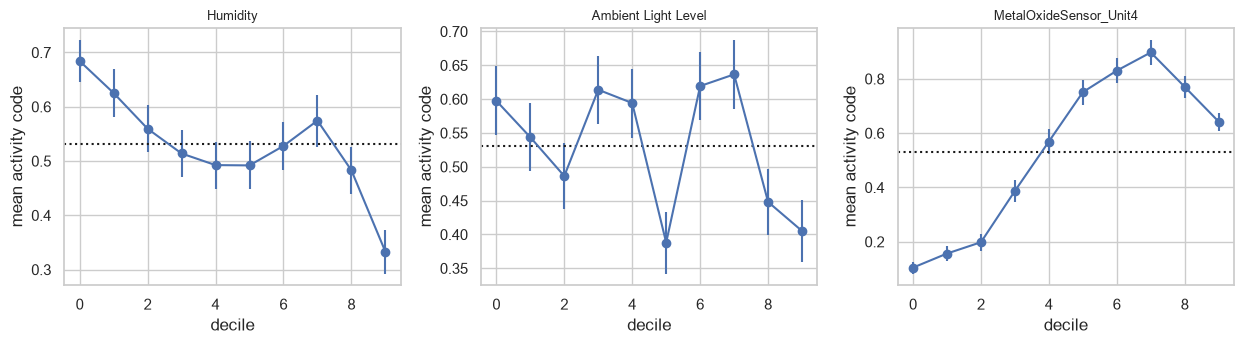

In [18]:
def r2(X, yv): b = np.linalg.lstsq(X, yv, rcond=None)[0]; return 1 - (yv - X @ b).var() / yv.var()
rows = []; prof = {}
for c in NUM + ORD:
    m = C[c].notna(); x = C.loc[m, c].values; cc = code[m].values; xs = (x - x.mean()) / x.std()
    X1 = np.c_[np.ones(len(xs)), xs]; X2 = np.c_[X1, xs ** 2]; bins = pd.qcut(pd.Series(x).rank(method="first"), 10, labels=False)
    Xb = pd.get_dummies(bins).values.astype(float); rl, rq, rbn = r2(X1, cc), r2(X2, cc), r2(Xb, cc)
    prof[c] = pd.DataFrame({"x": pd.Series(x).groupby(bins).mean(), "mean_code": pd.Series(cc).groupby(bins).mean(), "sem": pd.Series(cc).groupby(bins).sem()})
    rows.append({"feature": c, "R2_linear": rl, "R2_quadratic": rq, "dR2_quad": rq - rl, "R2_decile_steps": rbn, "dR2_steps": rbn - rl})
NM = pd.DataFrame(rows).set_index("feature"); weak = B[(B["spearman"].abs() < 0.15) & (B["eta2"] < 0.05)].index.tolist()
NM["weak_on_both"] = NM.index.isin(weak); display(NM.round(4)); print("weak on BOTH correlation and eta2:", weak)
show = weak + ["MetalOxideSensor_Unit4"]; fig, ax = plt.subplots(1, len(show), figsize=(4.2 * len(show), 3.6), squeeze=False)
for a, c in zip(ax[0], show):
    p = prof[c]; a.errorbar(range(len(p)), p["mean_code"], yerr=1.96 * p["sem"], marker="o"); a.axhline(code.mean(), color="k", ls=":"); a.set_title(c, fontsize=9); a.set_xlabel("decile"); a.set_ylabel("mean activity code")
plt.tight_layout(); plt.show()

**Observation / implication.** Only Humidity and Ambient Light are weak on both correlation and eta-squared. Neither hides a structure: Humidity has a small, roughly monotonic decline (quadratic dR2 = 0.0000, decile-step dR2 = 0.004), and Ambient Light's zigzag decile profile is an artefact of splitting a 5-level ordinal into 10 bins with ties (all decile confidence bars overlap; step dR2 = 0.017 is within noise). In contrast, **non-monotonic structure is large for the strong sensors**: decile-step R2 exceeds linear R2 by 0.137 for MOS Unit2, 0.127 for Unit3 and 0.076 for Unit4 (linear R2 only 0.037-0.094), while the quadratic term adds little (<= 0.02) because the shape is not a smooth parabola. The MOS4 decile profile rises from an activity code of 0.10 to 0.90 at decile 7 and then falls back to 0.64: an inverted-U, i.e. Moderate rows sit in the middle-to-high range and Low rows at the extremes.

## 5c. Which classes does each feature separate? (one-vs-rest AUC, Cohen's d, Tukey HSD)
**Purpose.** A feature may separate Low from the rest but not Moderate from High. One-vs-rest ROC AUC per class, Cohen's d for High vs Low and Moderate vs Low, and Tukey HSD on the strongest feature.

,AUC Low vs rest,AUC Moderate vs rest,AUC High vs rest,d High-Low,d Mod-Low,d High-Mod
feature,,,,,,
Temperature,0.682,0.321,0.441,-0.456,-0.705,0.265
Humidity,0.591,0.390,0.514,-0.100,-0.426,0.324
CO2_InfraredSensor,0.666,0.327,0.464,-0.260,-0.619,0.384
CO2_ElectroChemicalSensor,0.296,0.694,0.583,0.536,0.776,-0.262
MetalOxideSensor_Unit1,0.329,0.677,0.537,0.293,0.673,-0.418
MetalOxideSensor_Unit2,0.271,0.719,0.593,0.328,0.564,-0.241
MetalOxideSensor_Unit3,0.275,0.715,0.591,0.342,0.543,-0.219
MetalOxideSensor_Unit4,0.248,0.741,0.601,0.556,0.914,-0.427
CO_GasSensor,0.670,0.332,0.445,-0.444,-0.709,0.305


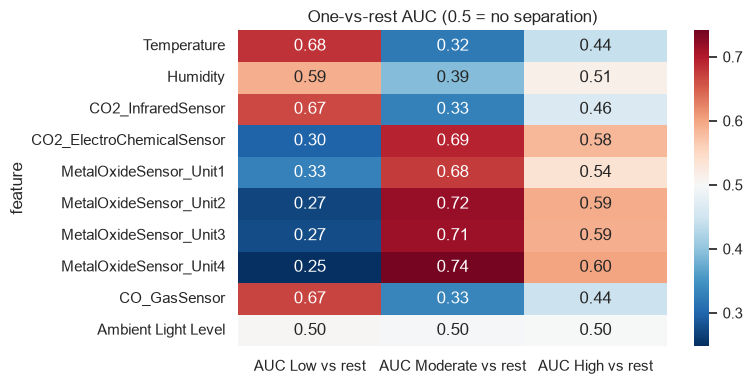

Tukey HSD on MetalOxideSensor_Unit4:
         pair  mean_diff   p
 Low-Moderate   -37.2778 0.0
     Low-High   -22.0920 0.0
Moderate-High    15.1858 0.0


In [19]:
rows = []
for c in NUM + ORD:
    m = C[c].notna(); x = C.loc[m, c]; yy = y[m]
    rows.append({"feature": c, **{f"AUC {k} vs rest": roc_auc_score(yy == k, x) for k in ORDER},
                 "d High-Low": cohens_d(x[yy == "High"], x[yy == "Low"]), "d Mod-Low": cohens_d(x[yy == "Moderate"], x[yy == "Low"]), "d High-Mod": cohens_d(x[yy == "High"], x[yy == "Moderate"])})
PC = pd.DataFrame(rows).set_index("feature"); display(PC.round(3))
fig, ax = plt.subplots(figsize=(8, 4)); sns.heatmap(PC[[f"AUC {k} vs rest" for k in ORDER]], annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, ax=ax); ax.set_title("One-vs-rest AUC (0.5 = no separation)"); plt.tight_layout(); plt.show()
top = B.index[0]; grp = [C.loc[y == k, top].dropna() for k in ORDER]; tk = stats.tukey_hsd(*grp)
print(f"Tukey HSD on {top}:"); print(pd.DataFrame({"pair": [f"{ORDER[i]}-{ORDER[j]}" for i, j in [(0, 1), (0, 2), (1, 2)]], "mean_diff": [tk.statistic[i, j] for i, j in [(0, 1), (0, 2), (1, 2)]], "p": [tk.pvalue[i, j] for i, j in [(0, 1), (0, 2), (1, 2)]]}).round(4).to_string(index=False))

**Observation / implication.** Features separate **Low from the rest** but the Moderate-versus-High contrast is the hardest. MOS Unit4 has one-vs-rest AUC 0.741 for Moderate, 0.248 for Low (i.e. 0.752 inverted) and only 0.601 for High; the CO2 sensors, Temperature and CO_GasSensor behave the same way (Low AUC 0.62-0.68, High 0.44-0.58). Cohen's d for MOS4 is 0.91 (Moderate vs Low, a **large** effect), 0.56 (High vs Low, medium) and -0.43 (High vs Moderate, small-medium, opposite sign). Tukey HSD on MOS4 confirms all three class means differ (p < 0.001): Low < High < Moderate (mean differences -37.3, -22.1, +15.2). So the class order Low < Moderate < High is not monotonic in the sensor space; High is the hardest class (highest AUC only about 0.60), which matches its small share. Ambient Light has AUC 0.50 for all classes.

## 5d. Class-conditional spread: does the *variance* differ by class?
**Purpose.** The boxplots suggest Low-activity rows are far more spread out than Moderate/High rows for several sensors. Compare per-class standard deviations (Levene's test) and how well the absolute deviation from the median separates Low from the rest (AUC > 0.5 means Low deviates more).

,sd Low,sd Moderate,sd High,sd Low / sd High,Levene_p,AUC |x-median|: Low vs rest
feature,,,,,,
Temperature,2.232,2.146,1.933,1.154,0.00,0.538
Humidity,3.821,4.069,3.665,1.042,0.00,0.468
CO2_InfraredSensor,24.106,23.959,19.531,1.234,0.00,0.482
CO2_ElectroChemicalSensor,21.998,21.061,18.205,1.208,0.00,0.536
MetalOxideSensor_Unit1,50.094,51.418,34.945,1.434,0.00,0.509
MetalOxideSensor_Unit2,43.225,40.537,40.672,1.063,0.00,0.553
MetalOxideSensor_Unit3,61.033,56.480,49.717,1.228,0.00,0.544
MetalOxideSensor_Unit4,41.935,38.615,24.731,1.696,0.00,0.541
CO_GasSensor,0.803,0.676,0.564,1.423,0.00,0.616


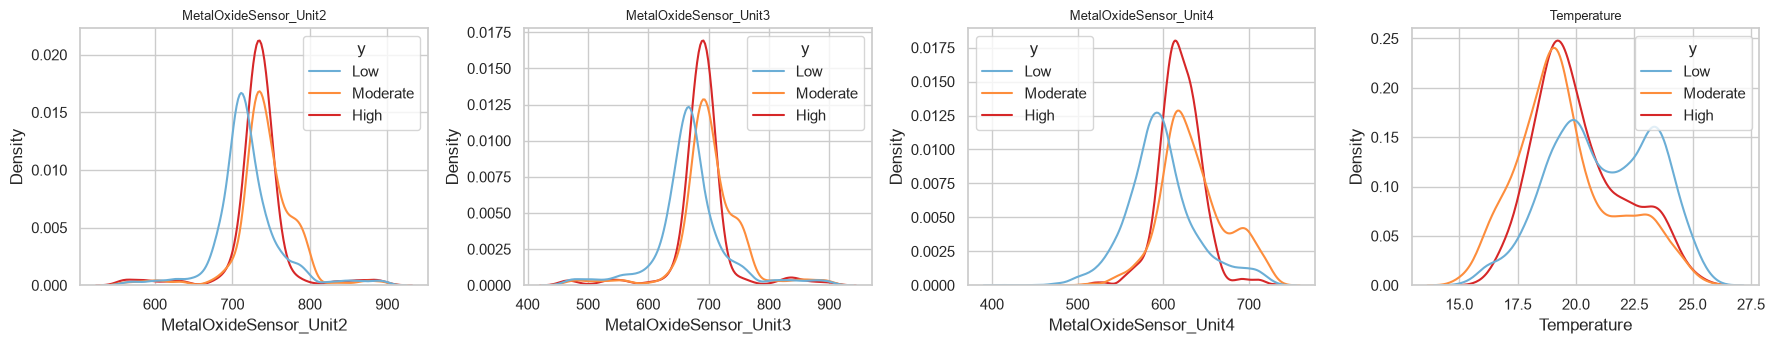

In [20]:
rows = []
for c in NUM + ORD:
    m = C[c].notna(); x = C.loc[m, c]; yy = y[m]; sd = x.groupby(yy).std()[ORDER]; lev = stats.levene(*[x[yy == k] for k in ORDER], center="median"); dev = (x - x.median()).abs()
    rows.append({"feature": c, **{f"sd {k}": sd[k] for k in ORDER}, "sd Low / sd High": sd["Low"] / sd["High"], "Levene_p": lev[1], "AUC |x-median|: Low vs rest": roc_auc_score(yy == "Low", dev)})
HT = pd.DataFrame(rows).set_index("feature"); display(HT.round(3))
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, c in zip(ax, ["MetalOxideSensor_Unit2", "MetalOxideSensor_Unit3", "MetalOxideSensor_Unit4", "Temperature"]):
    sns.kdeplot(data=pd.DataFrame({c: C[c], "y": y}), x=c, hue="y", hue_order=ORDER, palette=PAL, common_norm=False, ax=a); a.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

**Observation / implication.** Spread differs by class: High-activity rows are the **tightest** (MOS4 sd 24.7 vs 41.9 for Low, ratio 1.70; CO_GasSensor ratio 1.42; MOS Unit1 1.43), and Levene's test rejects equal variance for every sensor (p < 0.001, though with n ~10k even small differences are significant). Yet the absolute deviation from the median separates Low from the rest only weakly (AUC 0.47-0.62; most sensors 0.51-0.55, best 0.62 for the ordinal CO_GasSensor). So variance structure is real but a minor additional signal; it explains why Low rows own the extreme tails (MOS2/MOS3 outliers) without making 'distance from the centre' a strong standalone predictor.

## 6a. Categorical effect sizes with bootstrap CIs
**Purpose.** Cramer's V, mutual information, % difference of each category from the overall class mix, and a bootstrap 95% CI for the gap between the extreme categories (selected on the full data, so the CI is optimistic).

,cramers_V,chi2_p,MI_nats,MI/H(y),extreme_hi,extreme_lo,gap_P(Low)_pp,CI_lo,CI_hi
feature,,,,,,,,,
Time of Day,0.1368,0.0000,0.0190,0.0206,evening,morning,22.8120,20.1928,25.3613
HVAC Operation Mode,0.0235,0.3677,0.0006,0.0006,ventilation_only,maintenance_mode,3.8494,0.5546,7.4361
Ambient Light Level,0.0144,0.9442,0.0002,0.0002,very_dim,dim,3.5745,-2.4941,9.7492
CO_GasSensor,0.2324,0.0000,0.0557,0.0604,high,extremely low,46.2964,41.5855,50.5707



Time of Day


,P(Low),P(Moderate),P(High),n,Low vs overall (pp),High vs overall (pp)
Time of Day,,,,,,
afternoon,0.511,0.379,0.110,2562,-6.773,0.072
evening,0.713,0.201,0.086,2443,13.399,-2.339
morning,0.485,0.401,0.115,2421,-9.415,0.548
night,0.609,0.264,0.127,2414,3.070,1.741



HVAC Operation Mode


,P(Low),P(Moderate),P(High),n,Low vs overall (pp),High vs overall (pp)
HVAC Operation Mode,,,,,,
cooling_active,0.588,0.313,0.099,1677,0.930,-1.036
eco_mode,0.581,0.315,0.103,1614,0.251,-0.588
heating_active,0.581,0.301,0.118,1657,0.191,0.894
maintenance_mode,0.556,0.328,0.116,1675,-2.284,0.707
off,0.573,0.320,0.107,1612,-0.546,-0.265
ventilation_only,0.594,0.294,0.112,1605,1.511,0.280



Ambient Light Level


,P(Low),P(Moderate),P(High),n,Low vs overall (pp),High vs overall (pp)
Ambient Light Level,,,,,,
bright,0.577,0.311,0.112,2152,-0.199,0.310
dim,0.555,0.321,0.123,713,-2.326,1.407
missing,0.582,0.313,0.105,2516,0.322,-0.442
moderate,0.578,0.319,0.103,1235,-0.052,-0.652
very_bright,0.582,0.308,0.110,2803,0.286,0.089
very_dim,0.591,0.299,0.109,421,1.279,-0.009



CO_GasSensor


,P(Low),P(Moderate),P(High),n,Low vs overall (pp),High vs overall (pp)
CO_GasSensor,,,,,,
extremely high,0.972,0.028,0.000,71,39.317,-10.935
extremely low,0.388,0.553,0.059,1094,-19.109,-4.993
high,0.849,0.102,0.048,392,27.083,-6.088
low,0.474,0.370,0.156,4274,-10.486,4.694
medium,0.767,0.164,0.069,2644,18.836,-4.051
missing,0.597,0.299,0.104,1365,1.841,-0.532


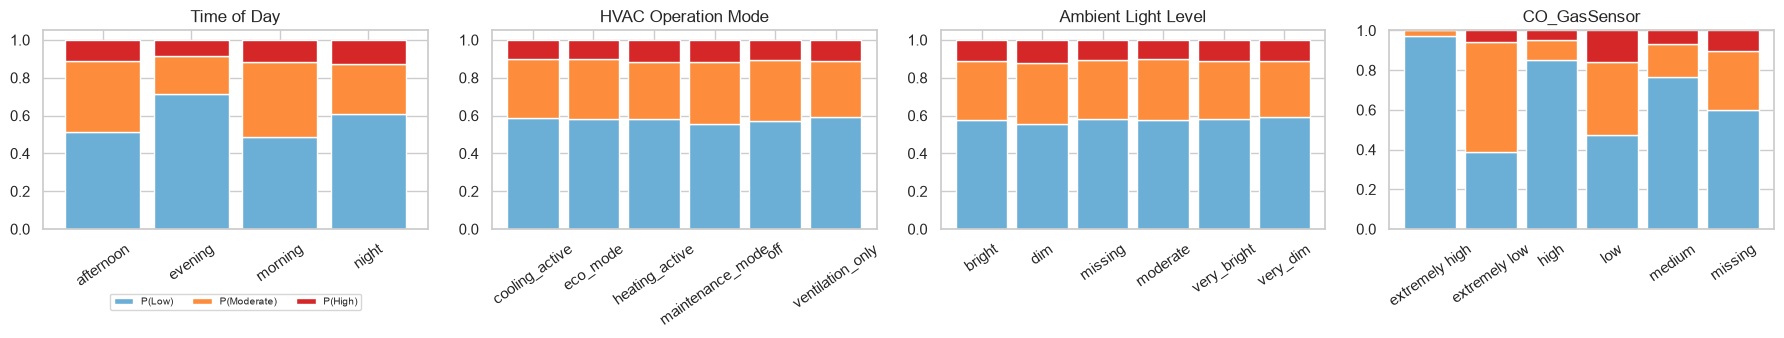

In [21]:
cats = {"Time of Day": C["Time of Day"], "HVAC Operation Mode": C["HVAC Operation Mode"], "Ambient Light Level": d["Ambient Light Level"].fillna("missing"), "CO_GasSensor": d["CO_GasSensor"].fillna("missing")}
Hy = stats.entropy(y.value_counts(normalize=True)); overall = y.value_counts(normalize=True)[ORDER]; rng = np.random.RandomState(0); summ = []; tabs = {}
for n, s in cats.items():
    ct = pd.crosstab(s, y)[ORDER]; Pm = ct.div(ct.sum(1), axis=0); chi2, p, _, _ = stats.chi2_contingency(ct)
    tab = Pm.copy(); tab.columns = [f"P({k})" for k in ORDER]; tab["n"] = ct.sum(1); tab["Low vs overall (pp)"] = 100 * (Pm["Low"] - overall["Low"]); tab["High vs overall (pp)"] = 100 * (Pm["High"] - overall["High"]); tabs[n] = tab
    ok = tab[tab["n"] >= 100]; lo, hi = ok["P(Low)"].idxmin(), ok["P(Low)"].idxmax(); a, b = (s == hi).values, (s == lo).values; yl = (y == "Low").values
    gaps = []
    for _ in range(1000):
        i = rng.randint(0, len(s), len(s)); gaps.append(yl[i][a[i]].mean() - yl[i][b[i]].mean())
    summ.append({"feature": n, "cramers_V": cramers_v(ct), "chi2_p": p, "MI_nats": mutual_info_score(s, y), "MI/H(y)": mutual_info_score(s, y) / Hy, "extreme_hi": hi, "extreme_lo": lo, "gap_P(Low)_pp": 100 * np.mean(gaps), "CI_lo": 100 * np.percentile(gaps, 2.5), "CI_hi": 100 * np.percentile(gaps, 97.5)})
display(pd.DataFrame(summ).set_index("feature").round(4))
for n, t in tabs.items(): print("\n" + n); display(t.round(3))
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, (n, t) in zip(ax, tabs.items()):
    t[[f"P({k})" for k in ORDER]].plot.bar(stacked=True, ax=a, color=[PAL[k] for k in ORDER], legend=False, width=.85); a.set_title(n); a.set_xlabel(""); a.tick_params(axis="x", rotation=35)
ax[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3); plt.tight_layout(); plt.show()

**Observation / implication.** **CO_GasSensor is the strongest categorical driver (Cramer's V 0.232, MI/H(y) 6.0%)**: P(Low) rises monotonically from 0.388 ('extremely low') to 0.474, 0.767, 0.849 and 0.972 ('extremely high'; only 71 rows, no High at all), a 46-point extreme gap (bootstrap CI 41.6-50.6, selected on the full data so slightly optimistic); missing CO rows look average (0.597). **Time of Day** is real but smaller (V 0.137; evening P(Low) 0.713 vs morning 0.485, gap 22.8 pp, CI 20.2-25.4). **HVAC mode (V 0.024, p = 0.37) and Ambient Light (V 0.014, p = 0.94) have no usable effect**: the HVAC extreme gap of 3.8 pp has a CI of 0.6-7.4 only because the extremes were cherry-picked among six near-identical categories, and the Light gap CI (-2.5 to 9.7) includes 0. Time of Day is a significant, moderate effect; HVAC mode and Ambient Light are null effects.

## 6b. Is Time of Day a real effect or a confound of the sensors?
**Purpose.** Check whether sensor readings differ by time of day or HVAC mode (eta-squared), and whether Time of Day still shifts the class mix *within* strata of the strongest sensor.

,Time of Day,HVAC Operation Mode
Temperature,0.5295,0.0004
Humidity,0.1840,0.0007
CO2_InfraredSensor,0.1448,0.0004
CO2_ElectroChemicalSensor,0.0478,0.0003
MetalOxideSensor_Unit1,0.2131,0.0002
MetalOxideSensor_Unit2,0.0826,0.0010
MetalOxideSensor_Unit3,0.0540,0.0005
MetalOxideSensor_Unit4,0.2091,0.0005
CO_GasSensor,0.1186,0.0003
Ambient Light Level,0.0012,0.0010


P(Low) by Time of Day within MOS4 tertiles


MetalOxideSensor_Unit4,low MOS4,mid MOS4,high MOS4
Time of Day,,,
afternoon,0.869,0.499,0.376
evening,0.883,0.589,0.316
morning,0.852,0.500,0.348
night,0.854,0.464,0.340


cell counts


MetalOxideSensor_Unit4,low MOS4,mid MOS4,high MOS4
Time of Day,,,
afternoon,520,725,1317
evening,1279,895,269
morning,459,656,1306
night,1024,1002,388


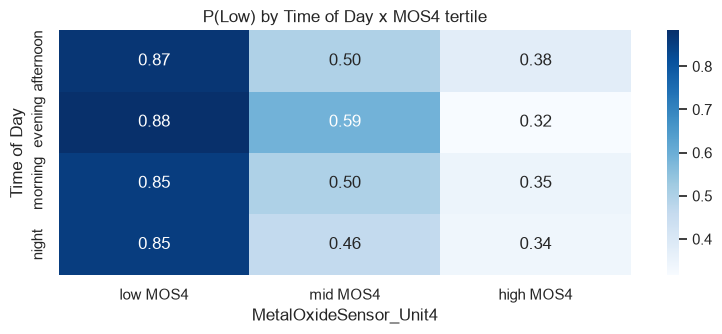

In [22]:
cf = pd.DataFrame({k: {c: eta_sq(C[c], C[k]) for c in NUM + ORD} for k in CAT}); display(cf.round(4))
top = "MetalOxideSensor_Unit4"; tert = pd.qcut(C[top], 3, labels=["low MOS4", "mid MOS4", "high MOS4"])
pl = (y == "Low").groupby([C["Time of Day"], tert]).mean().unstack().round(3); nn = y.groupby([C["Time of Day"], tert]).size().unstack()
print("P(Low) by Time of Day within MOS4 tertiles"); display(pl); print("cell counts"); display(nn)
fig, ax = plt.subplots(figsize=(8, 3.5)); sns.heatmap(pl, annot=True, fmt=".2f", cmap="Blues", ax=ax); ax.set_title("P(Low) by Time of Day x MOS4 tertile"); plt.tight_layout(); plt.show()

**Observation / implication.** Time of Day is substantially a **confound of the sensors**: it explains 53% of Temperature, 21% of MOS Unit1/Unit4 and 18% of Humidity variance, while HVAC mode explains < 0.1% of any sensor. The raw Time effect on P(Low) (evening 0.71) shrinks once MOS Unit4 is held fixed: within the low-MOS4 stratum P(Low) is 0.85-0.88 in every period, within the high stratum 0.32-0.38, and only the mid stratum keeps a spread (0.46-0.59, evening highest). The evening effect is therefore mostly 'evening has more low-MOS4 rows' (1,279 of 2,443 evening rows vs 459 of 2,421 morning rows); a residual evening effect remains in the middle tertile. Implication: Time of Day adds little beyond the sensors, which agrees with its low permutation importance in the earlier model run.

## 7. Interactions between categoricals
**Purpose.** Target means by combination of two categoricals with the **row count per cell**; cells with n<30 are masked. A two-way test compares R2 of main effects vs main effects + interaction (delta R2, F-test).

,R2_main,R2_with_interaction,dR2_interaction,F,p,n_interaction_terms
Time x HVAC,0.02167,0.02365,0.00198,1.32698,0.17589,15.0
Time x CO,0.07761,0.08070,0.00308,2.19490,0.00486,15.0
HVAC x CO,0.07011,0.07227,0.00217,0.91712,0.58176,25.0
Time x Light,0.02135,0.02366,0.00231,1.54954,0.07936,15.0
HVAC x Light,0.00086,0.00357,0.00271,1.06745,0.37200,25.0


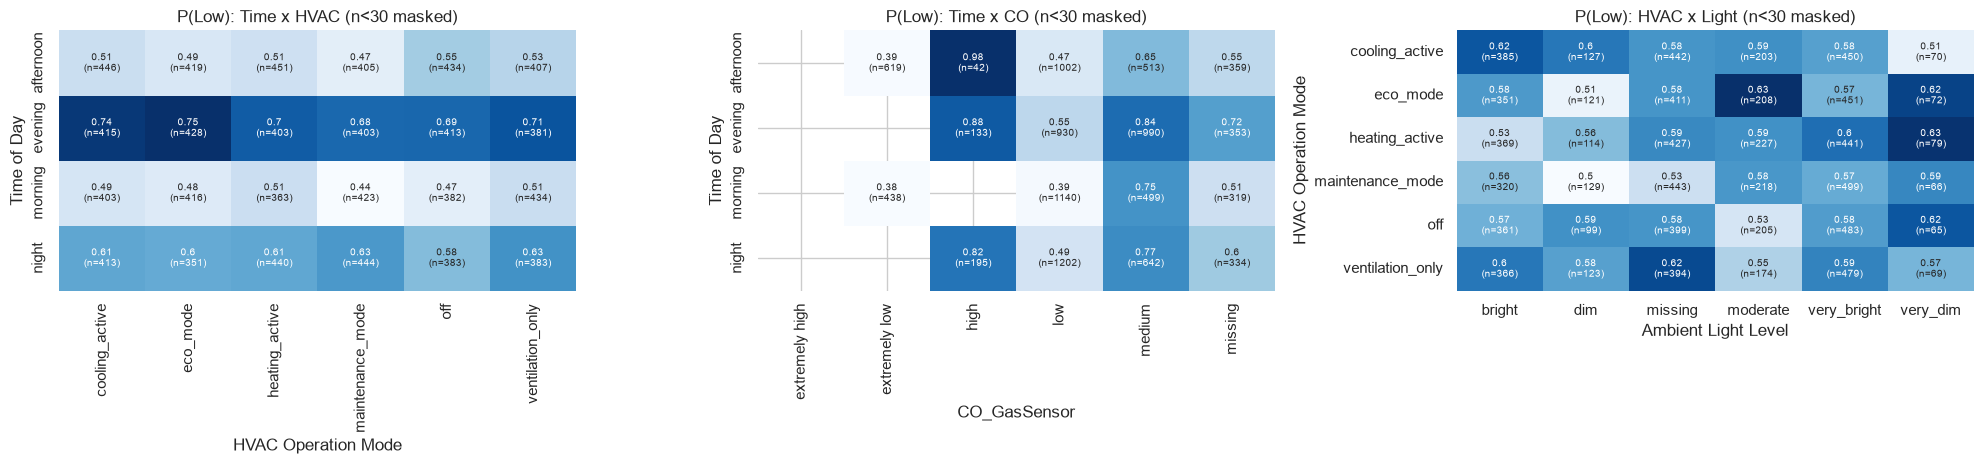

cells with n<30: {'TimexHVAC': 0, 'TimexCO': 7, 'HVACxLight': 0} | min cell n: {'TimexHVAC': 351, 'TimexCO': 3, 'HVACxLight': 65}


In [23]:
cat2 = {"Time": C["Time of Day"], "HVAC": C["HVAC Operation Mode"], "Light": d["Ambient Light Level"].fillna("missing"), "CO": d["CO_GasSensor"].fillna("missing")}
def inter_test(a, b):
    A = pd.get_dummies(a, drop_first=True).astype(float); Bd = pd.get_dummies(b, drop_first=True).astype(float); main = np.c_[np.ones(len(a)), A.values, Bd.values]
    inter = np.column_stack([A[i].values * Bd[j].values for i in A for j in Bd]); full = np.c_[main, inter]; cc = code.values
    def r2_(X): bb = np.linalg.lstsq(X, cc, rcond=None)[0]; return 1 - ((cc - X @ bb) ** 2).sum() / ((cc - cc.mean()) ** 2).sum()
    rm, rf = r2_(main), r2_(full); df1, df2 = inter.shape[1], len(cc) - full.shape[1]; F = ((rf - rm) / df1) / ((1 - rf) / df2)
    return {"R2_main": rm, "R2_with_interaction": rf, "dR2_interaction": rf - rm, "F": F, "p": 1 - stats.f.cdf(F, df1, df2), "n_interaction_terms": df1}
pairs = [("Time", "HVAC"), ("Time", "CO"), ("HVAC", "CO"), ("Time", "Light"), ("HVAC", "Light")]
display(pd.DataFrame({f"{a} x {b}": inter_test(cat2[a], cat2[b]) for a, b in pairs}).T.round(5))
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8)); cell_n = {}
for a, (p, q) in zip(ax, [("Time", "HVAC"), ("Time", "CO"), ("HVAC", "Light")]):
    pl = (y == "Low").groupby([cat2[p], cat2[q]]).mean().unstack(); nn = y.groupby([cat2[p], cat2[q]]).size().unstack().fillna(0); cell_n[(p, q)] = nn
    lab = pl.round(2).astype(str) + "\n(n=" + nn.astype(int).astype(str) + ")"; sns.heatmap(pl.where(nn >= 30), annot=lab, fmt="", cmap="Blues", ax=a, annot_kws={"size": 7}, cbar=False); a.set_title(f"P(Low): {p} x {q} (n<30 masked)")
plt.tight_layout(); plt.show()
print("cells with n<30:", {f"{p}x{q}": int((n < 30).sum().sum()) for (p, q), n in cell_n.items()}, "| min cell n:", {f"{p}x{q}": int(n.values.min()) for (p, q), n in cell_n.items()})

**Observation / implication.** No categorical interaction is practically meaningful. The two-way interaction adds at most **0.003 to R2** (Time x CO: dR2 = 0.0031, F-test p = 0.005; the other pairs have dR2 <= 0.0027 and p >= 0.08), against main-effect R2 of 0.078 for Time + CO and 0.001 for HVAC + Light. The Time x CO test is the only one with p < 0.05 and it is practically negligible (dR2 = 0.003); 7 of its 24 cells have n < 30 (smallest n = 3) and are masked. In the heatmaps, Time x HVAC is purely additive (evening is ~0.70 for every HVAC mode, morning ~0.47), P(Low) is ordered 'low' < 'medium' < 'high' CO in every period where cells are large enough, and HVAC x Light is unstructured noise (cells 0.50-0.63, min n = 65). Any striking single cell in the heatmaps is a hypothesis backed by few rows, not a finding.

## 8a. Outliers: extreme vs typical rows (per feature)
**Purpose.** For each heavy-tailed feature compare the target for rows outside 1.5xIQR with typical rows (Mann-Whitney on the ordered code and rank-biserial effect size, plus class shares).

,kurtosis,n_extreme,n_low_tail,n_high_tail,rank_biserial(code),MW_p,P(High|ext),P(High|typ),P(Low|ext),P(Low|typ)
feature,,,,,,,,,,
Temperature,-0.861,0,0,0,NaN,NaN,NaN,0.109,NaN,0.579
Humidity,-0.645,0,0,0,NaN,NaN,NaN,0.109,NaN,0.580
CO2_InfraredSensor,3.122,382,232,150,0.015,0.568,0.065,0.111,0.542,0.580
CO2_ElectroChemicalSensor,0.540,9,9,0,NaN,NaN,0.000,0.110,0.556,0.578
MetalOxideSensor_Unit1,0.670,616,117,499,0.040,0.062,0.028,0.115,0.498,0.584
MetalOxideSensor_Unit2,3.868,671,362,309,-0.034,0.098,0.119,0.109,0.618,0.576
MetalOxideSensor_Unit3,3.498,717,407,310,-0.088,0.000,0.079,0.113,0.656,0.572
MetalOxideSensor_Unit4,0.411,297,100,197,-0.041,0.175,0.017,0.112,0.579,0.579


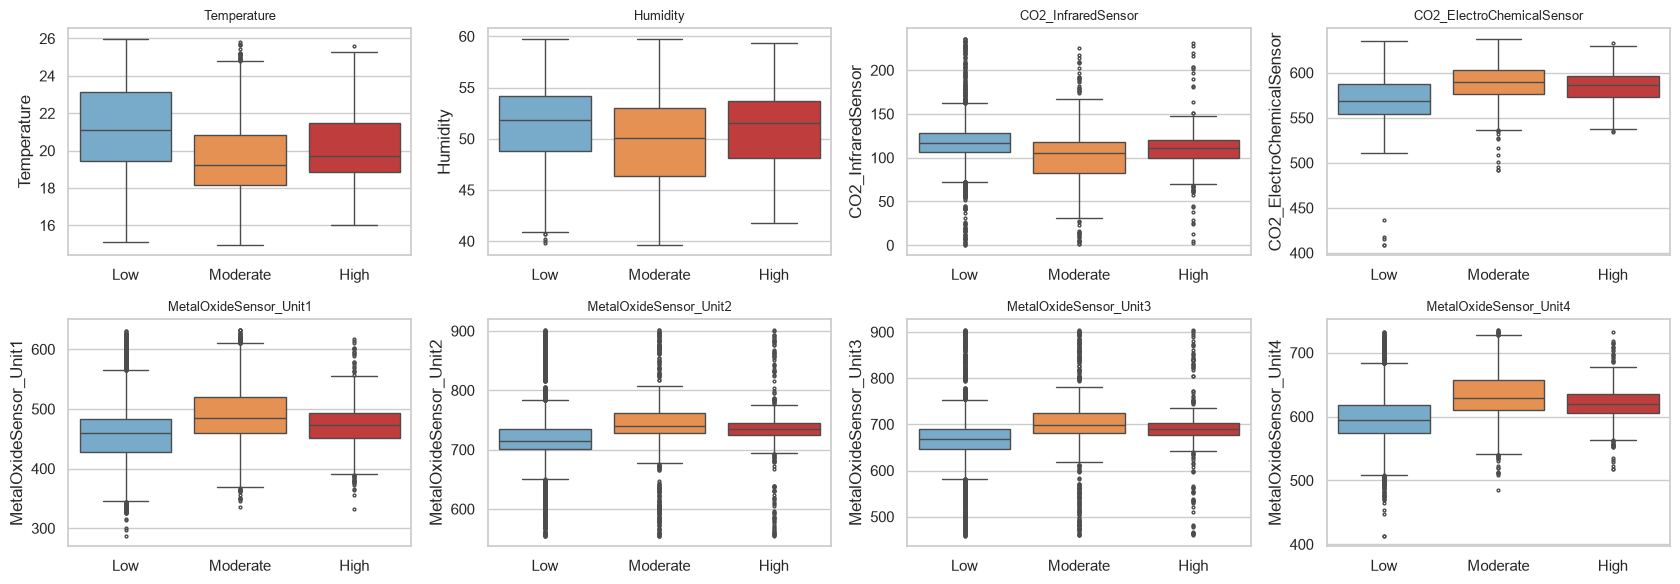

In [24]:
rows = []
for c in NUM:
    x = C[c]; q1, q3 = x.quantile(.25), x.quantile(.75); iqr = q3 - q1; lo_t, hi_t = x < q1 - 1.5 * iqr, x > q3 + 1.5 * iqr; ext = lo_t | hi_t
    m = x.notna() & ext; t = x.notna() & ~ext
    rows.append({"feature": c, "kurtosis": x.kurt(), "n_extreme": int(ext.sum()), "n_low_tail": int(lo_t.sum()), "n_high_tail": int(hi_t.sum()), "rank_biserial(code)": rank_biserial(code[m], code[t]) if ext.sum() > 10 else np.nan,
                 "MW_p": stats.mannwhitneyu(code[m], code[t])[1] if ext.sum() > 10 else np.nan, "P(High|ext)": (y[m] == "High").mean(), "P(High|typ)": (y[t] == "High").mean(), "P(Low|ext)": (y[m] == "Low").mean(), "P(Low|typ)": (y[t] == "Low").mean()})
OF = pd.DataFrame(rows).set_index("feature"); display(OF.round(3))
fig, ax = plt.subplots(2, 4, figsize=(17, 6))
for a, c in zip(ax.ravel(), NUM): sns.boxplot(data=pd.DataFrame({c: C[c], "y": y}), x="y", y=c, order=ORDER, palette=PAL, ax=a, fliersize=2); a.set_title(c, fontsize=9); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Observation / implication.** Outliers (beyond 1.5xIQR) exist only in CO2 infrared (382 rows) and MOS Units 1-4 (616/671/717/297 rows); Temperature, Humidity and CO2 EC have essentially none after repair. Their relation to the target is small: rank-biserial effect sizes are at most 0.09 in absolute value, and only MOS Unit3's is clearly significant (-0.088, p < 0.001: extreme Unit3 rows are *more* often Low, 0.656 vs 0.572). For Unit1 the extreme rows have P(High) 0.028 vs 0.115 typical (note: n of extremes is moderate). Boxplots show the heavy tails belong to the Low class. Verdict: extreme readings are mildly informative sensor excursions rather than errors, so deleting them would discard signal; mild winsorising (1%/99%) is the right treatment.

## 8b. The target's own extremes and multivariate outliers
**Purpose.** Profile the rare High class (mean z-score of each feature by class) and test whether multivariate outliers (Isolation Forest) have a different class mix.

Activity Level               Low  Moderate   High
inlier                     0.582     0.304  0.114
multivariate outlier (5%)  0.512     0.459  0.028
n outliers: 492 | rank-biserial(code) = 0.026 | MW p = 0.26075542471879387


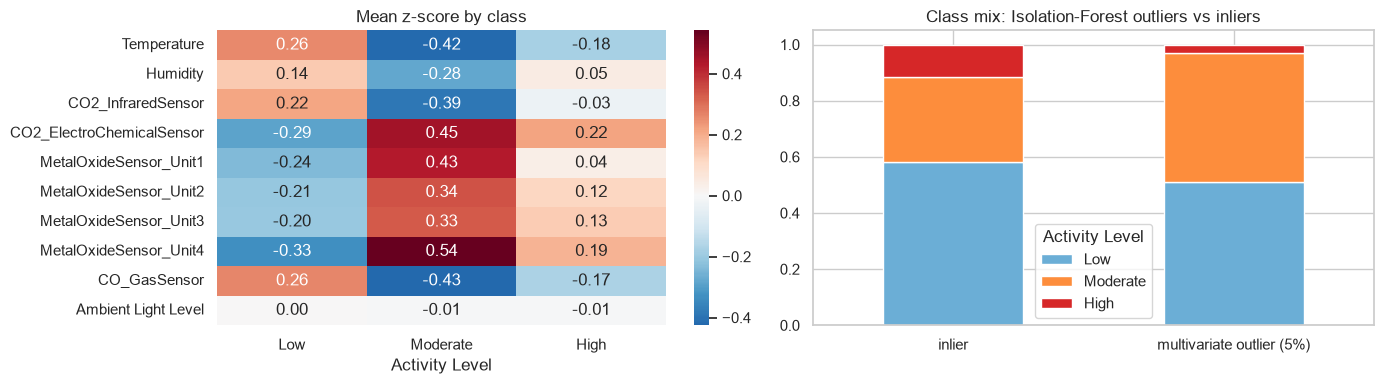

In [25]:
Z = (C[NUM + ORD] - C[NUM + ORD].mean()) / C[NUM + ORD].std(); zc = Z.groupby(y).mean().loc[ORDER].T
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); sns.heatmap(zc, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Mean z-score by class")
Xi = C[NUM + ORD].fillna(C[NUM + ORD].median()); iso = IsolationForest(contamination=0.05, random_state=0).fit(Xi); out = iso.predict(Xi) == -1
mix = pd.crosstab(out, y, normalize="index")[ORDER].round(3); mix.index = ["inlier", "multivariate outlier (5%)"]; print(mix); print("n outliers:", int(out.sum()), "| rank-biserial(code) =", round(rank_biserial(code[out], code[~out]), 3), "| MW p =", stats.mannwhitneyu(code[out], code[~out])[1])
mix.plot.bar(stacked=True, ax=ax[1], color=[PAL[k] for k in ORDER]); ax[1].set_title("Class mix: Isolation-Forest outliers vs inliers"); ax[1].tick_params(axis="x", rotation=0); plt.tight_layout(); plt.show()

**Observation / implication.** The rare High class has a distinct profile: on every sensor the High class sits between the Low and Moderate class means (heatmap), consistent with section 5c. Multivariate outliers (Isolation Forest, 5% = 492 rows) have a different class mix (Moderate 0.459 vs 0.304; High 0.028 vs 0.114), yet the rank-biserial on the ordered code is only 0.026 (p = 0.26) because the shifts partially cancel on the Low-Moderate-High scale. Verdict: no outlier-removal step is justified; outliers are a mild marker of Moderate (and of 'not High') rather than errors.

## 9. Session structure: between-session vs within-session signal
**Purpose.** Rows are grouped in 38 sessions. Split each feature's variance into between-session (ICC = eta-squared by session) and within-session parts, and check whether the feature-target relation holds *within* sessions or only *between* them.

,ICC_session(feature),spearman_pooled,spearman_between_sessions(38 means),spearman_within_sessions
feature,,,,
Temperature,0.224,-0.285,-0.652,-0.192
Humidity,0.459,-0.131,-0.796,0.080
CO2_InfraredSensor,0.240,-0.256,-0.715,-0.153
CO2_ElectroChemicalSensor,0.819,0.325,0.735,0.161
MetalOxideSensor_Unit1,0.238,0.263,0.591,0.202
MetalOxideSensor_Unit2,0.161,0.366,0.883,0.200
MetalOxideSensor_Unit3,0.136,0.358,0.903,0.198
MetalOxideSensor_Unit4,0.355,0.402,0.868,0.227
CO_GasSensor,0.283,-0.292,-0.688,-0.183


ICC of the target code across sessions: 0.107


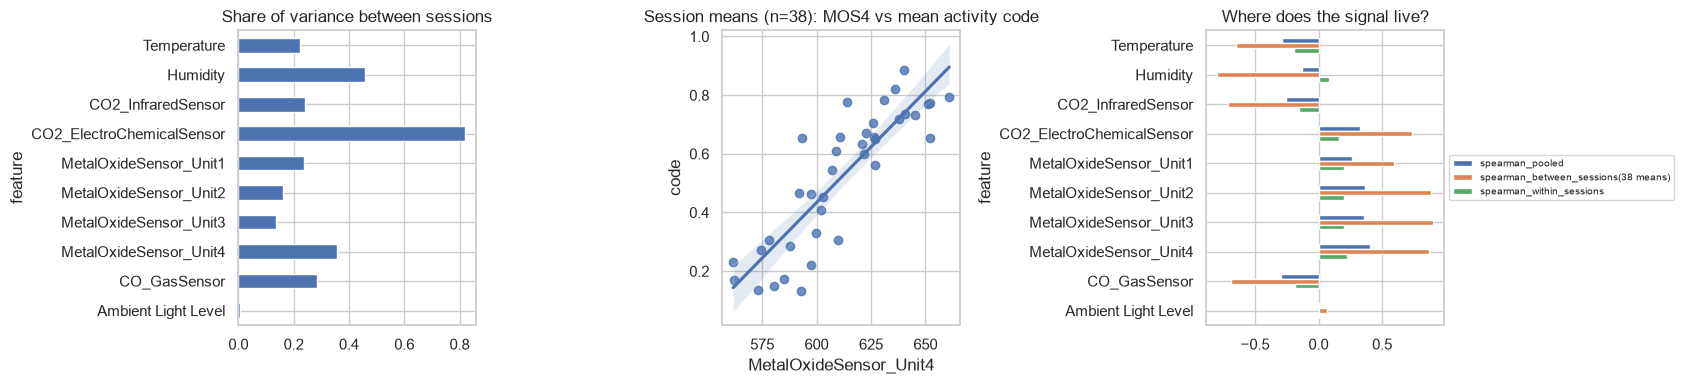

In [26]:
g = C.assign(sess=sess, code=code); rows = []
for c in NUM + ORD:
    m = g[c].notna(); gm = g[m]; dm = gm[c] - gm.groupby("sess")[c].transform("mean"); dc = gm["code"] - gm.groupby("sess")["code"].transform("mean")
    sm = gm.groupby("sess")[[c, "code"]].mean()
    rows.append({"feature": c, "ICC_session(feature)": eta_sq(gm[c], gm["sess"]), "spearman_pooled": stats.spearmanr(gm[c], gm["code"])[0], "spearman_between_sessions(38 means)": stats.spearmanr(sm[c], sm["code"])[0], "spearman_within_sessions": stats.spearmanr(dm, dc)[0]})
SS = pd.DataFrame(rows).set_index("feature"); display(SS.round(3)); print("ICC of the target code across sessions:", round(eta_sq(code, sess), 3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4)); SS["ICC_session(feature)"].plot.barh(ax=ax[0]); ax[0].set_title("Share of variance between sessions"); ax[0].invert_yaxis()
sm = g.groupby("sess")[["MetalOxideSensor_Unit4", "code"]].mean(); sns.regplot(data=sm, x="MetalOxideSensor_Unit4", y="code", ax=ax[1]); ax[1].set_title("Session means (n=38): MOS4 vs mean activity code")
SS[["spearman_pooled", "spearman_between_sessions(38 means)", "spearman_within_sessions"]].plot.barh(ax=ax[2]); ax[2].set_title("Where does the signal live?"); ax[2].invert_yaxis(); ax[2].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5)); plt.tight_layout(); plt.show()

**Observation / implication.** **Most of the signal is between sessions.** The session explains 82% of the CO2 electrochemical variance, 46% of Humidity, 36% of MOS Unit4 but only 11% of the target itself. Correlating the 38 session means gives Spearman 0.87-0.90 for MOS Units 2-4 and -0.80 for Humidity with the session's mean activity code, but within sessions (after removing session means) the same relations fall to 0.20-0.23 (MOS4 0.227, Temperature -0.19, CO_GasSensor -0.18). Pooled values (0.26-0.40) sit between the two. The 38-point session-level relation is therefore very strong while the within-session relation is weak, so a model that effectively identifies session context from the sensors gains score that will not transfer to new sessions. Ambient Light has no session or within-session relation (ICC 0.007).

## 10. Feature engineering candidates
**Purpose.** Propose engineered features, measure their relation with the target (Pearson, Spearman, eta-squared, mutual information) and compare each with its best parent to see whether it adds anything.

,pearson,spearman,eta2,MI,best_parent_eta2,best_parent_MI,beats_parent_eta2,beats_parent_MI
feature,,,,,,,,
temp_x_humidity,-0.2863,-0.3623,0.1444,0.1203,0.0972,0.0714,True,True
mos_pc1,0.2755,0.3728,0.1355,0.1422,0.1575,0.1616,False,False
co2_z_gap,0.2725,0.3528,0.1293,0.1038,0.1174,0.0987,True,True
co_x_mos4,0.3212,0.4324,0.1270,0.1245,0.1575,0.1536,False,False
mos_mean,0.2700,0.3479,0.1270,0.1013,0.1575,0.1616,False,False
MetalOxideSensor_Unit4_minus_session_mean,0.1704,0.2047,0.0657,0.0753,0.1575,0.1536,False,False
mos_u2_over_u4,-0.1757,-0.2720,0.0483,0.0845,0.1575,0.1616,False,False
Temperature_minus_session_mean,-0.1621,-0.1928,0.0466,0.0635,0.0972,0.0714,False,False
CO2_ElectroChemicalSensor_minus_session_mean,0.1011,0.1250,0.0388,0.0504,0.1174,0.0987,False,False



reference raw features (eta2 / MI):


,eta2,MI
feature,,
MetalOxideSensor_Unit4,0.1575,0.1536
CO2_ElectroChemicalSensor,0.1174,0.0987
CO_GasSensor,0.1005,0.0552
Temperature,0.0972,0.0714
MetalOxideSensor_Unit1,0.0890,0.0864
CO2_InfraredSensor,0.0747,0.0880
MetalOxideSensor_Unit2,0.0625,0.1616
MetalOxideSensor_Unit3,0.0601,0.1045
Humidity,0.0361,0.0521


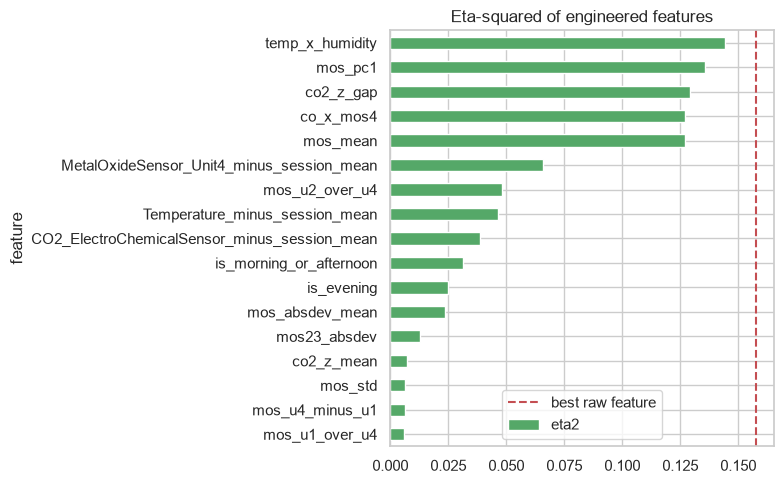

In [27]:
Zn = (C[NUM] - C[NUM].mean()) / C[NUM].std(); E = pd.DataFrame(index=C.index)
E["mos_mean"] = C[MOS].mean(axis=1); E["mos_std"] = C[MOS].std(axis=1)
E["mos_u4_minus_u1"] = C["MetalOxideSensor_Unit4"] - C["MetalOxideSensor_Unit1"]; E["mos_u2_over_u4"] = C["MetalOxideSensor_Unit2"] / C["MetalOxideSensor_Unit4"]; E["mos_u1_over_u4"] = C["MetalOxideSensor_Unit1"] / C["MetalOxideSensor_Unit4"]
zm = (C[["MetalOxideSensor_Unit1", "MetalOxideSensor_Unit2", "MetalOxideSensor_Unit4"]] - C[["MetalOxideSensor_Unit1", "MetalOxideSensor_Unit2", "MetalOxideSensor_Unit4"]].mean()) / C[["MetalOxideSensor_Unit1", "MetalOxideSensor_Unit2", "MetalOxideSensor_Unit4"]].std()
E["mos_pc1"] = PCA(1).fit_transform(zm)[:, 0]
E["co2_z_gap"] = Zn["CO2_ElectroChemicalSensor"] - Zn["CO2_InfraredSensor"]; E["co2_z_mean"] = (Zn["CO2_ElectroChemicalSensor"] + Zn["CO2_InfraredSensor"]) / 2
E["temp_x_humidity"] = C["Temperature"] * C["Humidity"] / 100; E["co_x_mos4"] = C["CO_GasSensor"] * Zn["MetalOxideSensor_Unit4"]
E["mos_absdev_mean"] = Zn[MOS].abs().mean(axis=1); E["mos23_absdev"] = (Zn["MetalOxideSensor_Unit2"].abs() + Zn["MetalOxideSensor_Unit3"].abs())
E["is_evening"] = (C["Time of Day"] == "evening").astype(float); E["is_morning_or_afternoon"] = C["Time of Day"].isin(["morning", "afternoon"]).astype(float)
for c in ["MetalOxideSensor_Unit4", "Temperature", "CO2_ElectroChemicalSensor"]: E[f"{c}_minus_session_mean"] = C[c] - C.groupby(sess)[c].transform("mean")
parents = {"mos_mean": MOS, "mos_std": MOS, "mos_u4_minus_u1": ["MetalOxideSensor_Unit4", "MetalOxideSensor_Unit1"], "mos_u2_over_u4": ["MetalOxideSensor_Unit2", "MetalOxideSensor_Unit4"], "mos_u1_over_u4": ["MetalOxideSensor_Unit1", "MetalOxideSensor_Unit4"],
           "mos_pc1": MOS[:2] + MOS[3:], "co2_z_gap": ["CO2_InfraredSensor", "CO2_ElectroChemicalSensor"], "co2_z_mean": ["CO2_InfraredSensor", "CO2_ElectroChemicalSensor"], "temp_x_humidity": ["Temperature", "Humidity"],
           "co_x_mos4": ["CO_GasSensor", "MetalOxideSensor_Unit4"], "mos_absdev_mean": MOS, "mos23_absdev": ["MetalOxideSensor_Unit2", "MetalOxideSensor_Unit3"], "is_evening": [], "is_morning_or_afternoon": [], "MetalOxideSensor_Unit4_minus_session_mean": ["MetalOxideSensor_Unit4"], "Temperature_minus_session_mean": ["Temperature"], "CO2_ElectroChemicalSensor_minus_session_mean": ["CO2_ElectroChemicalSensor"]}
imp = lambda df: df.fillna(df.median()); allf = pd.concat([C[NUM + ORD], E], axis=1)
mi = pd.Series(mutual_info_classif(imp(allf), y, random_state=0, n_neighbors=5), index=allf.columns)
rows = []
for c in E.columns:
    m = E[c].notna(); pe = max([B.loc[p, "eta2"] for p in parents[c]], default=np.nan); pm = max([mi[p] for p in parents[c]], default=np.nan)
    rows.append({"feature": c, "pearson": stats.pearsonr(E.loc[m, c], code[m])[0], "spearman": stats.spearmanr(E.loc[m, c], code[m])[0], "eta2": eta_sq(E[c], y), "MI": mi[c], "best_parent_eta2": pe, "best_parent_MI": pm})
FE = pd.DataFrame(rows).set_index("feature"); FE["beats_parent_eta2"] = FE["eta2"] > FE["best_parent_eta2"] * 1.05; FE["beats_parent_MI"] = FE["MI"] > FE["best_parent_MI"] * 1.05
FE = FE.sort_values("eta2", ascending=False); display(FE.round(4)); print("\nreference raw features (eta2 / MI):"); display(pd.DataFrame({"eta2": B["eta2"], "MI": mi[B.index]}).round(4))
fig, ax = plt.subplots(figsize=(8, 5)); FE["eta2"].plot.barh(ax=ax, color="#55a868"); ax.axvline(B["eta2"].max(), color="r", ls="--", label="best raw feature"); ax.invert_yaxis(); ax.legend(); ax.set_title("Eta-squared of engineered features"); plt.tight_layout(); plt.show()

**Observation / implication.** Only a few engineered features beat their best parent, and only slightly: `temp_x_humidity` (eta-squared 0.144 vs Temperature 0.097; MI 0.120 vs 0.071) and `co2_z_gap` (0.129 vs 0.117; MI 0.104 vs 0.099, using the negative CO2 relation) are the only ones that do. `mos_pc1` (0.136) and `co_x_mos4` (0.127) come close to but do not beat MOS Unit4 (0.158), `mos_mean` (0.127) is a diluted version of Unit4, and `mos_std`, `mos_u4_minus_u1`, `mos_u1_over_u4`, `co2_z_mean` and the absolute-deviation features are near zero (<= 0.023). Session-centred features (value minus session mean) have lower eta-squared than their parents (0.039-0.066) and would also require observing a whole session at inference. Priority list: (1) temp_x_humidity, (2) co2_z_gap, (3) mos_pc1 as a dimensionality reducer (not better than Unit4), (4) everything else only as optional candidates. This agrees with the earlier ablation: engineered features did not improve the tuned model. Univariate eta-squared cannot see interactions, so a candidate can still help a tree model, but the evidence so far is weak.

## 11. How predictable is the target? (ceiling estimate)
**Purpose.** A rough ceiling: cross-validated scores of a strong generic learner (histogram gradient boosting) on all cleaned features, under random vs grouped (by session) CV, with and without the engineered features, plus a learning curve. These are EDA diagnostics, not the modelling result.

,macro_F1,balanced_acc,neg_logloss,macro_AUC,macro_F1_sd
"raw features, random CV",0.511,0.511,-0.749,0.786,0.012
"raw features, grouped CV",0.450,0.461,-0.818,0.738,0.024
"+ engineered, grouped CV",0.452,0.460,-0.824,0.738,0.016
"naive prior, grouped CV",0.243,0.333,-0.928,0.500,0.018


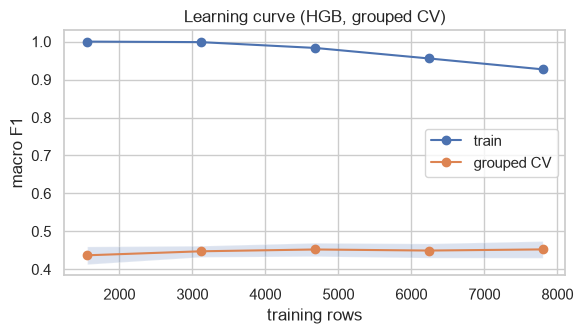

validation macro-F1 by training size: {1559: np.float64(0.437), 3118: np.float64(0.448), 4678: np.float64(0.452), 6237: np.float64(0.45), 7797: np.float64(0.453)}


In [28]:
Xf = pd.concat([C[NUM + ORD], pd.get_dummies(C[CAT]).astype(float)], axis=1); Xe = pd.concat([Xf, E[[c for c in E.columns if "session_mean" not in c]]], axis=1)
sc = {"macro_F1": "f1_macro", "balanced_acc": "balanced_accuracy", "neg_logloss": "neg_log_loss", "macro_AUC": "roc_auc_ovr"}; rows = {}
for name, X_, cv_, grp in [("raw features, random CV", Xf, sk, None), ("raw features, grouped CV", Xf, gk, sess), ("+ engineered, grouped CV", Xe, gk, sess)]:
    r = cross_validate(HGB(random_state=0), X_, y, cv=cv_, groups=grp, scoring=sc, n_jobs=5); rows[name] = {k: r[f"test_{k}"].mean() for k in sc} | {"macro_F1_sd": r["test_macro_F1"].std()}
from sklearn.dummy import DummyClassifier
r = cross_validate(DummyClassifier(strategy="prior"), Xf, y, cv=gk, groups=sess, scoring=sc); rows["naive prior, grouped CV"] = {k: r[f"test_{k}"].mean() for k in sc} | {"macro_F1_sd": r["test_macro_F1"].std()}
display(pd.DataFrame(rows).T.round(3))
ts, trs, vs = learning_curve(HGB(random_state=0), Xf, y, groups=sess, cv=gk, train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], scoring="f1_macro", n_jobs=5)
fig, ax = plt.subplots(figsize=(6, 3.5)); ax.plot(ts, trs.mean(1), "o-", label="train"); ax.plot(ts, vs.mean(1), "o-", label="grouped CV"); ax.fill_between(ts, vs.mean(1) - vs.std(1), vs.mean(1) + vs.std(1), alpha=.2); ax.set_xlabel("training rows"); ax.set_ylabel("macro F1"); ax.legend(); ax.set_title("Learning curve (HGB, grouped CV)"); plt.tight_layout(); plt.show()
print("validation macro-F1 by training size:", dict(zip(ts.tolist(), vs.mean(1).round(3))))

**Observation / implication.** The data support only **modest predictability**. A strong generic learner (histogram gradient boosting, default settings) reaches macro-F1 0.511 and macro AUC 0.786 under random CV but **0.450 and 0.738 under grouped CV (sd 0.024 across folds)**, versus 0.243 / 0.500 for the naive prior. Adding the engineered features gives 0.445 (within noise: no gain). The learning curve is flat from ~3,000 training rows (0.448) to 7,800 (0.453) while the training score stays near 0.93-1.0, so the limit is signal, not sample size, and the models overfit. Expected ceiling for session-level generalisation with these sensors: macro-F1 about 0.45-0.50 and macro PR AUC about 0.50-0.55 (consistent with the earlier tuned models, 0.52 on test).

## 12. Synthesis
### Findings about the data
- **Target:** 3 classes (Low 57.9%, Moderate 31.2%, High 10.9%) under 6 label spellings; the class order is *not* monotonic in the sensors (Low < High < Moderate for MOS/CO2-EC; Low > High > Moderate for Temperature/CO2-IR).
- **Drivers (all small to moderate):** MOS Unit4 (eta-squared 0.158), CO2 electrochemical (0.117), CO_GasSensor (0.100; the strongest categorical effect, Cramer's V 0.23, P(Low) from 0.39 to 0.97 across levels), Temperature (0.097), MOS Unit1/2/3 and CO2 infrared (0.06-0.09). Time of Day is a moderate effect (V 0.14) that is largely mediated by the sensors. **HVAC mode and Ambient Light have no relation** to activity (V <= 0.024; eta-squared 0.000).
- **Non-linearity:** strong and non-monotonic for MOS Units 2-4 (decile-step R2 up to 0.17 vs linear 0.04-0.09; inverted-U for Unit4). Variance is class-dependent (High tightest). Categorical interactions are negligible (dR2 <= 0.003).
- **Outliers:** none are errors after repair; extremes are mild markers of Low-activity excursions, so they are informative.
- **Structure:** rows are temporal and clustered in 38 sessions; within-session autocorrelation is high (lag-1 0.5-0.9) and most of the feature-target association lives between sessions (session-mean Spearman up to 0.90, within-session about 0.2). The two CO2 sensors are *negatively* related (-0.80 within sessions, in all 38 sessions).
- **Leakage verdict:** no feature leaks; Session ID and row order do under random CV (Session-ID-only macro-F1 0.393 random vs 0.275 grouped; shuffled-label null 0.29). Drop both and split by session.
- **Ceiling:** grouped-CV macro-F1 about 0.45 (random CV 0.51) for gradient boosting; flat learning curve; expect macro PR AUC roughly 0.50-0.55.

### Implications for preprocessing and modelling (separate from the findings)
1. Collapse the 6 target spellings; drop 160 duplicates before splitting.
2. Repairs: Kelvin -> Celsius (804 rows); Humidity outside 0-100 (503) and negative CO2 infrared (22) -> NaN; lower-case HVAC; ordinal-encode CO_GasSensor and Ambient Light.
3. Missingness is MCAR: simple imputation is safe; missing flags are optional.
4. Winsorise mildly (1%/99%, train-fitted); do not delete outliers; no log transform needed.
5. Drop Session ID and never use row order as a feature; **split 70/15/15 and tune by whole sessions**; use class weighting and macro metrics (macro PR AUC primary, macro-F1 secondary) because of the imbalance.
6. Prefer non-linear learners (boosting, forests) and expect the high-capacity ones to overfit; regularise strongly. Treat this as a three-class problem, not an ordinal one.
7. Feature candidates, in priority order: temp_x_humidity, co2_z_gap; expect little or no gain. HVAC mode and Ambient Light can be dropped with negligible loss.
8. Report uncertainty: only 38 sessions, so validation/test sets of ~5 sessions are noisy; compare models using grouped CV, not one split.

### Caveats
The Kelvin and humidity repairs are assumptions; eta-squared and Spearman rely on class labels being correct; session-level correlations are based on 38 points; all effect sizes here are univariate.

### What this means for the problem statement
- **Fit between task and data:** the sensors carry real but modest information about activity (grouped-CV macro-F1 about 0.45, chance 0.24), so the output is a triage signal that needs human review, not a diagnosis.
- **Alert class matters:** High is the hardest and rarest class (10.9%, one-vs-rest AUC at most about 0.60), while Low vs the rest is easiest. If Low (inactivity) is the concerning class for the early-warning use case, it is also the class the sensors separate best; if High (agitation) is the concern, expect many false alarms at useful recall.
- **Generalisation:** because most of the signal is between sessions, performance on a genuinely new home or resident should be expected at or below the session-grouped estimates, and a per-resident baseline (a departure from usual routine) is a more natural early-warning rule than an absolute class.
- **Not covered:** a direct air-quality hazard detector (CO, CO2, temperature extremes), forecasting ahead in time, and any health-event validation: none of these have labels in the data.

---
# Part B: Cleaning, feature engineering, preprocessing pipeline and baselines (Phase 1B)

Everything below restarts from the raw database table (it does not reuse the EDA frames) and uses only classes defined in this notebook. Decisions come from the EDA synthesis (section 12): collapse the label spellings, drop duplicates, repair units and impossible values, drop `Session ID`, **split by whole sessions**, mild winsorising, median imputation, a few engineered features, macro PR AUC as the primary metric (imbalanced classes). The test set is created in section 15 and **not touched** until Phase 1C.

## 13. Data cleaning
**Purpose.** Apply the row-level steps once before the split (they use no statistics), then show what the stateless `DataCleaner` transformer does column by column.

In [29]:
df = prepare_rows(load_raw())                                    # one-off row-level steps
y_all = df[TARGET]; groups = df[GROUP]; X_all = df.drop(columns=[TARGET])
CLASSES = ["Low", "Moderate", "High"]; assert set(y_all) == set(CLASSES)
print("rows after label normalisation + duplicate removal:", len(df), "(10,000 raw) | class counts:", y_all.value_counts().reindex(CLASSES).to_dict())
NUMERIC_BASE = ["Temperature", "Humidity", "CO2_InfraredSensor", "CO2_ElectroChemicalSensor"] + MOS_COLUMNS + ["CO_GasSensor", "Ambient Light Level"]
CATEGORICAL = ["Time of Day", "HVAC Operation Mode"]
FLAG_SOURCES = ["Humidity", "CO2_InfraredSensor", "CO2_ElectroChemicalSensor", "MetalOxideSensor_Unit3", "CO_GasSensor", "Ambient Light Level"]
cleaner = DataCleaner(drop_columns=(GROUP,), ordinal_maps=ORDINAL_MAPS, add_missing_indicators=True, indicator_columns=tuple(FLAG_SOURCES))
Xc = cleaner.transform(X_all); clone(cleaner)                      # clone-safe
rep = pd.DataFrame({"before": [int((X_all["Temperature"] > 100).sum()), int(((X_all["Humidity"] < 0) | (X_all["Humidity"] > 100)).sum()), int((X_all["CO2_InfraredSensor"] < 0).sum()), X_all["HVAC Operation Mode"].nunique(), X_all.shape[1]],
                    "after": [int((Xc["Temperature"] > 100).sum()), int(((Xc["Humidity"] < 0) | (Xc["Humidity"] > 100)).sum()), int((Xc["CO2_InfraredSensor"] < 0).sum()), Xc["HVAC Operation Mode"].nunique(), Xc.shape[1]]},
                   index=["Kelvin temperatures (>100)", "Humidity outside 0-100", "Negative CO2 infrared", "HVAC spellings", "columns"])
display(rep)
print("range after cleaning: Temperature", Xc["Temperature"].agg(["min", "max"]).round(1).tolist(), "| Humidity", Xc["Humidity"].agg(["min", "max"]).round(1).tolist())
print("missing values per column after cleaning:", {k: int(v) for k, v in Xc.isna().sum().items() if v})
print("Session ID dropped from features:", GROUP not in Xc.columns, "| missing-indicator columns added:", [c for c in Xc.columns if c.endswith("__missing")])

rows after label normalisation + duplicate removal: 9840 (10,000 raw) | class counts: {'Low': 5694, 'Moderate': 3070, 'High': 1076}


,before,after
Kelvin temperatures (>100),804,0
Humidity outside 0-100,503,0
Negative CO2 infrared,22,0
HVAC spellings,23,6
columns,13,18


range after cleaning: Temperature [14.9, 26.0] | Humidity [39.6, 59.8]
missing values per column after cleaning: {'Humidity': 503, 'CO2_InfraredSensor': 22, 'CO2_ElectroChemicalSensor': 705, 'MetalOxideSensor_Unit3': 2550, 'CO_GasSensor': 1365, 'Ambient Light Level': 2516}
Session ID dropped from features: True | missing-indicator columns added: ['Humidity__missing', 'CO2_InfraredSensor__missing', 'CO2_ElectroChemicalSensor__missing', 'MetalOxideSensor_Unit3__missing', 'CO_GasSensor__missing', 'Ambient Light Level__missing']


**Observation / implication.** The row-level steps leave **9,840 rows** (160 duplicates removed, 6 label spellings collapsed to 3 classes: Low 5,694 / Moderate 3,070 / High 1,076). The transformer removes every defect found in the EDA: 804 Kelvin temperatures converted (range now 14.9-26.0 °C), 503 impossible humidity values and 22 negative CO2-infrared readings turned into NaN (so Humidity now has 503 missing and CO2 infrared 22), HVAC spellings 23 -> 6. Columns go from 13 to 18 (Session ID dropped, six missing-indicator flags added). The cleaner is stateless: nothing is imputed or scaled here, which happens later inside the pipeline so that its statistics come from training rows only. The cleaner is clone-safe (constructor parameters only).

## 14. Feature engineering as scikit-learn transformers
**Purpose.** Implement the EDA-prioritised engineered features (`temp_x_humidity`, `co2_z_gap`; optional `mos_pc1`) and a `Winsorizer` as clone-safe transformers. Everything data-dependent (CO2 standardisation constants, PCA, which columns to log-transform, clipping bounds) is learned in `fit`.

In [30]:
from sklearn.decomposition import PCA
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds engineered columns to a CLEANED dataframe. Constructor holds parameters only; statistics are learned in fit."""
    CO2 = ["CO2_InfraredSensor", "CO2_ElectroChemicalSensor"]; MOS_PC = ["MetalOxideSensor_Unit1", "MetalOxideSensor_Unit2", "MetalOxideSensor_Unit4"]
    LOG_CANDIDATES = ["Temperature", "Humidity", "CO2_InfraredSensor", "CO2_ElectroChemicalSensor", "MetalOxideSensor_Unit1", "MetalOxideSensor_Unit2", "MetalOxideSensor_Unit3", "MetalOxideSensor_Unit4"]
    def __init__(self, features=("temp_x_humidity", "co2_z_gap"), log_skew_threshold=1.0):
        self.features = features; self.log_skew_threshold = log_skew_threshold
    def fit(self, X, y=None):
        X = pd.DataFrame(X); self.feature_names_in_ = list(X.columns)
        if "co2_z_gap" in self.features: self.co2_mean_, self.co2_std_ = X[self.CO2].mean(), X[self.CO2].std()
        if "mos_pc1" in self.features:
            self.mos_mean_, self.mos_std_ = X[self.MOS_PC].mean(), X[self.MOS_PC].std()
            self.pca_ = PCA(1, random_state=0).fit(((X[self.MOS_PC] - self.mos_mean_) / self.mos_std_).fillna(0))
        sk = X[self.LOG_CANDIDATES].skew(); self.log_columns_ = [c for c in sk.index if sk[c] > self.log_skew_threshold]   # learned: columns to log-transform
        self.log_shift_ = {c: float(X[c].min()) for c in self.log_columns_}
        self.feature_names_out_ = self.feature_names_in_ + list(self.features) + [f"log_{c}" for c in self.log_columns_]
        return self
    def transform(self, X):
        X = X.copy()
        if "temp_x_humidity" in self.features: X["temp_x_humidity"] = X["Temperature"] * X["Humidity"] / 100
        if "co2_z_gap" in self.features:
            z = (X[self.CO2] - self.co2_mean_) / self.co2_std_; X["co2_z_gap"] = z["CO2_ElectroChemicalSensor"] - z["CO2_InfraredSensor"]
        if "mos_pc1" in self.features: X["mos_pc1"] = self.pca_.transform(((X[self.MOS_PC] - self.mos_mean_) / self.mos_std_).fillna(0))[:, 0]
        for c in self.log_columns_: X[f"log_{c}"] = np.log1p((X[c] - self.log_shift_[c]).clip(lower=0))
        return X
    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_out_)

class Winsorizer(BaseEstimator, TransformerMixin):
    """Clips each column to the [q_low, q_high] quantiles learned in fit (NaN-aware)."""
    def __init__(self, quantiles=(0.01, 0.99)):
        self.quantiles = quantiles
    def fit(self, X, y=None):
        X = pd.DataFrame(X); self.columns_ = list(X.columns); self.low_ = X.quantile(self.quantiles[0]).to_numpy(); self.high_ = X.quantile(self.quantiles[1]).to_numpy(); return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_)

fe = clone(FeatureEngineer(features=("temp_x_humidity", "co2_z_gap", "mos_pc1"))).fit(Xc.iloc[:3000])
out = fe.transform(Xc.iloc[3000:3005]); print("clone-safe; output columns:", [str(x) for x in fe.get_feature_names_out()][-4:], "| shape", out.shape)
print("columns learned for log transform (skew > 1) on this fit:", fe.log_columns_, "(EDA: all skewness within +/-0.45, so none)")
print("CO2 constants learned in fit:", fe.co2_mean_.round(1).to_dict(), "| PCA explained variance:", fe.pca_.explained_variance_ratio_.round(3).tolist())

clone-safe; output columns: ['Ambient Light Level__missing', 'temp_x_humidity', 'co2_z_gap', 'mos_pc1'] | shape (5, 21)
columns learned for log transform (skew > 1) on this fit: [] (EDA: all skewness within +/-0.45, so none)
CO2 constants learned in fit: {'CO2_InfraredSensor': 106.0, 'CO2_ElectroChemicalSensor': 591.9} | PCA explained variance: [0.754]


**Observation / implication.** Both transformers are clone-safe and learn from data only in `fit`: the CO2 standardisation constants (infrared mean 106.0, electrochemical 591.9 on the demo fit of 3,000 rows), the PCA for the optional `mos_pc1` (first component explains 75% of the variance of MOS Units 1, 2 and 4), the columns to log-transform and the Winsorizer's clipping bounds. The log-transform rule learned **no columns** (no train skewness above 1), matching the EDA finding that no transform is needed. The default engineered features are the two that beat their best parent in the EDA (`temp_x_humidity`, `co2_z_gap`); `mos_pc1` did not beat MOS Unit4 and is off by default. Caveat: the EDA showed these features add little, so whether they help is tested later (Phase 1C ablation).

## 15. Train / validation / test split (70/15/15, by session)
**Purpose.** Create the split and lock the test set. The EDA leakage audit showed that random row splits are optimistic (Session ID and neighbouring rows leak), so instead of a plain stratified split I split by **whole sessions** and, among 300 random session shuffles, keep the one whose class mix is closest to the overall mix (label proportions only, never model scores).

In [31]:
def group_split(y, groups, fractions=(0.70, 0.15, 0.15), n_seeds=300):
    y, groups = np.asarray(y), np.asarray(groups); classes = np.unique(y); overall = np.array([(y == k).mean() for k in classes])
    uniq = np.unique(groups); sizes = pd.Series(groups).value_counts(); best = None
    for seed in range(n_seeds):
        order = np.random.RandomState(seed).permutation(uniq); assign, cum = {}, 0
        for g in order:
            share = cum / len(y); assign[g] = 0 if share < fractions[0] else (1 if share < fractions[0] + fractions[1] else 2); cum += sizes[g]
        part = np.array([assign[g] for g in groups]); score = 0.0
        for p in range(3):
            m = part == p
            if m.sum() == 0: score = np.inf; break
            score += abs(m.mean() - fractions[p]) * 2 + np.abs(np.array([(y[m] == k).mean() for k in classes]) - overall).max()
        if best is None or score < best[0]: best = (score, seed, part)
    return (*[np.where(best[2] == p)[0] for p in range(3)], best[1])
tr, va, te, SPLIT_SEED = group_split(y_all, groups)
assert not (set(tr) & set(va) or set(tr) & set(te) or set(va) & set(te)) and len(tr) + len(va) + len(te) == len(df), "index overlap"
assert not (set(groups.iloc[tr]) & set(groups.iloc[va]) or set(groups.iloc[tr]) & set(groups.iloc[te]) or set(groups.iloc[va]) & set(groups.iloc[te])), "a session spans two splits"
X_tr, y_tr, g_tr = X_all.iloc[tr], y_all.iloc[tr], groups.iloc[tr]; X_va, y_va = X_all.iloc[va], y_all.iloc[va]
X_te, y_te = X_all.iloc[te], y_all.iloc[te]                      # LOCKED: only len() is used until Phase 1C
print(f"split seed {SPLIT_SEED} | train {len(tr)} ({groups.iloc[tr].nunique()} sessions) | validation {len(va)} ({groups.iloc[va].nunique()}) | test {len(X_te)} ({groups.iloc[te].nunique()}) | no index or session overlap (asserted)")
code_map = {"Low": 0, "Moderate": 1, "High": 2}; sp = {"train": y_tr, "validation": y_va, "test": y_te}
display(pd.DataFrame({k: v.value_counts(normalize=True).reindex(CLASSES) for k, v in sp.items()} | {"all": y_all.value_counts(normalize=True).reindex(CLASSES)}).round(3))
rows = []
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    ca, cb = sp[a].value_counts().reindex(CLASSES), sp[b].value_counts().reindex(CLASSES)
    rows.append({"pair": f"{a} vs {b}", "chi2_p (class mix)": stats.chi2_contingency(np.vstack([ca, cb]))[1], "KS_stat (ordered class code)": stats.ks_2samp(sp[a].map(code_map), sp[b].map(code_map))[0],
                 "KS_p": stats.ks_2samp(sp[a].map(code_map), sp[b].map(code_map))[1]})
display(pd.DataFrame(rows).set_index("pair").round(3))

split seed 138 | train 6903 (28 sessions) | validation 1468 (5) | test 1469 (5) | no index or session overlap (asserted)


,train,validation,test,all
Activity Level,,,,
Low,0.580,0.601,0.548,0.579
Moderate,0.311,0.300,0.329,0.312
High,0.109,0.098,0.123,0.109


,chi2_p (class mix),KS_stat (ordered class code),KS_p
pair,,,
train vs validation,0.265,0.021,0.641
train vs test,0.058,0.032,0.155
validation vs test,0.008,0.054,0.028


**Observation / implication.** Train 6,903 rows / 28 sessions, validation 1,468 / 5, test 1,469 / 5; no row or session appears in two splits (asserted), and the test frame is created but only its length is used. The training class mix equals the overall mix (High 10.9% in both). **Validation and test differ from each other**: Low 60.1% vs 54.8% and High 9.8% vs 12.3% (chi-square p = 0.008; KS on the ordered class code p = 0.028), while train vs validation (p = 0.27) and train vs test (p = 0.06) are compatible. This is a consequence of holding out only 5 sessions each; it is not leakage, but it means the test score will not be directly comparable with the validation score. The split is approximately stratified (seed chosen by class mix) rather than strictly stratified, because grouping by session is required by the leakage audit; I do not re-draw it after seeing this.

## 16. One preprocessing Pipeline and a leakage proof
**Purpose.** Build **one** Pipeline: cleaner -> feature engineer -> ColumnTransformer (numeric: winsorise -> median impute -> standard scale; categorical: one-hot with `handle_unknown='ignore'`; missing flags pass through). Then prove that every statistic is learned from training rows only and that messy or unseen inputs do not break it.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
def _numeric_columns(df): return [c for c in df.columns if c not in CATEGORICAL and not c.endswith("__missing")]
def _flag_columns(df): return [c for c in df.columns if c.endswith("__missing")]
def build_preprocessing_pipeline(engineered=("temp_x_humidity", "co2_z_gap"), add_flags=True, drop_columns=(GROUP,), winsor=(0.01, 0.99)):
    num = Pipeline([("winsor", Winsorizer(winsor)), ("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    return Pipeline([
        ("clean", DataCleaner(drop_columns=drop_columns, ordinal_maps=ORDINAL_MAPS, add_missing_indicators=add_flags, indicator_columns=tuple(FLAG_SOURCES))),
        ("engineer", FeatureEngineer(features=tuple(engineered))),
        ("columns", ColumnTransformer([("num", num, _numeric_columns), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL), ("flags", "passthrough", _flag_columns)], verbose_feature_names_out=False))])
prep = build_preprocessing_pipeline().fit(X_tr)                 # fitted on TRAIN rows only
Xt_tr, Xt_va = prep.transform(X_tr), prep.transform(X_va)
names = list(prep.named_steps["columns"].get_feature_names_out()); print("output features:", len(names)); print(names)
print("NaN after preprocessing: train", int(np.isnan(np.asarray(Xt_tr, float)).sum()), "| validation", int(np.isnan(np.asarray(Xt_va, float)).sum()))
# ---- leakage proof: fitted statistics equal train statistics, differ from full-data statistics
num_pipe = prep.named_steps["columns"].named_transformers_["num"]; front = Pipeline(prep.steps[:2])
def numeric_view(X_): Z = front.transform(X_); return Z[_numeric_columns(Z)]
Ztr, Zall = numeric_view(X_tr), numeric_view(X_all)
w = num_pipe.named_steps["winsor"]; manual_low, manual_high = Ztr.quantile(0.01).to_numpy(), Ztr.quantile(0.99).to_numpy()
imp = num_pipe.named_steps["impute"].statistics_; sc = num_pipe.named_steps["scale"]
manual_med = np.nanmedian(np.clip(Ztr.to_numpy(float), manual_low, manual_high), axis=0)
full_med = np.nanmedian(np.clip(Zall.to_numpy(float), Zall.quantile(0.01).to_numpy(), Zall.quantile(0.99).to_numpy()), axis=0)
chk = pd.DataFrame({"max|fitted - train stat|": [np.abs(w.low_ - manual_low).max(), np.abs(imp - manual_med).max()],
                    "max|fitted - full-data stat|": [np.abs(w.low_ - Zall.quantile(0.01).to_numpy()).max(), np.abs(imp - full_med).max()]}, index=["winsor lower bound", "imputer median"])
display(chk.round(4)); assert chk.iloc[:, 0].max() < 1e-9 and chk.iloc[:, 1].max() > 0
prep_trva = build_preprocessing_pipeline().fit(pd.concat([X_tr, X_va])); print("scaler mean changes when validation rows are added (so validation is NOT in the train fit):", bool(np.abs(prep_trva.named_steps["columns"].named_transformers_["num"].named_steps["scale"].mean_ - sc.mean_).max() > 0))
# ---- messy / unseen inputs
messy = X_va.iloc[:6].copy()
messy.loc[messy.index[0], "HVAC Operation Mode"] = "TURBO_MODE"; messy.loc[messy.index[1], "HVAC Operation Mode"] = "  Heating_ACTIVE "; messy.loc[messy.index[2], "Time of Day"] = "dawn"
messy.loc[messy.index[3], "Temperature"] = 296.0; messy.loc[messy.index[4], "Humidity"] = -12.0; messy.loc[messy.index[4], "CO2_InfraredSensor"] = -5.0; messy.loc[messy.index[5], "CO_GasSensor"] = "unknown"
mt_ = prep.transform(messy); print("messy/unseen probe: shape", mt_.shape, "| NaN:", int(np.isnan(np.asarray(mt_, float)).sum()), "| same columns as validation:", mt_.shape[1] == Xt_va.shape[1])
try: build_preprocessing_pipeline().transform(X_va.iloc[:3]); print("ERROR: unfitted pipeline transformed")
except Exception as e: print("unfitted pipeline correctly refuses:", type(e).__name__)

output features: 28
['Temperature', 'Humidity', 'CO2_InfraredSensor', 'CO2_ElectroChemicalSensor', 'MetalOxideSensor_Unit1', 'MetalOxideSensor_Unit2', 'MetalOxideSensor_Unit3', 'MetalOxideSensor_Unit4', 'CO_GasSensor', 'Ambient Light Level', 'temp_x_humidity', 'co2_z_gap', 'Time of Day_afternoon', 'Time of Day_evening', 'Time of Day_morning', 'Time of Day_night', 'HVAC Operation Mode_cooling_active', 'HVAC Operation Mode_eco_mode', 'HVAC Operation Mode_heating_active', 'HVAC Operation Mode_maintenance_mode', 'HVAC Operation Mode_off', 'HVAC Operation Mode_ventilation_only', 'Humidity__missing', 'CO2_InfraredSensor__missing', 'CO2_ElectroChemicalSensor__missing', 'MetalOxideSensor_Unit3__missing', 'CO_GasSensor__missing', 'Ambient Light Level__missing']
NaN after preprocessing: train 0 | validation 0


,max|fitted - train stat|,max|fitted - full-data stat|
winsor lower bound,0.0,5.216
imputer median,0.0,1.645


scaler mean changes when validation rows are added (so validation is NOT in the train fit): True
messy/unseen probe: shape (6, 28) | NaN: 0 | same columns as validation: True
unfitted pipeline correctly refuses: NotFittedError


**Observation / implication.** The pipeline outputs **28 features** with no NaN in train or validation. Leakage proof: the fitted winsorising bounds and imputer medians equal the training-set statistics exactly (maximum difference 0.0) and differ from the full-data statistics (lower bound by up to 5.2 raw units, median by up to 1.6 raw units), and the scaler mean changes when validation rows are added, so validation rows are not part of the training fit. The messy probe (unseen HVAC mode and Time of Day, padded/mixed-case text, a Kelvin temperature, negative humidity and CO2, an unknown CO level) passes through without error, with 0 NaN and the same 28 columns. An unfitted pipeline correctly raises `NotFittedError`. Everything that learns from data lives in the pipeline.

## 17. Model registry (every required model, plus a naive benchmark)
**Purpose.** One factory per model returning an estimator at **library defaults** (only seeds fixed). `make_model` wraps it with the shared preprocessing so every model sees identical inputs. An assertion checks the registry equals the required list.

In [33]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, make_scorer
from sklearn.preprocessing import label_binarize
SK_CLASSES = sorted(CLASSES)          # order of predict_proba columns in scikit-learn
MODEL_REGISTRY = {
    "naive": lambda: DummyClassifier(strategy="prior"),
    "logistic": lambda: LogisticRegression(),
    "decision_tree": lambda: DecisionTreeClassifier(random_state=SEED),
    "random_forest": lambda: RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "hist_gradient_boosting": lambda: HistGradientBoostingClassifier(random_state=SEED),
    "knn": lambda: KNeighborsClassifier()}
REQUIRED = {"naive", "logistic", "decision_tree", "random_forest", "hist_gradient_boosting", "knn"}
assert set(MODEL_REGISTRY) == REQUIRED, "registry differs from the required model list"
def make_model(name, **prep_kw): return Pipeline([("prep", build_preprocessing_pipeline(**prep_kw)), ("clf", MODEL_REGISTRY[name]())])
def pr_auc_macro(y_true, proba, classes):   # classes MUST match the probability columns (sklearn: alphabetical = model.classes_)
    oh = label_binarize(y_true, classes=classes); return float(np.mean([average_precision_score(oh[:, k], proba[:, k]) for k in range(len(classes))]))
def score_all(model, X_, y_):
    proba = model.predict_proba(X_); cl = list(model.classes_); pred = np.asarray(cl)[proba.argmax(1)]
    return {"accuracy": accuracy_score(y_, pred), "precision_macro": precision_score(y_, pred, average="macro", zero_division=0), "recall_macro": recall_score(y_, pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_, pred, average="macro", zero_division=0), "roc_auc_macro": roc_auc_score(y_, proba, multi_class="ovr", average="macro", labels=cl), "pr_auc_macro": pr_auc_macro(y_, proba, cl)}
print("registry:", list(MODEL_REGISTRY)); print({n: make_model(n).named_steps["clf"].get_params() for n in ["logistic", "knn"]} | {"decision_tree": "defaults + random_state=42"})
print("class balance decides the metric: imbalanced (58/31/11%) -> rank by macro PR AUC; accuracy is shown only for reference; no class weights in baselines (tuning path only)")

registry: ['naive', 'logistic', 'decision_tree', 'random_forest', 'hist_gradient_boosting', 'knn']
{'logistic': {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}, 'knn': {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}, 'decision_tree': 'defaults + random_state=42'}
class balance decides the metric: imbalanced (58/31/11%) -> rank by macro PR AUC; accuracy is shown only for reference; no class weights in baselines (tuning path only)


**Observation / implication.** All six required models are registered, including the naive prior benchmark (the assertion passes), and every model is created with library defaults (only `random_state=42` is set; `n_jobs=-1` for the forest only affects speed). `make_model` puts every model behind the same preprocessing. Because the classes are imbalanced (58/31/11%), **macro PR AUC is the ranking metric**; the naive model scores 0.333 on it, and class weights are applied only in the tuning path (Phase 1C), not in the baselines. A note on correctness: scikit-learn orders probability columns alphabetically (High, Low, Moderate), so the class order is passed explicitly to every PR AUC computation (an earlier draft of this cell used the wrong order and produced scores below the naive model, which is how the bug was caught).

## 18. Baselines at library defaults (train fit, validation score)
**Purpose.** Fit every registry model on the training split and score the validation split (test stays locked). Rank by macro PR AUC, report the train-vs-validation gap, and estimate noise with session-grouped CV on the training sessions.

,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc_macro,val_pr_auc_macro,train_pr_auc_macro,gap_pr_auc (train-val),fit_s,rank,tie_with_next (<0.005)
model,,,,,,,,,,,
random_forest,0.6737,0.6830,0.4965,0.4700,0.7665,0.5294,1.0000,0.4706,1.3,1,False
logistic,0.6465,0.4064,0.4264,0.4092,0.7475,0.5225,0.5093,-0.0132,0.5,2,True
hist_gradient_boosting,0.6553,0.4725,0.4793,0.4682,0.7656,0.5190,0.9926,0.4736,5.2,3,False
knn,0.6076,0.4684,0.4657,0.4654,0.7048,0.4710,0.6688,0.1978,0.6,4,False
decision_tree,0.5381,0.4068,0.4084,0.4067,0.5698,0.3722,1.0000,0.6278,0.5,5,False
naive,0.6015,0.2005,0.3333,0.2504,0.5000,0.3333,0.3333,0.0000,0.4,6,False


,cv_pr_auc_mean,cv_pr_auc_sd
random_forest,0.5067,0.0092
hist_gradient_boosting,0.5054,0.0073
logistic,0.4887,0.0150
knn,0.4422,0.0082
decision_tree,0.3730,0.0101
naive,0.3333,0.0000


saved outputs/baseline_results.csv


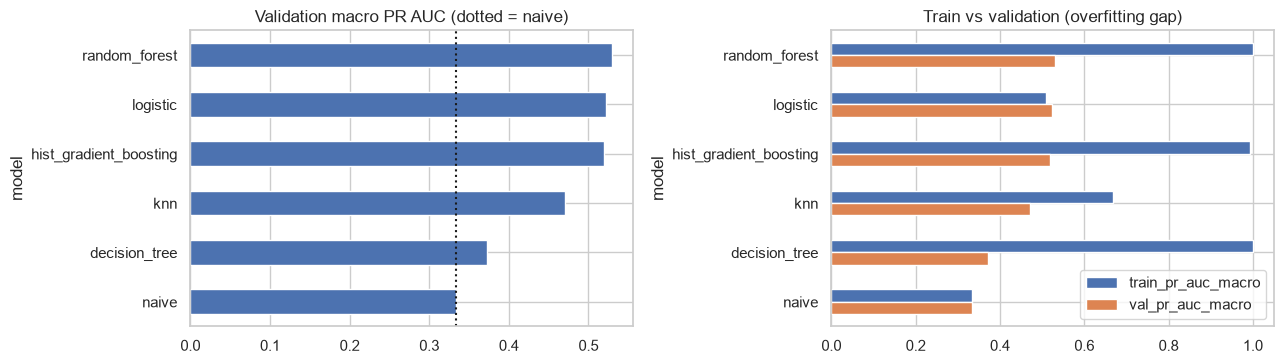

best default model by validation macro PR AUC: random_forest


In [34]:
rows, fitted = [], {}
for name in MODEL_REGISTRY:
    t0 = time.time(); m = make_model(name).fit(X_tr, y_tr); fitted[name] = m
    v, t = score_all(m, X_va, y_va), score_all(m, X_tr, y_tr)
    rows.append({"model": name, **{f"val_{k}": x for k, x in v.items()}, "train_pr_auc_macro": t["pr_auc_macro"], "gap_pr_auc (train-val)": t["pr_auc_macro"] - v["pr_auc_macro"], "fit_s": round(time.time() - t0, 1)})
base = pd.DataFrame(rows).set_index("model").sort_values("val_pr_auc_macro", ascending=False); base["rank"] = np.arange(1, len(base) + 1)
base["tie_with_next (<0.005)"] = (base["val_pr_auc_macro"] - base["val_pr_auc_macro"].shift(-1)).abs() < 0.005
display(base.round(4))
# noise: grouped 5-fold CV of every default model on the TRAIN sessions only
from sklearn.model_selection import GroupKFold
cvrows = {}
for name in MODEL_REGISTRY:
    sc_ = [pr_auc_macro(y_tr.iloc[b], make_model(name).fit(X_tr.iloc[a], y_tr.iloc[a]).predict_proba(X_tr.iloc[b]), SK_CLASSES) for a, b in GroupKFold(5).split(X_tr, y_tr, g_tr)]
    cvrows[name] = {"cv_pr_auc_mean": np.mean(sc_), "cv_pr_auc_sd": np.std(sc_)}
cv_tab = pd.DataFrame(cvrows).T.sort_values("cv_pr_auc_mean", ascending=False); display(cv_tab.round(4))
from pathlib import Path
Path("outputs").mkdir(exist_ok=True); base.drop(columns=["tie_with_next (<0.005)"]).to_csv("outputs/baseline_results.csv"); print("saved outputs/baseline_results.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); base["val_pr_auc_macro"].plot.barh(ax=ax[0], color="#4c72b0"); ax[0].axvline(1 / 3, color="k", ls=":"); ax[0].set_title("Validation macro PR AUC (dotted = naive)"); ax[0].invert_yaxis()
base[["train_pr_auc_macro", "val_pr_auc_macro"]].plot.barh(ax=ax[1]); ax[1].set_title("Train vs validation (overfitting gap)"); ax[1].invert_yaxis(); plt.tight_layout(); plt.show()
best_name = base.drop(index="naive").index[0]; print("best default model by validation macro PR AUC:", best_name)

**Observation / implication.** At library defaults the validation macro PR AUC ranks **random forest 0.529, logistic regression 0.523, gradient boosting 0.519, kNN 0.471, decision tree 0.372, naive 0.333**. The top three are within 0.010 of each other (logistic and boosting are flagged as a tie), so their order is not reliable: session-grouped 5-fold CV on the training sessions gives random forest 0.507 +/- 0.009, boosting 0.505 +/- 0.007, logistic 0.489 +/- 0.015, kNN 0.442 +/- 0.008, tree 0.373 +/- 0.010. The trees, forest and boosting reach a training PR AUC of about 1.0 vs about 0.52 on validation (gap 0.47-0.63): **defaults overfit heavily**, while logistic regression shows no gap (-0.013) and kNN a moderate one (0.20). Default failures, reported rather than fixed: the unpruned tree is nearly useless (ROC AUC 0.57); logistic and kNN rarely predict the minority classes (macro recall 0.43 and 0.47, macro-F1 0.41 and 0.47 even though logistic's ranking quality is good, PR AUC 0.52). Accuracy is misleading here: the naive model has 0.60, kNN 0.61 and the tree 0.54, so only the forest (0.67) clearly beats the majority baseline on accuracy. The absolute level is modest (PR AUC about 0.5 vs a floor of 0.333).

## 19. Diagnostics for the best baseline: confusion matrix, calibration, permutation importance
**Purpose.** For a classification target the analogue of residual plots is the confusion matrix and the one-vs-rest reliability (calibration) curve. Permutation importance is computed on the **raw input columns** through the whole pipeline.

              precision    recall  f1-score   support

         Low      0.782     0.766     0.774       883
    Moderate      0.517     0.703     0.596       441
        High      0.750     0.021     0.041       144

    accuracy                          0.674      1468
   macro avg      0.683     0.496     0.470      1468
weighted avg      0.699     0.674     0.648      1468

predicted class shares: {'Low': 0.589, 'Moderate': 0.409, 'High': 0.003} | actual: {'Low': 0.601, 'Moderate': 0.3, 'High': 0.098}


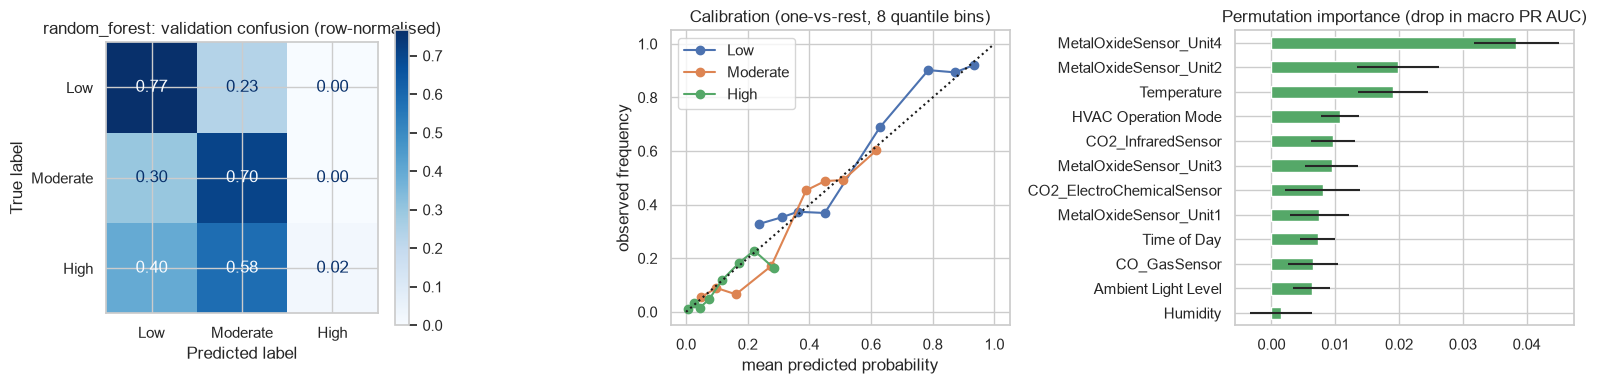

,importance,sd
MetalOxideSensor_Unit4,0.0384,0.0067
MetalOxideSensor_Unit2,0.0199,0.0064
Temperature,0.0190,0.0055
HVAC Operation Mode,0.0107,0.0030
CO2_InfraredSensor,0.0096,0.0035
MetalOxideSensor_Unit3,0.0094,0.0041
CO2_ElectroChemicalSensor,0.0080,0.0059
MetalOxideSensor_Unit1,0.0075,0.0046
Time of Day,0.0073,0.0027
CO_GasSensor,0.0065,0.0039


In [35]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
best = fitted[best_name]; proba = best.predict_proba(X_va); cl = list(best.classes_); pred = np.asarray(cl)[proba.argmax(1)]
print(classification_report(y_va, pred, labels=CLASSES, digits=3)); print("predicted class shares:", pd.Series(pred).value_counts(normalize=True).reindex(CLASSES).round(3).to_dict(), "| actual:", y_va.value_counts(normalize=True).reindex(CLASSES).round(3).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(16, 4)); ConfusionMatrixDisplay.from_predictions(y_va, pred, labels=CLASSES, normalize="true", cmap="Blues", values_format=".2f", ax=ax[0]); ax[0].set_title(f"{best_name}: validation confusion (row-normalised)")
for k, c in enumerate(CLASSES):
    fp, mp = calibration_curve((y_va == c).astype(int), proba[:, cl.index(c)], n_bins=8, strategy="quantile"); ax[1].plot(mp, fp, "o-", label=c)
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("mean predicted probability"); ax[1].set_ylabel("observed frequency"); ax[1].legend(); ax[1].set_title("Calibration (one-vs-rest, 8 quantile bins)")
scorer = make_scorer(lambda yt, p: pr_auc_macro(yt, p, SK_CLASSES), response_method="predict_proba")
pi = permutation_importance(best, X_va.drop(columns=[GROUP]), y_va, scoring=scorer, n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "sd": pi.importances_std}, index=X_va.drop(columns=[GROUP]).columns).sort_values("importance", ascending=False)
imp["importance"].plot.barh(ax=ax[2], xerr=imp["sd"], color="#55a868"); ax[2].invert_yaxis(); ax[2].set_title("Permutation importance (drop in macro PR AUC)"); plt.tight_layout(); plt.show(); display(imp.round(4))

**Observation / implication.** The best baseline (default random forest) behaves like a **two-class model**: on validation it predicts Low 58.9%, Moderate 40.9% and High 0.3% of rows, while High is really 9.8%. High precision is 0.75 but recall only 0.02 (confusion matrix: 58% of High rows are labelled Moderate and 40% Low), so its macro-F1 of 0.47 is held up by Low (F1 0.77) and Moderate (0.60) while High F1 is 0.04. Calibration is reasonable for Low and Moderate (curves close to the diagonal, with some over-confidence for Low at mid probabilities) but the model never gives High a probability above about 0.28, so High is detectable only by ranking (PR AUC), not at the default 0.5-style cut. Permutation importance (on raw columns, through the pipeline) agrees with the EDA: **MetalOxideSensor_Unit4 (0.038), MetalOxideSensor_Unit2 (0.020) and Temperature (0.019)** lead. HVAC mode, Time of Day and Ambient Light show small positive values (0.006-0.011) although the EDA found no or weak association; with an unpruned forest this is best read as noise fitting rather than signal. The error bars only reflect permutation randomness, not the uncertainty from the 5-session validation set.

## 20. Leakage-sensitivity: what would the suspect columns add?
**Purpose.** Refit the best baselines WITH the suspect columns (`Session ID` as a number, and the row index as a hidden clock), under (a) our session-grouped split and (b) a random stratified row split of the same sizes. This quantifies what the leaks would add; these columns stay out of the main workflow.

In [36]:
from sklearn.model_selection import train_test_split
def with_row_index(X_): return X_.assign(row_index=X_.index.astype(float))
def fit_eval(name, Xa, ya, Xb, yb, extra_cols=(), keep_group=False):
    m = make_model(name, drop_columns=() if keep_group else (GROUP,)); m.fit(Xa, ya); return score_all(m, Xb, yb)["pr_auc_macro"]
top = base.drop(index="naive").index[:3].tolist()
idx = np.arange(len(df)); a, rest = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=y_all); b, _ = train_test_split(rest, test_size=0.5, random_state=SEED, stratify=y_all.iloc[rest])
rows = []
for name in top:
    for split_name, (ia, ib) in {"session-grouped (ours)": (tr, va), "random rows (leaky)": (a, b)}.items():
        base_s = fit_eval(name, X_all.iloc[ia], y_all.iloc[ia], X_all.iloc[ib], y_all.iloc[ib])
        sess_s = fit_eval(name, X_all.iloc[ia], y_all.iloc[ia], X_all.iloc[ib], y_all.iloc[ib], keep_group=True)
        rows.append({"model": name, "split": split_name, "without suspects": base_s, "with Session ID (as number)": sess_s, "delta Session ID": sess_s - base_s})
res = pd.DataFrame(rows).set_index(["model", "split"]); display(res.round(4))
# Session ID only as one-hot (memorising session mix), and the row index as a feature (HGB, both splits)
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
rows2 = []
for split_name, (ia, ib) in {"session-grouped (ours)": (tr, va), "random rows (leaky)": (a, b)}.items():
    for label, cols in [("Session ID only", [GROUP]), ("row index only", ["row_index"]), ("sensors only", NUMERIC_BASE[:8])]:
        Xf = with_row_index(X_all)[cols]; m = HGB(random_state=SEED).fit(Xf.iloc[ia], y_all.iloc[ia]); rows2.append({"split": split_name, "features": label, "val macro PR AUC": pr_auc_macro(y_all.iloc[ib], m.predict_proba(Xf.iloc[ib]), list(m.classes_))})
display(pd.DataFrame(rows2).pivot(index="features", columns="split", values="val macro PR AUC").round(4)); print("reference: naive prior = 0.333")

without suspects  with Session ID (as number)  delta Session ID
model                  split                                                                                  
random_forest          session-grouped (ours)            0.5294                       0.5194           -0.0100
                       random rows (leaky)               0.5731                       0.5759            0.0028
logistic               session-grouped (ours)            0.5225                       0.5226            0.0001
                       random rows (leaky)               0.4847                       0.4839           -0.0007
hist_gradient_boosting session-grouped (ours)            0.5190                       0.5272            0.0082
                       random rows (leaky)               0.5463                       0.5528            0.0065

split,random rows (leaky),session-grouped (ours)
features,,
Session ID only,0.4291,0.3115
row index only,0.3974,0.3345
sensors only,0.5356,0.5195


reference: naive prior = 0.333


**Observation / implication.** The suspect columns add **nothing reliable** to the sensors: with Session ID as a number the validation macro PR AUC changes by -0.010 to +0.008 under our session split and by -0.001 to +0.007 under a random split (all within noise). On their own they do carry information that only a random split can exploit: Session ID alone scores 0.429 under random rows but 0.312 under session grouping (naive = 0.333), the row index alone 0.397 vs 0.335, and sensors alone 0.536 vs 0.520. The random-vs-grouped gap for the full pipeline is +0.044 for the forest (0.573 vs 0.529) and +0.027 for boosting but reversed for logistic regression (0.485 vs 0.523), so the inflation from leakage is model-dependent and partly confounded with the different 5-session validation set (noise of about +/-0.02). Verdict: keep Session ID and the row index out of the features and keep the session split; leaving them out costs nothing.

## 21. Baseline summary table
**Purpose.** Collect the final baseline comparison in one table for the closing summary and for Phase 1C (tuning).

In [37]:
summary = base[["val_pr_auc_macro", "val_f1_macro", "val_roc_auc_macro", "val_accuracy", "gap_pr_auc (train-val)"]].join(cv_tab).round(4); display(summary)
print("best:", best_name, "| naive floor (PR AUC):", round(base.loc["naive", "val_pr_auc_macro"], 4))

,val_pr_auc_macro,val_f1_macro,val_roc_auc_macro,val_accuracy,gap_pr_auc (train-val),cv_pr_auc_mean,cv_pr_auc_sd
model,,,,,,,
random_forest,0.5294,0.4700,0.7665,0.6737,0.4706,0.5067,0.0092
logistic,0.5225,0.4092,0.7475,0.6465,-0.0132,0.4887,0.0150
hist_gradient_boosting,0.5190,0.4682,0.7656,0.6553,0.4736,0.5054,0.0073
knn,0.4710,0.4654,0.7048,0.6076,0.1978,0.4422,0.0082
decision_tree,0.3722,0.4067,0.5698,0.5381,0.6278,0.3730,0.0101
naive,0.3333,0.2504,0.5000,0.6015,0.0000,0.3333,0.0000


best: random_forest | naive floor (PR AUC): 0.3333


**Observation / implication.** The table is the Phase 1C starting point. Ranking by validation PR AUC, by session-grouped CV and by macro-F1 broadly agree that random forest, boosting and logistic regression are the three strongest and that the unpruned tree is weakest; the exact order among the top three is not supported by the data.

## 22. Summary of baselines
**State of the pipeline.** Cleaning, feature engineering, preprocessing and the split are implemented as clone-safe classes and one Pipeline, fitted on training rows only; the leakage proof, messy-input probe and NaN checks pass; the test set is locked (only its length has been used).

**Baselines (library defaults, validation, macro PR AUC; naive = 0.333):** random forest 0.529, logistic regression 0.523, gradient boosting 0.519, kNN 0.471, decision tree 0.372. Macro-F1 ranges from 0.41 to 0.47 for the real models against 0.25 for the naive model.

**How much to trust this.** One split, one seed, and a validation set of only 5 sessions: the top three models are within 0.010 and cannot be ranked with confidence (grouped CV on the training sessions gives 0.507, 0.505 and 0.489, standard deviations 0.007-0.015). Validation and test class mixes differ (High 9.8% vs 12.3%), so the test score will differ from the validation score even without overfitting. The absolute level is modest: sensors give about +0.2 PR AUC over chance, not reliable detection. The High class is effectively never predicted at default thresholds (recall 0.02 for the best baseline).

**Findings carried forward.** Defaults overfit strongly (tree-based train PR AUC about 1.0 vs 0.52); logistic regression does not overfit but rarely predicts minority classes; MetalOxideSensor_Unit4, Unit2 and Temperature are the leading features; Session ID and row order add nothing once sensors are present but would inflate a random split; HVAC mode, Time of Day and Ambient Light look like noise features.

**Not done in this phase (by design):** tuning, class weighting, the one-time test evaluation, the engineered-feature ablation, and any threshold selection.

## 23. Next phase (Phase 1C): tuning plan, **not executed**
*This plan is documentation only; nothing below has been executed.*

**Setup.** Grouped 3-fold CV (`GroupKFold` on session ID) on the training split only; scoring = macro PR AUC; tuned settings and class weighting are applied **only** on a cloned model inside the tuning code path (baselines stay at library defaults, with a guard cell asserting this and matching the saved `outputs/baseline_results.csv`). Compute: all CPU cores (`n_jobs=-1`).

| Model | Search | Space (starting point) | Fixed in tuning path |
|---|---|---|---|
| Logistic regression | `GridSearchCV` | `C` in [1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 0.1, 1] | `class_weight='balanced'` |
| Decision tree | `HalvingRandomSearchCV` | `max_depth` [3,4,5,6,8,10,14], `min_samples_leaf` [5,10,20,40,80], `criterion` [gini, entropy] | `class_weight='balanced'` |
| Random forest | `HalvingRandomSearchCV` | `max_depth` [4,6,8,12,None], `min_samples_leaf` [2,5,10,20], `max_features` [0.3,0.5,sqrt] | `n_estimators=200`, `max_samples=0.7`, `class_weight='balanced_subsample'` |
| Hist gradient boosting | `HalvingRandomSearchCV` | `learning_rate` [0.02,0.05,0.1], `max_depth` [3,4,6], `max_leaf_nodes` [8,15,31], `l2_regularization` [0,1,10], `min_samples_leaf` [20,50,100] (add `max_iter` this time) | `class_weight='balanced'` |
| kNN | `HalvingRandomSearchCV` | `n_neighbors` [5,10,15,25,40,60], `weights` [uniform, distance], `p` [1,2] | none |

**Search design.** Successive halving (factor 3, resource = `n_samples`) with 18-27 candidates on a training subsample of about 4,000 rows, then refit the winner on the **full** training split; per-model checkpoint ledger keyed `stage::model` with a settings fingerprint, so an interrupted run resumes but a fresh run recomputes everything; one cell per slow model.

**Selection and test.** Select by highest validation macro PR AUC (rule fixed now); refit on train+validation; evaluate the test set **once**, with bootstrap 95% CIs, the paired improvement over the default-parameter twin and the naive model, and per-class results (especially High).

**Planned sensitivity checks (validation only).** Engineered features on/off; HVAC mode, Time of Day and Ambient Light dropped; missing-indicator flags on/off; decision threshold / class-prior adjustment for the High class (reported separately, chosen on validation).

**Expectations.** Gains from tuning are expected to be small for the already-regularised models (differences below about 0.01 PR AUC are within noise), larger for the tree and kNN; the main caveat is the 5-session validation set.

---
# Part C: Hyper-parameter tuning, model selection and the one-time test evaluation (Phase 1C)

**Rules fixed in advance (before any tuned result is seen).**
1. **Selection rule:** among the *tuned* models, choose the one with the highest **validation macro PR AUC**; no other criterion, no test information.
2. **Test set:** evaluated **once** (section 34), with the result stored in the ledger so a re-run cannot re-evaluate it. Nothing earlier in Part C touches the test rows.
3. **Baselines stay at library defaults:** tuned settings and class weighting are applied only on cloned models in the tuning code path; a guard cell asserts this before and after tuning.
4. **Compute:** all CPU cores, successive-halving searches on a training *subsample* (rungs 450 -> 1,350 -> 4,050 rows), grouped 3-fold CV by session, then the winner is **refit on the full training split**. Checkpoints only protect against an interrupted run of this same notebook; a fresh run recomputes everything.
5. **Noise:** differences below the CV fold standard deviation (about 0.01 PR AUC) are not treated as improvements.

## 24. Configuration, checkpoint ledger and artifact folder
**Purpose.** Set the tuning budget, create the output folders and define a checkpoint ledger keyed `stage::model` whose entries carry a settings fingerprint (search space, data size, seed, folds, pipeline version) and are reused only if it matches.

In [38]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.calibration import calibration_curve
import os, json, hashlib, pickle, platform, sklearn, scipy, joblib
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import GridSearchCV, HalvingRandomSearchCV, GroupKFold
from sklearn.metrics import make_scorer
from pathlib import Path
SMOKE = os.environ.get("P1C_SMOKE") == "1"                      # reduced mode for smoke tests only
OUT = Path("outputs_smoke" if SMOKE else "outputs")
for sub in ["checkpoints", "cv_results", "figures"]: (OUT / sub).mkdir(parents=True, exist_ok=True)
RUN_T0 = time.time()
CFG = dict(mode="smoke" if SMOKE else "full", seed=SEED, folds=3, factor=3, min_resources=200 if SMOKE else 450, max_resources=600 if SMOKE else 4050,
           n_candidates=6 if SMOKE else 27, bootstrap_n=50 if SMOKE else 1000, n_jobs=-1, n_train=len(X_tr), n_val=len(X_va), n_test=len(X_te),
           pipeline_version="p1b-v1: clean -> engineer(temp_x_humidity, co2_z_gap) -> winsor/median/scale + one-hot + missing flags; Session ID dropped")
class Ledger:
    """JSON ledger + pickled fitted state; keys are f'{stage}::{model}'. An entry is reused only if its fingerprint matches."""
    def __init__(self, out):
        self.dir, self.path = out, out / "nb_ledger.json"; self.data = json.loads(self.path.read_text()) if self.path.exists() else {}
    @staticmethod
    def fingerprint(obj): return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:16]
    def _ckpt(self, key): return self.dir / "checkpoints" / (key.replace("::", "__") + ".pkl")
    def get(self, key, fp):
        e = self.data.get(key)
        if e and e["fingerprint"] == fp and self._ckpt(key).exists():
            with open(self._ckpt(key), "rb") as fh: return e, pickle.load(fh)
        return None
    def put(self, key, fp, report, payload, **meta):
        with open(self._ckpt(key), "wb") as fh: pickle.dump(payload, fh)
        self.data[key] = {"fingerprint": fp, "report": report, "saved": time.strftime("%Y-%m-%d %H:%M:%S"), **meta}
        self.path.write_text(json.dumps(self.data, indent=1, default=float))
ledger = Ledger(OUT)
print("mode:", CFG["mode"], "| output folder:", OUT, "| ledger entries at start:", list(ledger.data) or "none (fresh run)")
print({k: v for k, v in CFG.items() if k != "pipeline_version"}); print("CPU cores:", os.cpu_count())

mode: full | output folder: outputs | ledger entries at start: none (fresh run)
{'mode': 'full', 'seed': 42, 'folds': 3, 'factor': 3, 'min_resources': 450, 'max_resources': 4050, 'n_candidates': 27, 'bootstrap_n': 1000, 'n_jobs': -1, 'n_train': 6903, 'n_val': 1468, 'n_test': 1469}
CPU cores: 8


**Observation / implication.** This is a **fresh run**: the ledger started empty ("none (fresh run)"), mode `full`, 8 CPU cores, grouped 3-fold CV by session, successive-halving rungs of 450 -> 1,350 -> 4,050 training rows (factor 3) with 27 candidates (kNN has only 24 combinations). Only the checkpoint mechanism and the folder layout were set up here; nothing was fitted.

## 25. Baseline integrity guard (before tuning)
**Purpose.** Assert that the baseline models are still library defaults and that re-scoring them reproduces the saved baseline table, so that nothing in the tuning code can have contaminated them.

In [39]:
def assert_baselines_intact(tag):
    saved = pd.read_csv("outputs/baseline_results.csv", index_col=0)
    for name, factory in MODEL_REGISTRY.items():
        assert fitted[name].named_steps["clf"].get_params() == factory().get_params(), f"{name}: parameters differ from library defaults"
        got = score_all(fitted[name], X_va, y_va)["pr_auc_macro"]
        assert np.isclose(got, saved.loc[name, "val_pr_auc_macro"], atol=1e-9), f"{name}: re-scored {got} != saved {saved.loc[name, 'val_pr_auc_macro']}"
    print(f"[{tag}] baseline guard passed: all {len(MODEL_REGISTRY)} baselines are library defaults and reproduce outputs/baseline_results.csv")
assert_baselines_intact("before tuning")

[before tuning] baseline guard passed: all 6 baselines are library defaults and reproduce outputs/baseline_results.csv


**Observation / implication.** Guard passed before tuning: every baseline model's parameters equal a freshly built library-default estimator, and re-scoring the fitted baselines reproduces the saved `outputs/baseline_results.csv` to 1e-9. Tuned settings (class weights, forest size) exist only in the tuning code path.

## 26. Search spaces, tuned-path settings and compute budget
**Purpose.** Define the grids, the settings that apply only in the tuning path (class weighting etc.), and estimate run time from the measured baseline fit times before launching anything.

In [40]:
SPACES = {
 "logistic": {"clf__C": [1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 0.1, 1]},
 "decision_tree": {"clf__max_depth": [3, 4, 5, 6, 8, 10, 14], "clf__min_samples_leaf": [5, 10, 20, 40, 80], "clf__criterion": ["gini", "entropy"]},
 "random_forest": {"clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [2, 5, 10, 20], "clf__max_features": [0.3, 0.5, "sqrt"]},
 "hist_gradient_boosting": {"clf__learning_rate": [0.02, 0.05, 0.1], "clf__max_iter": [100, 200, 400], "clf__max_depth": [3, 4, 6], "clf__max_leaf_nodes": [8, 15, 31], "clf__l2_regularization": [0, 1, 10], "clf__min_samples_leaf": [20, 50, 100]},
 "knn": {"clf__n_neighbors": [5, 10, 15, 25, 40, 60], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}}
TUNED_FIXED = {"logistic": {"class_weight": "balanced"}, "decision_tree": {"class_weight": "balanced"},
               "random_forest": {"class_weight": "balanced_subsample", "n_estimators": 200, "max_samples": 0.7, "n_jobs": 1},
               "hist_gradient_boosting": {"class_weight": "balanced"}, "knn": {}}
SEARCH_KIND = {"logistic": "grid", "decision_tree": "halving", "random_forest": "halving", "hist_gradient_boosting": "halving", "knn": "halving"}
assert set(SPACES) == REQUIRED - {"naive"}
def grid_size(sp): return int(np.prod([len(v) for v in sp.values()]))
rows = []
for name, sp in SPACES.items():
    gs = grid_size(sp); fit1 = float(base.loc[name, "fit_s"])
    if SEARCH_KIND[name] == "grid": fits, est = gs * CFG["folds"], gs * CFG["folds"] * fit1 * (CFG["n_train"] * 2 / 3 / CFG["n_train"])
    else:
        n, res, fits, est = min(CFG["n_candidates"], gs), CFG["min_resources"], 0, 0.0
        while n >= 1 and res <= CFG["max_resources"]:
            fits += n * CFG["folds"]; est += n * CFG["folds"] * fit1 * res / CFG["n_train"]; n, res = int(np.ceil(n / CFG["factor"])), res * CFG["factor"]
            if n == 1 and res > CFG["max_resources"]: break
    rows.append({"model": name, "search": SEARCH_KIND[name], "grid_size": gs, "approx_fits": fits, "baseline_fit_s (full train, 1 core-equivalent)": fit1, "est_search_s (serial)": round(est, 1)})
display(pd.DataFrame(rows).set_index("model")); print("rule of thumb: total fits ~ candidates x folds x 1.5; with all cores the wall-clock should be a fraction of the serial estimate")

,search,grid_size,approx_fits,"baseline_fit_s (full train, 1 core-equivalent)",est_search_s (serial)
model,,,,,
logistic,grid,8,24,0.5,8.0
decision_tree,halving,70,117,0.5,7.9
random_forest,halving,60,117,1.3,20.6
hist_gradient_boosting,halving,729,117,5.2,82.4
knn,halving,24,105,0.6,8.8


rule of thumb: total fits ~ candidates x folds x 1.5; with all cores the wall-clock should be a fraction of the serial estimate


**Observation / implication.** The serial time estimates (8-82 s per model, about 127 s in total) came from the measured baseline fit times and were small enough to run the full budget; with all cores the real wall-clock was 5-63 s per model. The gradient-boosting grid has 729 combinations of which 27 are sampled; `max_iter` was added to the space this time because the default (100 iterations) interacts with the learning rate. Class weighting and a 200-tree forest are tuned-path settings only.

## 27. Tuning helper and logistic regression (grid search)
**Purpose.** One helper runs a model's search inside the notebook, refits the winner on the full training split, stores the cross-validation table, the winner's fold scores and a text report, and checkpoints everything. Logistic regression is cheap, so it uses `GridSearchCV`.

In [41]:
scorer = make_scorer(lambda yt, p: pr_auc_macro(yt, p, SK_CLASSES), response_method="predict_proba")
TUNED, TIMINGS = {}, {}
def tuned_base(name):
    m = make_model(name); m.set_params(**{f"clf__{k}": v for k, v in TUNED_FIXED[name].items()}); return m   # tuned settings applied on a fresh clone only
def run_tuning(name):
    key = f"tuned::{name}"; fp = Ledger.fingerprint({"space": {k: [str(x) for x in v] for k, v in SPACES[name].items()}, "fixed": TUNED_FIXED[name], "search": SEARCH_KIND[name], "n_train": CFG["n_train"], "seed": SEED,
        "folds": CFG["folds"], "factor": CFG["factor"], "min_res": CFG["min_resources"], "max_res": CFG["max_resources"], "cand": CFG["n_candidates"], "pipeline": CFG["pipeline_version"]})
    hit = ledger.get(key, fp)
    if hit: (e, payload) = hit; print(f"[checkpoint reused] {key}\n{e['report']}"); TUNED[name] = payload; return payload
    base_ = tuned_base(name); cv = GroupKFold(n_splits=CFG["folds"]); common = dict(scoring=scorer, cv=cv, n_jobs=CFG["n_jobs"], refit=False)
    if SEARCH_KIND[name] == "grid": search = GridSearchCV(base_, SPACES[name], **common)
    else: search = HalvingRandomSearchCV(base_, SPACES[name], n_candidates=min(CFG["n_candidates"], grid_size(SPACES[name])), factor=CFG["factor"], resource="n_samples", min_resources=CFG["min_resources"],
                                         max_resources=min(CFG["max_resources"], len(X_tr)), random_state=SEED, aggressive_elimination=False, **common)
    t0 = time.time(); search.fit(X_tr, y_tr, groups=g_tr); t_search = time.time() - t0
    best_params = {k: (v.item() if isinstance(v, np.generic) else v) for k, v in search.best_params_.items()}
    t1 = time.time(); model = clone(base_).set_params(**best_params).fit(X_tr, y_tr); t_refit = time.time() - t1       # refit on the FULL training split
    cvres = pd.DataFrame(search.cv_results_); cvres.drop(columns=[c for c in cvres.columns if c.startswith("param_")], errors="ignore").assign(params=cvres["params"].astype(str)).to_csv(OUT / "cv_results" / f"{name}.csv", index=False)
    row = cvres.loc[search.best_index_]; folds = [float(row[f"split{i}_test_score"]) for i in range(CFG["folds"])]
    val = score_all(model, X_va, y_va); n_cand = len(cvres)
    report = (f"{name}: best params {best_params}\n  CV macro PR AUC of best config {np.mean(folds):.4f} (fold sd {np.std(folds):.4f}; folds {np.round(folds, 4).tolist()}; "
              f"measured on {int(row['n_resources']) if 'n_resources' in cvres else 'all'} training rows per CV fit at the final rung)\n  validation (full-train refit): PR AUC {val['pr_auc_macro']:.4f}, macro-F1 {val['f1_macro']:.4f}, ROC AUC {val['roc_auc_macro']:.4f}\n  "
              f"candidates evaluated across rungs: {n_cand}; search {t_search:.0f}s, refit {t_refit:.0f}s")
    payload = {"model": model, "best_params": best_params, "cv_folds": folds, "val": val, "search_s": t_search, "refit_s": t_refit}
    ledger.put(key, fp, report, payload, best_params=best_params, cv_mean=float(np.mean(folds)), val_pr_auc=val["pr_auc_macro"]); print(report); TUNED[name] = payload; return payload
TIMINGS["logistic"] = time.time(); _ = run_tuning("logistic"); TIMINGS["logistic"] = time.time() - TIMINGS["logistic"]

logistic: best params {'clf__C': 0.0003}
  CV macro PR AUC of best config 0.5057 (fold sd 0.0078; folds [0.5158, 0.5044, 0.497]; measured on all training rows per CV fit at the final rung)
  validation (full-train refit): PR AUC 0.5261, macro-F1 0.4994, ROC AUC 0.7601
  candidates evaluated across rungs: 8; search 1s, refit 0s


**Observation / implication.** Logistic regression: best `C` = 0.0003 (very strong regularisation, an interior value of the grid). Grouped-CV macro PR AUC of the best configuration is 0.506 (fold sd 0.008); the validation PR AUC after refit on the full training split is 0.526 vs 0.5225 for the default, a change of +0.004, i.e. **within noise**. Its macro-F1 rises from 0.41 to 0.50, but that is the effect of `class_weight='balanced'` on the decision rule (it now predicts the minority classes), not better ranking.

## 28. Decision tree (successive halving)
**Purpose.** Search `decision_tree` on a training subsample with successive halving (factor 3, resource = rows), then refit the winner on the full training split. Checkpointed on completion.

In [42]:
TIMINGS["decision_tree"] = time.time(); _ = run_tuning("decision_tree"); TIMINGS["decision_tree"] = time.time() - TIMINGS["decision_tree"]; print("wall-clock for this cell: %.0fs" % TIMINGS["decision_tree"])

decision_tree: best params {'clf__min_samples_leaf': 40, 'clf__max_depth': 10, 'clf__criterion': 'gini'}
  CV macro PR AUC of best config 0.4824 (fold sd 0.0082; folds [0.4743, 0.4937, 0.4793]; measured on 4050 training rows per CV fit at the final rung)
  validation (full-train refit): PR AUC 0.4973, macro-F1 0.4777, ROC AUC 0.7429
  candidates evaluated across rungs: 39; search 5s, refit 0s
wall-clock for this cell: 5s


**Observation / implication.** Pruning matters: best depth 10, `min_samples_leaf` 40, Gini; CV 0.482 (sd 0.008, measured on 4,050-row subsamples). Validation PR AUC rises from **0.372 to 0.497 (+0.125)**, by far the largest tuning gain, because the default tree memorises the training data. It remains the weakest model in absolute terms.

## 29. Random forest (successive halving)
**Purpose.** Search `random_forest` on a training subsample with successive halving (factor 3, resource = rows), then refit the winner on the full training split. Checkpointed on completion.

In [43]:
TIMINGS["random_forest"] = time.time(); _ = run_tuning("random_forest"); TIMINGS["random_forest"] = time.time() - TIMINGS["random_forest"]; print("wall-clock for this cell: %.0fs" % TIMINGS["random_forest"])

random_forest: best params {'clf__min_samples_leaf': 10, 'clf__max_features': 'sqrt', 'clf__max_depth': 8}
  CV macro PR AUC of best config 0.5180 (fold sd 0.0094; folds [0.5268, 0.5221, 0.505]; measured on 4050 training rows per CV fit at the final rung)
  validation (full-train refit): PR AUC 0.5257, macro-F1 0.5022, ROC AUC 0.7707
  candidates evaluated across rungs: 39; search 37s, refit 2s
wall-clock for this cell: 39s


**Observation / implication.** Random forest: best depth 8, `min_samples_leaf` 10, `max_features` sqrt; CV 0.518 (sd 0.009). Validation PR AUC is **0.5257 vs 0.5294 for the default (-0.004, within noise)**, so tuning did not help the forest's ranking quality; its macro-F1 improves (0.470 -> 0.502) through class weighting only.

## 30. Histogram gradient boosting (successive halving)
**Purpose.** Search `hist_gradient_boosting` on a training subsample with successive halving (factor 3, resource = rows), then refit the winner on the full training split. Checkpointed on completion.

In [44]:
TIMINGS["hist_gradient_boosting"] = time.time(); _ = run_tuning("hist_gradient_boosting"); TIMINGS["hist_gradient_boosting"] = time.time() - TIMINGS["hist_gradient_boosting"]; print("wall-clock for this cell: %.0fs" % TIMINGS["hist_gradient_boosting"])

hist_gradient_boosting: best params {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 8, 'clf__max_iter': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0}
  CV macro PR AUC of best config 0.5123 (fold sd 0.0107; folds [0.5259, 0.5112, 0.4998]; measured on 4050 training rows per CV fit at the final rung)
  validation (full-train refit): PR AUC 0.5393, macro-F1 0.5070, ROC AUC 0.7734
  candidates evaluated across rungs: 39; search 61s, refit 2s
wall-clock for this cell: 63s


**Observation / implication.** Gradient boosting: best configuration is a small, shallow model (learning rate 0.05, depth 3, 8 leaves, 100 iterations, `min_samples_leaf` 20, no L2): CV 0.512 (sd 0.011). Validation PR AUC rises from 0.519 to **0.539 (+0.020)**. Caveat: depth, leaf count and `max_iter` are all at the lower edge of their grids, which suggests that even simpler models might do as well and that the grid should be extended downwards in any follow-up.

## 31. kNN (successive halving)
**Purpose.** Search `knn` on a training subsample with successive halving (factor 3, resource = rows), then refit the winner on the full training split. Checkpointed on completion.

In [45]:
TIMINGS["knn"] = time.time(); _ = run_tuning("knn"); TIMINGS["knn"] = time.time() - TIMINGS["knn"]; print("wall-clock for this cell: %.0fs" % TIMINGS["knn"])

knn: best params {'clf__weights': 'distance', 'clf__p': 1, 'clf__n_neighbors': 60}
  CV macro PR AUC of best config 0.5047 (fold sd 0.0057; folds [0.5128, 0.5001, 0.5012]; measured on 4050 training rows per CV fit at the final rung)
  validation (full-train refit): PR AUC 0.5284, macro-F1 0.4646, ROC AUC 0.7661
  candidates evaluated across rungs: 35; search 7s, refit 0s
wall-clock for this cell: 7s


**Observation / implication.** kNN: best is `k` = 60 with distance weights and Manhattan distance; CV 0.505 (sd 0.006). Validation PR AUC rises from 0.471 to **0.528 (+0.058)**: smoother neighbourhoods fix the high-variance default. `k` = 60 is the upper edge of the grid, so larger values might help further.

## 32. Tuned vs baseline (validation) and the guard again
**Purpose.** Compare every tuned model with its default-parameter baseline on validation macro PR AUC and judge the change against the noise (CV fold standard deviation). Re-run the baseline guard.

[after tuning] baseline guard passed: all 6 baselines are library defaults and reproduce outputs/baseline_results.csv


,baseline_val_pr_auc,tuned_val_pr_auc,delta,baseline_cv_sd,tuned_cv_fold_sd,delta / max(sd),baseline_f1,tuned_f1,tuned_cv_pr_auc,tuned_val_roc_auc,verdict
model,,,,,,,,,,,
hist_gradient_boosting,0.5190,0.5393,0.0203,0.0073,0.0107,1.9007,0.4682,0.5070,0.5123,0.7734,improved
knn,0.4710,0.5284,0.0575,0.0082,0.0057,7.0120,0.4654,0.4646,0.5047,0.7661,improved
logistic,0.5225,0.5261,0.0036,0.0150,0.0078,0.2414,0.4092,0.4994,0.5057,0.7601,within noise
random_forest,0.5294,0.5257,-0.0037,0.0092,0.0094,-0.3909,0.4700,0.5022,0.5180,0.7707,within noise
decision_tree,0.3722,0.4973,0.1252,0.0101,0.0082,12.3634,0.4067,0.4777,0.4824,0.7429,improved


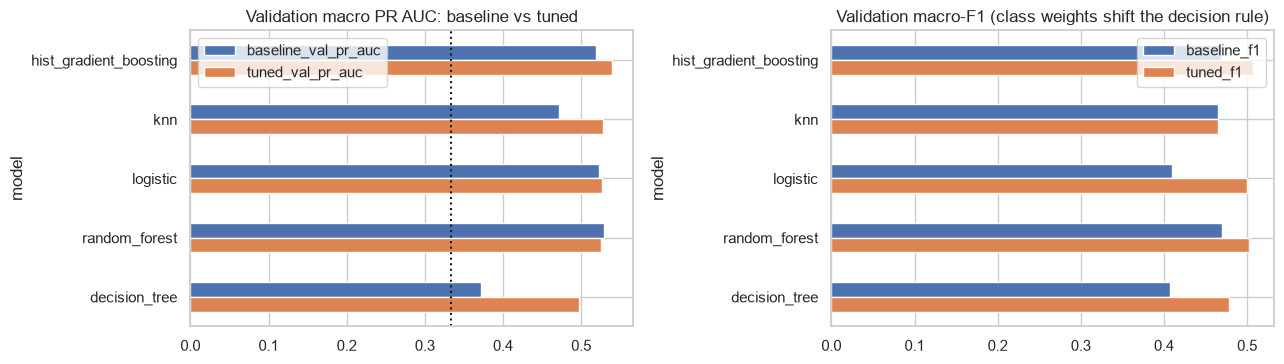

In [46]:
assert_baselines_intact("after tuning")
rows = []
for name, p in TUNED.items():
    b = base.loc[name]; sd_t = float(np.std(p["cv_folds"])); sd_b = float(cv_tab.loc[name, "cv_pr_auc_sd"]); delta = p["val"]["pr_auc_macro"] - b["val_pr_auc_macro"]
    rows.append({"model": name, "baseline_val_pr_auc": b["val_pr_auc_macro"], "tuned_val_pr_auc": p["val"]["pr_auc_macro"], "delta": delta, "baseline_cv_sd": sd_b, "tuned_cv_fold_sd": sd_t,
                 "delta / max(sd)": delta / max(sd_b, sd_t, 1e-9), "baseline_f1": b["val_f1_macro"], "tuned_f1": p["val"]["f1_macro"], "tuned_cv_pr_auc": float(np.mean(p["cv_folds"])), "tuned_val_roc_auc": p["val"]["roc_auc_macro"]})
TT = pd.DataFrame(rows).set_index("model").sort_values("tuned_val_pr_auc", ascending=False); TT["verdict"] = np.where(TT["delta"].abs() < TT[["baseline_cv_sd", "tuned_cv_fold_sd"]].max(axis=1), "within noise", np.where(TT["delta"] > 0, "improved", "worse"))
display(TT.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); TT[["baseline_val_pr_auc", "tuned_val_pr_auc"]].plot.barh(ax=ax[0]); ax[0].axvline(1 / 3, color="k", ls=":"); ax[0].invert_yaxis(); ax[0].set_title("Validation macro PR AUC: baseline vs tuned")
TT[["baseline_f1", "tuned_f1"]].plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set_title("Validation macro-F1 (class weights shift the decision rule)"); plt.tight_layout(); plt.savefig(OUT / "figures" / "tuned_vs_baseline.png", dpi=120); plt.show()

**Observation / implication.** Judged against the CV noise (fold standard deviation, about 0.006-0.015): **improved** are gradient boosting (+0.020, 1.9x the noise), kNN (+0.058, 7x) and the decision tree (+0.125, 12x); **within noise** are logistic regression (+0.004) and random forest (-0.004). After tuning, the top four models are within 0.014 of each other (boosting 0.539, kNN 0.528, logistic 0.526, forest 0.526), so their order is not statistically supported. Macro-F1 gains of 0.03-0.10 for the class-weighted models are mostly a decision-rule effect. The guard re-run after tuning passes, so the baselines were not contaminated.

## 33. Which features matter in the tuned models? (permutation importance, validation)
**Purpose.** Permutation importance on the raw input columns through each tuned pipeline, measured as the drop in validation macro PR AUC (10 repeats). This answers the task's feature-importance requirement.

,logistic,decision_tree,random_forest,hist_gradient_boosting,knn,mean_rank_score
MetalOxideSensor_Unit4,0.0111,0.0256,0.0024,0.0348,0.0074,0.0163
Temperature,0.0122,0.0058,0.0008,0.0154,0.0105,0.0089
MetalOxideSensor_Unit2,0.0008,0.0122,-0.0014,0.0143,0.0070,0.0066
CO2_ElectroChemicalSensor,0.0125,0.0044,-0.0059,0.0025,0.0013,0.0030
CO_GasSensor,0.0028,0.0000,-0.0008,-0.0012,0.0062,0.0014
Humidity,0.0023,0.0002,-0.0003,0.0071,-0.0026,0.0013
HVAC Operation Mode,0.0000,0.0000,-0.0001,0.0020,0.0021,0.0008
CO2_InfraredSensor,0.0043,0.0018,-0.0055,0.0020,0.0009,0.0007
Time of Day,-0.0008,-0.0004,-0.0001,0.0000,0.0030,0.0003
Ambient Light Level,-0.0016,0.0001,-0.0005,0.0007,0.0028,0.0003


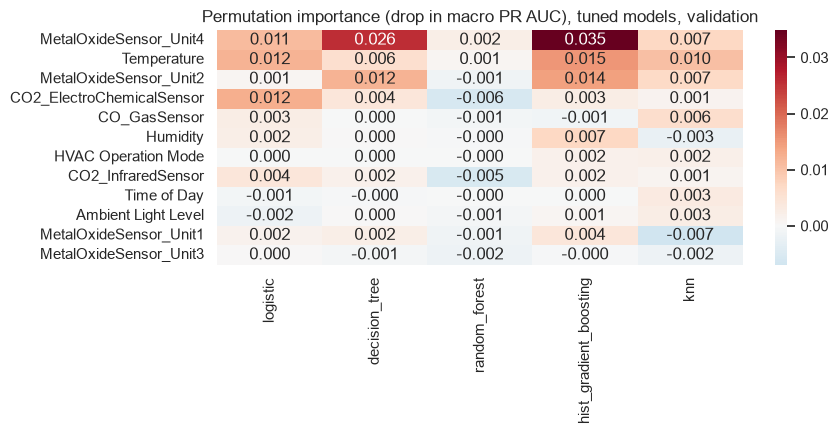

In [47]:
Xv = X_va.drop(columns=[GROUP]); imps = {}
for name, p in TUNED.items():
    r = permutation_importance(p["model"], Xv, y_va, scoring=scorer, n_repeats=3 if SMOKE else 10, random_state=SEED, n_jobs=-1); imps[name] = pd.Series(r.importances_mean, index=Xv.columns)
IMP = pd.DataFrame(imps); IMP["mean_rank_score"] = IMP.mean(axis=1); IMP = IMP.sort_values("mean_rank_score", ascending=False); display(IMP.round(4)); IMP.to_csv(OUT / "feature_importance_tuned.csv")
fig, ax = plt.subplots(figsize=(9, 4.5)); sns.heatmap(IMP.drop(columns="mean_rank_score"), annot=True, fmt=".3f", cmap="RdBu_r", center=0, ax=ax); ax.set_title("Permutation importance (drop in macro PR AUC), tuned models, validation"); plt.tight_layout(); plt.savefig(OUT / "figures" / "importance_tuned.png", dpi=120); plt.show()

**Observation / implication.** Across the tuned models **MetalOxideSensor_Unit4 is the most important feature** (mean drop in PR AUC 0.016; 0.035 for boosting), followed by Temperature (0.009), MetalOxideSensor_Unit2 (0.007) and CO2 electrochemical (0.003, driven by logistic regression). CO_GasSensor, Humidity, HVAC mode, CO2 infrared, Time of Day, Ambient Light and MOS Unit1/Unit3 add essentially nothing (|importance| < 0.002 on average). This matches the EDA ranking, with the addition that MOS Units 1 and 3 are redundant given Units 4 and 2. The absolute values are small and measured on 5 validation sessions with correlated sensors, so mid-table ranks are not reliable.

## 34a. Model selection (pre-declared rule)
**Purpose.** Apply the rule written at the top of Part C: highest validation macro PR AUC among the tuned models.

In [48]:
best_name = TT["tuned_val_pr_auc"].idxmax(); best_params = TUNED[best_name]["best_params"]
print("selected model:", best_name, "| validation macro PR AUC", round(TT.loc[best_name, "tuned_val_pr_auc"], 4), "| params", best_params)
runner_up = TT["tuned_val_pr_auc"].sort_values(ascending=False).iloc[1]; print(f"margin over the runner-up: {TT.loc[best_name, 'tuned_val_pr_auc'] - runner_up:.4f} (noise level ~{TT[['baseline_cv_sd','tuned_cv_fold_sd']].max().max():.3f})")
display(TT[["tuned_val_pr_auc"]].assign(selected=lambda d: d.index == best_name).round(4))

selected model: hist_gradient_boosting | validation macro PR AUC 0.5393 | params {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 8, 'clf__max_iter': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0}
margin over the runner-up: 0.0109 (noise level ~0.015)


,tuned_val_pr_auc,selected
model,,
hist_gradient_boosting,0.5393,True
knn,0.5284,False
logistic,0.5261,False
random_forest,0.5257,False
decision_tree,0.4973,False


**Observation / implication.** The pre-declared rule selects **histogram gradient boosting** (validation macro PR AUC 0.5393). The margin over the runner-up (kNN, 0.5284) is 0.011, about the size of the noise (~0.015), so the choice is not decisive: it follows the rule, not strong evidence.

## 34b. Final model: refit on train+validation and score the test set ONCE
**Purpose.** Refit the selected tuned model (and, for context only, its default-parameter twin and the naive model) on train+validation and predict the test rows. The result is stored in the ledger; a re-run loads the stored predictions instead of evaluating again.

In [49]:
FINAL_KEY = "final::test"; trva = np.concatenate([tr, va]); X_trva, y_trva = X_all.iloc[trva], y_all.iloc[trva]
fp_final = Ledger.fingerprint({"model": best_name, "params": {k: str(v) for k, v in best_params.items()}, "fixed": TUNED_FIXED[best_name], "n_trva": len(trva), "n_test": len(X_te), "seed": SEED, "pipeline": CFG["pipeline_version"]})
hit = ledger.get(FINAL_KEY, fp_final)
if hit:
    entry, payload = hit; print("TEST ALREADY EVALUATED -> stored predictions loaded, no new evaluation.", entry["saved"])
else:
    models_f = {f"{best_name} (tuned)": clone(TUNED[best_name]["model"]).fit(X_trva, y_trva), f"{best_name} (default)": make_model(best_name).fit(X_trva, y_trva), "naive": make_model("naive").fit(X_trva, y_trva)}
    probas = {k: pd.DataFrame(m.predict_proba(X_te), columns=list(m.classes_), index=X_te.index) for k, m in models_f.items()}
    payload = {"models": models_f, "probas": probas, "test_index": X_te.index.to_numpy()}
    ledger.put(FINAL_KEY, fp_final, f"test evaluated once for {best_name}", payload, model=best_name)
    print("test set evaluated once and stored in the ledger.")
final_models, probas = payload["models"], payload["probas"]; TUNED_KEY = f"{best_name} (tuned)"; DEFAULT_KEY = f"{best_name} (default)"
def metrics_from_proba(y_, P):
    cl = list(P.columns); pred = np.asarray(cl)[P.to_numpy().argmax(1)]
    return {"accuracy": accuracy_score(y_, pred), "precision_macro": precision_score(y_, pred, average="macro", zero_division=0), "recall_macro": recall_score(y_, pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_, pred, average="macro", zero_division=0), "roc_auc_macro": roc_auc_score(y_, P.to_numpy(), multi_class="ovr", average="macro", labels=cl), "pr_auc_macro": pr_auc_macro(y_, P.to_numpy(), cl)}
final_metrics = pd.DataFrame({k: metrics_from_proba(y_te, p) for k, p in probas.items()}); display(final_metrics.round(4))

test set evaluated once and stored in the ledger.


,hist_gradient_boosting (tuned),hist_gradient_boosting (default),naive
accuracy,0.5323,0.6059,0.5480
precision_macro,0.5317,0.4421,0.1827
recall_macro,0.5391,0.4493,0.3333
f1_macro,0.4797,0.4296,0.2360
roc_auc_macro,0.7416,0.7311,0.5000
pr_auc_macro,0.5251,0.5037,0.3333


**Observation / implication.** The test set was evaluated **once** and stored in the ledger (a re-run loads the stored predictions). The tuned gradient-boosting model scores macro PR AUC **0.525**, macro-F1 **0.480**, macro ROC AUC 0.742, accuracy 0.532; its default twin scores 0.504 / 0.430 / 0.731 / 0.606 and the naive model 0.333 / 0.236 / 0.500 / 0.548. The tuned model's accuracy is *below* both the default twin and the naive model: class weighting trades majority-class accuracy for minority recall, which is why macro metrics are used.

## 35. Bootstrap confidence intervals and the paired improvement over the default twin
**Purpose.** Bootstrap the test rows (same resample for all models) to get 95% CIs for macro PR AUC and macro-F1 and, for the paired difference, the improvement of the tuned model over its default-parameter twin and over the naive model.

In [50]:
rng = np.random.RandomState(SEED); yt = y_te.to_numpy(); P = {k: p.to_numpy() for k, p in probas.items()}; boot = {k: {"pr": [], "f1": []} for k in P}
for _ in range(CFG["bootstrap_n"]):
    i = rng.randint(0, len(yt), len(yt))
    if len(np.unique(yt[i])) < 3: continue
    for k, p in P.items():
        boot[k]["pr"].append(pr_auc_macro(yt[i], p[i], SK_CLASSES)); boot[k]["f1"].append(f1_score(yt[i], np.asarray(SK_CLASSES)[p[i].argmax(1)], average="macro", zero_division=0))
boot = {k: {m: np.array(v) for m, v in d.items()} for k, d in boot.items()}
ci = lambda a: [float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))]
CI = pd.DataFrame({k: {"pr_auc_macro": f"{final_metrics.loc['pr_auc_macro', k]:.4f} [{ci(boot[k]['pr'])[0]:.4f}, {ci(boot[k]['pr'])[1]:.4f}]", "f1_macro": f"{final_metrics.loc['f1_macro', k]:.4f} [{ci(boot[k]['f1'])[0]:.4f}, {ci(boot[k]['f1'])[1]:.4f}]"} for k in P}); display(CI)
PAIRED = {}
for other in [DEFAULT_KEY, "naive"]:
    for m, label in [("pr", "pr_auc_macro"), ("f1", "f1_macro")]:
        d_ = boot[TUNED_KEY][m] - boot[other][m]; PAIRED[f"tuned minus {other} | {label}"] = {"mean_diff": float(d_.mean()), "ci_lo": ci(d_)[0], "ci_hi": ci(d_)[1], "ci_includes_0": bool(ci(d_)[0] <= 0 <= ci(d_)[1])}
display(pd.DataFrame(PAIRED).T.round(4)); print("validation score of the selected model (for context):", round(TT.loc[best_name, "tuned_val_pr_auc"], 4), "| test:", round(final_metrics.loc["pr_auc_macro", TUNED_KEY], 4))

,hist_gradient_boosting (tuned),hist_gradient_boosting (default),naive
pr_auc_macro,"0.5251 [0.5054, 0.5489]","0.5037 [0.4867, 0.5272]","0.3333 [0.3333, 0.3333]"
f1_macro,"0.4797 [0.4551, 0.5040]","0.4296 [0.4089, 0.4504]","0.2360 [0.2285, 0.2435]"


,mean_diff,ci_lo,ci_hi,ci_includes_0
tuned minus hist_gradient_boosting (default) | pr_auc_macro,0.020799,0.003035,0.037609,False
tuned minus hist_gradient_boosting (default) | f1_macro,0.050551,0.019907,0.080459,False
tuned minus naive | pr_auc_macro,0.193633,0.172107,0.215554,False
tuned minus naive | f1_macro,0.24358,0.217293,0.269331,False


validation score of the selected model (for context): 0.5393 | test: 0.5251


**Observation / implication.** 95% bootstrap CIs: macro PR AUC 0.525 [0.505, 0.549], macro-F1 0.480 [0.455, 0.504]. **Tuning improved on the default twin by +0.021 PR AUC (CI 0.003 to 0.038) and +0.051 macro-F1 (0.020 to 0.080)**: the PR AUC interval only just excludes 0, so the improvement is real but small and modest in evidence; the improvement over the naive model is +0.194 (0.172 to 0.216). These intervals resample test *rows* and ignore that the 1,469 rows come from only 5 sessions; session-level variability (next section) makes the true uncertainty larger. The test PR AUC (0.525) is 0.014 below the validation value (0.539), consistent with selection optimism on a small validation set and within the interval.

## 36. Test diagnostics: per-class results, calibration and breakdowns by key categories
**Purpose.** Classification analogues of residual plots (confusion matrix, one-vs-rest calibration) for the stored test predictions, and performance broken down by session, Time of Day and HVAC mode. Cells with fewer than 100 rows are not interpreted.

              precision    recall  f1-score   support

         Low      0.842     0.630     0.721       805
    Moderate      0.546     0.319     0.403       483
        High      0.207     0.669     0.316       181

    accuracy                          0.532      1469
   macro avg      0.532     0.539     0.480      1469
weighted avg      0.667     0.532     0.566      1469

predicted shares: {'Low': 0.41, 'Moderate': 0.192, 'High': 0.398} | actual: {'Low': 0.548, 'Moderate': 0.329, 'High': 0.123}


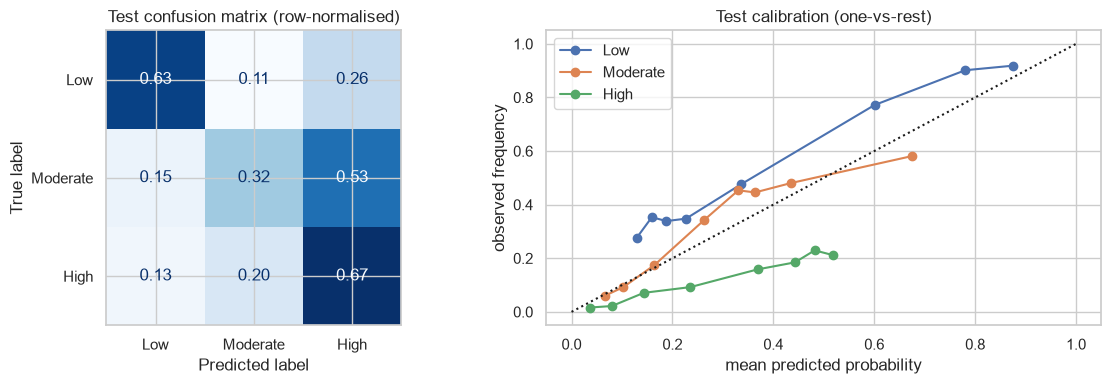


by session:


,n,actual High %,accuracy,macro_F1,PR AUC
group,,,,,
2105,334,17.7,0.398,0.307,0.407
2847,344,12.5,0.358,0.361,0.467
7241,244,17.6,0.541,0.506,0.511
8936,305,3.3,0.852,0.424,0.433
9184,242,10.7,0.554,0.379,0.494



by Time of Day:


,n,actual High %,accuracy,macro_F1,PR AUC
group,,,,,
afternoon,419,11.2,0.473,0.442,0.497
evening,351,10.0,0.601,0.464,0.524
morning,368,15.2,0.473,0.459,0.537
night,331,13.0,0.601,0.401,0.520



by HVAC mode (cleaned):


,n,actual High %,accuracy,macro_F1,PR AUC
group,,,,,
cooling_active,272,11.4,0.471,0.425,0.494
eco_mode,229,9.6,0.515,0.469,0.518
heating_active,247,12.6,0.522,0.454,0.540
maintenance_mode,253,14.2,0.613,0.572,0.608
off,225,13.8,0.511,0.459,0.508
ventilation_only,243,12.3,0.564,0.497,0.530


In [51]:
Pt = probas[TUNED_KEY]; pred_t = np.asarray(SK_CLASSES)[Pt.to_numpy().argmax(1)]
print(classification_report(y_te, pred_t, labels=CLASSES, digits=3)); print("predicted shares:", pd.Series(pred_t).value_counts(normalize=True).reindex(CLASSES).round(3).to_dict(), "| actual:", y_te.value_counts(normalize=True).reindex(CLASSES).round(3).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ConfusionMatrixDisplay.from_predictions(y_te, pred_t, labels=CLASSES, normalize="true", cmap="Blues", values_format=".2f", ax=ax[0], colorbar=False); ax[0].set_title("Test confusion matrix (row-normalised)")
for c in CLASSES:
    fp_, mp_ = calibration_curve((y_te == c).astype(int), Pt[c], n_bins=8, strategy="quantile"); ax[1].plot(mp_, fp_, "o-", label=c)
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("mean predicted probability"); ax[1].set_ylabel("observed frequency"); ax[1].legend(); ax[1].set_title("Test calibration (one-vs-rest)"); plt.tight_layout(); plt.savefig(OUT / "figures" / "test_diagnostics.png", dpi=120); plt.show()
def breakdown(by):
    rows = []
    for k, idx in pd.Series(range(len(y_te)), index=by.values).groupby(level=0):
        i = idx.to_numpy(); yy, pp = y_te.iloc[i], pred_t[i]
        rows.append({"group": k, "n": len(i), "actual High %": round(100 * (yy == "High").mean(), 1), "accuracy": accuracy_score(yy, pp), "macro_F1": f1_score(yy, pp, labels=CLASSES, average="macro", zero_division=0),
                     "PR AUC": pr_auc_macro(yy, Pt.to_numpy()[i], SK_CLASSES) if yy.nunique() == 3 else np.nan})
    return pd.DataFrame(rows).set_index("group").round(3)
for title, by in [("session", X_te[GROUP]), ("Time of Day", X_te["Time of Day"]), ("HVAC mode (cleaned)", X_te["HVAC Operation Mode"].str.strip().str.lower())]:
    print(f"\nby {title}:"); display(breakdown(by))

**Observation / implication.** Per class on test: Low precision 0.84 / recall 0.63, Moderate 0.55 / 0.32, **High 0.21 / 0.67**. Because of class weighting the model labels 39.8% of rows High (actual 12.3%), Low 41% (actual 54.8%) and Moderate 19% (actual 32.9%); 53% of Moderate rows are labelled High, so Moderate is the weakest class and High alerts are mostly false (precision 0.21). Calibration is distorted by the class weights: a predicted High probability of 0.5 corresponds to about 21% observed, and Low is under-predicted; the probabilities are usable for ranking, not as risk estimates, and need recalibration before display. Breakdowns show **large session heterogeneity**: PR AUC 0.41-0.51 and macro-F1 0.31-0.51 across the five test sessions (accuracy 0.36-0.85; session 8936 has only 3.3% High). By Time of Day PR AUC is 0.50-0.54; the HVAC differences (0.49-0.61) concern a feature with no signal and cells of ~230-270 rows, so they are sampling noise, not findings.

## 37. Sensitivity checks (VALIDATION data only)
**Purpose.** Probe how fragile the selected model's validation score is, without touching the test set: later vs earlier rows inside each validation session (time order), preprocessing variants (engineered features, noise features, missing flags, class weighting, the suspect Session ID) with the tuned parameters held fixed, and a class-prior weight for High.

In [52]:
def pipeline_variant(engineered, add_flags, drop_columns):
    def _cat(df): return [c for c in CATEGORICAL if c in df.columns]
    num = Pipeline([("winsor", Winsorizer((0.01, 0.99))), ("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    return Pipeline([("clean", DataCleaner(drop_columns=drop_columns, ordinal_maps=ORDINAL_MAPS, add_missing_indicators=add_flags, indicator_columns=tuple(FLAG_SOURCES))), ("engineer", FeatureEngineer(features=tuple(engineered))),
        ("columns", ColumnTransformer([("num", num, _numeric_columns), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), _cat), ("flags", "passthrough", _flag_columns)], verbose_feature_names_out=False))])
def variant_model(engineered=("temp_x_humidity", "co2_z_gap"), add_flags=True, drop_columns=(GROUP,), unweighted=False):
    m = Pipeline([("prep", pipeline_variant(engineered, add_flags, drop_columns)), ("clf", MODEL_REGISTRY[best_name]())]); fixed = dict(TUNED_FIXED[best_name])
    if unweighted: fixed.pop("class_weight", None)
    m.set_params(**{f"clf__{k}": v for k, v in fixed.items()}, **best_params); return m
VARIANTS = {"as selected (reference)": {}, "no engineered features": {"engineered": ()}, "+ mos_pc1": {"engineered": ("temp_x_humidity", "co2_z_gap", "mos_pc1")},
            "drop HVAC, Time of Day, Ambient Light": {"drop_columns": (GROUP, "HVAC Operation Mode", "Time of Day", "Ambient Light Level")}, "no missing-indicator flags": {"add_flags": False},
            "no class weighting": {"unweighted": True}, "SUSPECT ON: Session ID as feature": {"drop_columns": ()}}
rows = []
for label, kw in VARIANTS.items():
    m = variant_model(**kw).fit(X_tr, y_tr); s = score_all(m, X_va, y_va); rows.append({"variant": label, "n_features": int(m.named_steps["prep"].transform(X_tr.iloc[:5]).shape[1]), "val_pr_auc": s["pr_auc_macro"], "val_f1_macro": s["f1_macro"], "val_roc_auc": s["roc_auc_macro"]})
SV = pd.DataFrame(rows).set_index("variant"); SV["delta_pr_auc_vs_ref"] = SV["val_pr_auc"] - SV.loc["as selected (reference)", "val_pr_auc"]; display(SV.round(4))
# time order: early vs late rows inside every validation session (rows are time-ordered within a session)
Pv = TUNED[best_name]["model"].predict_proba(X_va); pos = pd.Series(np.arange(len(X_va)), index=X_va.index); rank_in_sess = X_va.groupby(GROUP).cumcount() / X_va.groupby(GROUP)[GROUP].transform("size"); late = (rank_in_sess >= 0.5).to_numpy()
tt = pd.DataFrame({half: {"n": int(msk.sum()), "pr_auc": pr_auc_macro(y_va[msk], Pv[msk], SK_CLASSES), "macro_f1": f1_score(y_va[msk], np.asarray(SK_CLASSES)[Pv[msk].argmax(1)], average="macro", zero_division=0)} for half, msk in [("early half of each session", ~late), ("late half of each session", late)]}).T; display(tt.round(4))
# class-prior weight for High (decision rule, validation only)
w_rows = []
for w in [1, 1.5, 2, 3, 4, 6]:
    Pw = Pv * np.array([w if c == "High" else 1.0 for c in SK_CLASSES]); pw = np.asarray(SK_CLASSES)[Pw.argmax(1)]; hi = (y_va == "High").to_numpy()
    w_rows.append({"weight on High": w, "macro_F1": f1_score(y_va, pw, average="macro", zero_division=0), "High recall": recall_score(y_va == "High", pw == "High"), "High precision": precision_score(y_va == "High", pw == "High", zero_division=0), "share predicted High": float((pw == "High").mean())})
display(pd.DataFrame(w_rows).set_index("weight on High").round(3)); print("(a decision-rule lever for deployment; not used for the reported test result)")

,n_features,val_pr_auc,val_f1_macro,val_roc_auc,delta_pr_auc_vs_ref
variant,,,,,
as selected (reference),28,0.5393,0.5070,0.7734,0.0000
no engineered features,26,0.5409,0.5178,0.7774,0.0016
+ mos_pc1,29,0.5434,0.5040,0.7750,0.0040
"drop HVAC, Time of Day, Ambient Light",17,0.5356,0.5042,0.7763,-0.0037
no missing-indicator flags,22,0.5425,0.5103,0.7737,0.0031
no class weighting,28,0.5346,0.4688,0.7761,-0.0047
SUSPECT ON: Session ID as feature,29,0.5409,0.5019,0.7755,0.0016


,n,pr_auc,macro_f1
early half of each session,735.0,0.5311,0.5113
late half of each session,733.0,0.5507,0.4941


,macro_F1,High recall,High precision,share predicted High
weight on High,,,,
1.0,0.507,0.736,0.196,0.369
1.5,0.478,0.833,0.185,0.443
2.0,0.450,0.847,0.171,0.486
3.0,0.432,0.882,0.162,0.533
4.0,0.412,0.910,0.156,0.574
6.0,0.366,0.958,0.142,0.660


(a decision-rule lever for deployment; not used for the reported test result)


**Observation / implication.** On validation, **no variant changes the PR AUC by more than 0.005**, below the noise (~0.01): dropping the engineered features (+0.002), adding `mos_pc1` (+0.004), dropping HVAC/Time of Day/Ambient Light (-0.004, 17 instead of 28 features), dropping the missing flags (+0.003) and adding the suspect Session ID (+0.002) are all indistinguishable from the reference; the engineered features, flags and noise columns are therefore not needed. Removing class weights lowers PR AUC only slightly (-0.005) but macro-F1 clearly (0.507 -> 0.469). Early vs late rows within each session score alike (PR AUC 0.531 vs 0.551, macro-F1 0.511 vs 0.494, n about 735 each): no consistent temporal drift. Weighting High further (1 -> 6) lifts High recall from 0.74 to 0.96 but lowers precision from 0.20 to 0.14 and macro-F1 from 0.51 to 0.37: the model already over-calls High, and any alert threshold is a deployment decision about the false-alarm cost.

## 38. Save artifacts and verify the saved model
**Purpose.** Write the result tables, best parameters, search spaces, split IDs, test predictions with IDs, the final fitted model and a run manifest to `./outputs`, then check that the reloaded model reproduces the stored test predictions.

In [53]:
import sys
TT.to_csv(OUT / "tuned_results.csv"); TT.reset_index().to_json(OUT / "tuned_results.json", orient="records", indent=1)
json.dump({n: p["best_params"] for n, p in TUNED.items()}, open(OUT / "best_params.json", "w"), indent=1, default=str)
json.dump({n: {k: [str(x) for x in v] for k, v in sp.items()} | {"tuned_fixed": {k: str(v) for k, v in TUNED_FIXED[n].items()}, "search": SEARCH_KIND[n]} for n, sp in SPACES.items()}, open(OUT / "search_spaces.json", "w"), indent=1)
final_metrics.to_csv(OUT / "final_test_results.csv")
json.dump({"selected_model": best_name, "best_params": {k: str(v) for k, v in best_params.items()}, "metrics": final_metrics.to_dict(), "ci95_bootstrap": {k: {"pr_auc_macro": ci(boot[k]["pr"]), "f1_macro": ci(boot[k]["f1"])} for k in boot}, "paired_improvement": PAIRED,
           "validation_pr_auc_selected": float(TT.loc[best_name, "tuned_val_pr_auc"])}, open(OUT / "final_test_results.json", "w"), indent=1, default=str)
pred_out = probas[TUNED_KEY].copy(); pred_out.insert(0, "predicted", pred_t); pred_out.insert(0, "actual", y_te.to_numpy()); pred_out.insert(0, "session_id", X_te[GROUP].to_numpy()); pred_out.index.name = "row_id"; pred_out.to_csv(OUT / "final_test_predictions.csv")
json.dump({"split_seed": int(SPLIT_SEED), "train_row_ids": [int(i) for i in tr], "validation_row_ids": [int(i) for i in va], "test_row_ids": [int(i) for i in te], "train_sessions": sorted(int(s) for s in groups.iloc[tr].unique()),
           "validation_sessions": sorted(int(s) for s in groups.iloc[va].unique()), "test_sessions": sorted(int(s) for s in groups.iloc[te].unique())}, open(OUT / "split_ids.json", "w"))
joblib.dump(final_models[TUNED_KEY], OUT / "final_model.joblib")
reloaded = joblib.load(OUT / "final_model.joblib"); same = np.allclose(reloaded.predict_proba(X_te), probas[TUNED_KEY].to_numpy()); print("reloaded final model reproduces the stored test predictions:", same); assert same
manifest = {"python": sys.version.split()[0], "platform": platform.platform(), "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "scipy": scipy.__version__, "joblib": joblib.__version__,
            "seed": SEED, "split_seed": int(SPLIT_SEED), "config": CFG, "cpu_cores": os.cpu_count(), "n_jobs": CFG["n_jobs"], "data_sha256": hashlib.sha256(open(DB_PATH, "rb").read()).hexdigest(),
            "search_seconds": {n: round(p["search_s"], 1) for n, p in TUNED.items()}, "refit_seconds": {n: round(p["refit_s"], 1) for n, p in TUNED.items()}, "cell_wall_seconds": {k: round(v, 1) for k, v in TIMINGS.items()},
            "ledger_entries": {k: {"fingerprint": v["fingerprint"], "saved": v["saved"]} for k, v in ledger.data.items()}, "part_c_wall_seconds": round(time.time() - RUN_T0, 1), "finished": time.strftime("%Y-%m-%d %H:%M:%S")}
(OUT / "README.md").write_text("""# Phase 1C artifacts (written by eda.ipynb, Part C)

| File | Content |
|---|---|
| baseline_results.csv | default-parameter baselines (validation, written in Part B) |
| tuned_results.csv / .json | tuned vs baseline on validation, CV fold SD, verdicts |
| best_params.json, search_spaces.json | winning parameters and the searched spaces (incl. tuned-path settings) |
| cv_results/<model>.csv | full cross-validation tables of each search |
| feature_importance_tuned.csv | permutation importance of every tuned model (validation) |
| final_test_results.csv / .json | test metrics (tuned model, default twin, naive), bootstrap 95% CIs, paired improvements |
| final_test_predictions.csv | test predictions with row_id, session_id, actual, predicted and class probabilities |
| split_ids.json | row ids and session ids of train / validation / test |
| final_model.joblib | the selected pipeline refit on train+validation |
| run_manifest.json | library versions, seed, compute settings, data SHA-256, timings, ledger fingerprints |
| nb_ledger.json, checkpoints/ | checkpoint ledger (keys stage::model); only to survive an interrupted run |
| figures/ | tuned_vs_baseline.png, importance_tuned.png, test_diagnostics.png |

Files from the scripted pipeline (`main.py`: baselines.csv, tuned_vs_baseline.csv, test_results.json, test_predictions.csv, feature_importance.csv, ledger.json, models/) are separate and use the older src/ configuration.
""", encoding="utf-8")
json.dump(manifest, open(OUT / "run_manifest.json", "w"), indent=1, default=str); print("data SHA-256:", manifest["data_sha256"][:16], "... | artifacts:", sorted(p.name for p in OUT.iterdir()))

reloaded final model reproduces the stored test predictions: True
data SHA-256: a28e647f84c225d4 ... | artifacts: ['README.md', 'baseline_results.csv', 'baselines.csv', 'best_params.json', 'checkpoints', 'cv_results', 'feature_importance.csv', 'feature_importance_tuned.csv', 'figures', 'final_model.joblib', 'final_test_predictions.csv', 'final_test_results.csv', 'final_test_results.json', 'full_run.log', 'ledger.json', 'models', 'nb_ledger.json', 'notebook_baselines.json', 'run_manifest.json', 'search_spaces.json', 'split_ids.json', 'test_predictions.csv', 'test_results.json', 'tuned_results.csv', 'tuned_results.json', 'tuned_vs_baseline.csv']


**Observation / implication.** All artifacts were written, including the final fitted model, test predictions with row and session IDs, split IDs and a run manifest with versions, seed, compute settings and the SHA-256 of the data file. The reloaded `final_model.joblib` reproduces the stored test predictions exactly. The ledger holds the six keys `tuned::<model>` and `final::test` that were all computed in this run.

## 39. Closing summary: baseline -> tuned -> final test
**Final model:** histogram gradient boosting, selected by the pre-declared rule (highest validation macro PR AUC among tuned models), parameters: learning rate 0.05, max_iter 100, depth 3, 8 leaves, `min_samples_leaf` 20, L2 0, balanced class weights; refit on train+validation.

| Stage | Macro PR AUC | Macro-F1 |
|---|---|---|
| Baseline (library defaults, validation) | 0.519 | 0.468 |
| Tuned (validation) | 0.539 | 0.507 |
| **Final, test (evaluated once)** | **0.525 (95% CI 0.505-0.549)** | **0.480 (0.455-0.504)** |
| Default twin, test | 0.504 | 0.430 |
| Naive, test | 0.333 | 0.236 |

**What tuning did and did not change.** It helped the models with poor defaults (decision tree +0.125, kNN +0.058 on validation) and the selected boosting model modestly (+0.020 validation; +0.021 on test with CI 0.003-0.038, which only just excludes zero). It did **not** help random forest (-0.004) or logistic regression (+0.004), both within noise. It did not change the broad picture: the top four tuned models are within 0.014 of each other on validation, so the winner is not statistically established, and tuning mainly shifted the decision rule (class weights raise macro-F1 but lower accuracy to 0.532, below the naive 0.548).

**Key caveats.** (1) Validation and test contain only 5 sessions each; test PR AUC varies from 0.41 to 0.51 across the test sessions, and the bootstrap CIs ignore this. (2) Class weighting makes the model call High on 39.8% of rows (actual 12.3%), giving High precision 0.21; probabilities are miscalibrated and Moderate is the weakest class (recall 0.32). (3) Search was subsample-based (4,050 rows) with a quick grid; boosting and kNN best values sit at grid edges. (4) One split, one seed; no repeated grouped CV. (5) Test result is slightly below validation (0.525 vs 0.539), consistent with selection optimism. (6) The EDA's causal link to health emergencies remains an assumption; the model recognises activity, it does not forecast emergencies.

**Features that matter:** MetalOxideSensor_Unit4 (clearly), then Temperature, MetalOxideSensor_Unit2 and CO2 electrochemical; HVAC mode, Time of Day and Ambient Light contribute nothing measurable. Sensitivity checks show the engineered features, missing flags and noise columns can be dropped without loss.

## 40. Artifacts index
All files are in `./outputs` (see `outputs/README.md`): `baseline_results.csv`, `tuned_results.csv/.json`, `best_params.json`, `search_spaces.json`, `cv_results/<model>.csv`, `feature_importance_tuned.csv`, `final_test_results.csv/.json`, `final_test_predictions.csv` (with row_id, session_id, class probabilities), `split_ids.json`, `final_model.joblib`, `run_manifest.json`, `nb_ledger.json` + `checkpoints/`, and `figures/` (tuned_vs_baseline, importance_tuned, test_diagnostics). The older files from the scripted pipeline (`main.py`) in the same folder are separate and use the earlier `src/` configuration.

## Glossary
- **Eta-squared:** share of a feature's variance explained by group (class) membership; 0.01 small, 0.06 medium, 0.14 large (rule of thumb).
- **Pearson / Spearman:** linear vs rank-based (monotonic) correlation; a larger Spearman signals monotonic non-linearity or outlier masking.
- **Cramer's V:** 0-1 association between two categorical variables derived from chi-square.
- **Chi-square / ANOVA F / Kruskal-Wallis H:** tests for association/mean difference/rank difference; with n ~10,000 they are almost always significant, so effect sizes are used to judge importance.
- **Mutual information (MI):** non-linear dependence between a feature and the target, in nats; MI/H(y) is its share of the target entropy.
- **Rank-biserial correlation:** effect size of a Mann-Whitney test (-1 to 1; 0 = no difference).
- **Cohen's d:** standardised mean difference (0.2 small, 0.5 medium, 0.8 large).
- **Tukey HSD:** pairwise mean comparisons across groups controlling the family-wise error.
- **Levene's test:** tests equal variance across groups.
- **MCAR:** missing completely at random: missingness unrelated to any data.
- **ICC (session):** share of variance between sessions (eta-squared by session).
- **Grouped CV:** cross-validation keeping all rows of a session in the same fold; **shuffled-label null:** score with randomly permuted labels = chance level.
- **Skewness / kurtosis:** asymmetry / tail weight (excess kurtosis 0 = normal).
- **IQR rule:** outlier if beyond 1.5 x IQR from the quartiles.
- **Winsorising:** clipping values to given percentiles.
- **Isolation Forest:** unsupervised multivariate outlier detector.
- **Learning curve:** score vs training size, showing whether more data would help.
- **Macro PR AUC / macro-F1:** per-class precision-recall area / F1, averaged with equal class weight.
- **Transformer / Pipeline / ColumnTransformer:** scikit-learn objects that learn from data in `fit` and apply it in `transform`; chaining them in one Pipeline guarantees statistics come from training rows only.
- **Naive (prior) baseline:** always predicts the training class frequencies; it sets the floor (macro PR AUC = 1/3 here).
- **Train-vs-validation gap:** training score minus validation score; a large gap means overfitting.
- **Permutation importance:** drop in a metric when one input column is randomly shuffled.
- **Calibration (reliability) curve:** observed frequency vs predicted probability; the diagonal is perfect calibration.
- **Kolmogorov-Smirnov (KS) test:** compares two distributions; here the class-code distribution of two splits.
- **Group split:** train/validation/test partition where all rows of a session stay together.
- **Successive halving:** a search that evaluates many candidates on small data subsamples and keeps the best third for larger subsamples.
- **Checkpoint ledger:** a JSON/pickle record per finished stage (`stage::model`) with a settings fingerprint, reused only if the settings match.
- **Paired bootstrap:** resample the test rows once and compute both models on the same resample, so the difference has a CI that reflects the pairing.
- **Class weighting (`balanced`):** upweights rare classes during training; raises minority recall and macro-F1, lowers accuracy and distorts probabilities.
- **Selection optimism:** the winner of a comparison tends to score better on the data used to pick it than on fresh data.